# Connect Forest Management Model with Forest Carbon Budget Model

In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
import ws3.forest
import time
import gurobipy as grb
import pickle
import libcbm
import os
from util_opt import compile_events, cbm_report, compile_scenario_maxstock, plot_scenario_maxstock, run_cbm_emissionstock, run_scenario, plugin_c_curves, plugin_c_curves_both, cbm_report_both, compare_ws3_cbm, compare_ws3_cbm_both, track_system_stock, track_system_emission, compile_scenario_minemission, plot_scenario_minemission, kpi_age, kpi_species, cmp_c_ss, cmp_c_se, results_scenarios, bootstrap_ogi, compare_kpi_age

In [2]:
base_year = 2020
horizon = 10
period_length = 10
max_age = 1000
n_steps = 100
tvy_name = 'totvol'
max_harvest = 1.0

In [3]:
# Define scenario options based on case study
scenario_options = {
    'redchris': ['no_cons','evenflow_cons', 'redchrs_AAC_90%', 'redchrs_AAC_80%', 'redchrs_AAC_70%', 'redchrs_AAC_60%', 'redchrs_AAC_50%', 'redchrs_AAC_40%', 'redchrs_AAC_30%', 'redchrs_AAC_20%', 'redchrs_AAC_10%' ],
    'goldenbear': ['no_cons', 'evenflow_cons', 'gldbr_AAC_90%', 'gldbr_AAC_80%', 'gldbr_AAC_70%', 'gldbr_AAC_60%', 'gldbr_AAC_50%', 'gldbr_AAC_40%', 'gldbr_AAC_30%', 'gldbr_AAC_20%', 'gldbr_AAC_10%'],
    'equitysilver': [ 'no_cons','evenflow_cons', 'eqtslvr_AAC_90%', 'eqtslvr_AAC_80%', 'eqtslvr_AAC_70%', 'eqtslvr_AAC_60%', 'eqtslvr_AAC_50%', 'eqtslvr_AAC_40%', 'eqtslvr_AAC_30%', 'eqtslvr_AAC_20%', 'eqtslvr_AAC_10%'],
    'test': ['no_cons', 'evenflow_cons', 'bau_redchrs']
}

# Function to handle case study selection and update scenario dropdown
def select_case_study(case_study):
    print(f"Selected case study: {case_study}")
    # Update the scenario dropdown based on the selected case study
    scenario_dropdown.options = scenario_options.get(case_study, [])
    scenario_dropdown.value = scenario_options[case_study][0]  # Set a default value

# Case study dropdown
case_study_dropdown = widgets.Dropdown(
    options=['redchris', 'goldenbear', 'equitysilver', 'test'],
    value='equitysilver',
    description='Case Study:'
)
case_study_dropdown.observe(lambda change: select_case_study(change['new']), names='value')
display(case_study_dropdown)

# Function to handle scenario selection
def select_scenario(scenario_name):
    print(f"Selected scenario: {scenario_name}")

# Scenario dropdown
scenario_dropdown = widgets.Dropdown(
    options=scenario_options['redchris'],  # Set initial options based on default case study
    value=scenario_options['redchris'][1],  # Set initial value
    description='Scenario:'
)
scenario_dropdown.observe(lambda change: select_scenario(change['new']), names='value')
display(scenario_dropdown)

# Function to handle objective functon
def select_obj(obj_mode):
    print(f"Selected objective: {obj_mode}")
obj_dropdown = widgets.Dropdown(
    options=['max_hv', 'min_ha', 'max_st', 'min_em'],
    value='min_em',
    description='Objective:'
)
display(obj_dropdown)
obj_dropdown.observe(lambda change: select_obj(change['new']), names='value')

Dropdown(description='Case Study:', index=2, options=('redchris', 'goldenbear', 'equitysilver', 'test'), value…

Dropdown(description='Scenario:', index=1, options=('no_cons', 'evenflow_cons', 'redchrs_AAC_90%', 'redchrs_AA…

Dropdown(description='Objective:', index=3, options=('max_hv', 'min_ha', 'max_st', 'min_em'), value='min_em')

In [4]:
# Initialize main widget components 
hwp_pool_effect = widgets.FloatSlider(min=0, max=1, step=1, description='HWP_effect', value=1, layout=widgets.Layout(margin='10px 0'))
release_immediately = widgets.FloatSlider(min=0, max=1, step=1, description='Release immediately', value=1, layout=widgets.Layout(margin='10px 0'))
displacement_effect = widgets.FloatSlider(min=0, max=1, step=1, description='Displacement', value=1, layout=widgets.Layout(margin='10px 0'))
clt_percentage = widgets.FloatSlider(min=0, max=1, step=0.1, description='CLT_percent:', value=0.5, layout=widgets.Layout(margin='10px 0'))
credibility = widgets.FloatSlider(min=0, max=1, step=0.1, description='Credibility:', value=1, layout=widgets.Layout(margin='10px 0'))
# max_harvest = widgets.FloatSlider(min=0, max=1, step=0.05, description='Max_harvest:', value=1.0, layout=widgets.Layout(margin='10px 0'))
budget_input = widgets.FloatText(value=10000000, description='Budget:', layout=widgets.Layout(margin='10px 0'))

release_immediately.layout.display = 'none' if hwp_pool_effect.value != 0 else 'block'
displacement_effect.layout.display = 'block' if hwp_pool_effect.value != 0 else 'none'
clt_percentage.layout.display = 'block' if hwp_pool_effect.value != 0 and displacement_effect.value != 0 else 'none'
credibility.layout.display = 'block' if hwp_pool_effect.value != 0 and displacement_effect.value != 0 else 'none'

container = widgets.VBox([
    hwp_pool_effect, release_immediately, displacement_effect, clt_percentage, credibility, budget_input  
    # ,max_harvest
])

display(container)

def update_widgets(change):
    hwp_pool_effect_value = hwp_pool_effect.value
    displacement_effect_value = displacement_effect.value

    release_immediately.layout.display = 'block' if hwp_pool_effect_value == 0 else 'none'
    displacement_effect.layout.display = 'block' if hwp_pool_effect_value != 0 else 'none'

    clt_percentage.layout.display = 'block' if hwp_pool_effect_value != 0 and displacement_effect_value != 0 else 'none'
    credibility.layout.display = 'block' if hwp_pool_effect_value != 0 and displacement_effect_value != 0 else 'none'

hwp_pool_effect.observe(update_widgets, names='value')
displacement_effect.observe(update_widgets, names='value')

In [5]:
#Start Calculating the Running Time
Start = time.time()

In [6]:
case_study = case_study_dropdown.value
scenario_name = scenario_dropdown.value
obj_mode = obj_dropdown.value
hwp_pool_effect_value = hwp_pool_effect.value
release_immediately_value = release_immediately.value if hwp_pool_effect_value == 0 else 0
displacement_effect = displacement_effect.value if hwp_pool_effect_value != 0 else 0
clt_percentage = clt_percentage.value if displacement_effect != 0 else 0
credibility = credibility.value if displacement_effect != 0 else 0
# max_harvest = max_harvest.value
budget_input = budget_input.value

In [7]:
# Define case study mappings and retrieve model details based on case study
case_study_options = {
    'redchris': {
        'model_name': 'redchris',
        'model_path': './data/woodstock_model_files_redchris'
    },
    'goldenbear': {
        'model_name': 'goldenbear',
        'model_path': './data/woodstock_model_files_goldenbear'
    },
    'equitysilver': {
        'model_name': 'equitysilver',
        'model_path': './data/woodstock_model_files_equitysilver'
    },
    'test': {
        'model_name': 'redchris',
        'model_path': './data/woodstock_model_files_redchris_test'
    }
}

model_info = case_study_options.get(case_study)

if model_info:
    model_name = model_info['model_name']
    model_path = model_info['model_path']
else:
    print('The case study name is not valid')


In [8]:
# Create and Run `ForestModel` instance
fm = ws3.forest.ForestModel(model_name=model_name,
                            model_path=model_path,
                            base_year=base_year,
                            horizon=horizon,
                            period_length=period_length,
                            max_age=max_age)
fm.import_landscape_section()
fm.import_areas_section()
fm.import_yields_section()
fm.import_actions_section()
fm.import_transitions_section()
fm.initialize_areas()
fm.add_null_action()
fm.reset_actions()
fm.grow()

In [9]:
# Flag 'harvest' as a harvesting action in the ws3 model
harvest_acode='harvest'
fm.actions[harvest_acode].is_harvest = True

In [10]:
# Read curves
file_directory = "./inputs/curves"
file_names = [f"{case_study}_c_curves_p.pkl", f"{case_study}_c_curves_f.pkl"]
loaded_data = {}

for filename in file_names:
    file_path = os.path.join(file_directory, filename)
    with open(file_path, 'rb') as file:
        loaded_data[filename] = pickle.load(file)
    print(f"Loaded data from {file_path}")

c_curves_p = loaded_data.get(f"{case_study}_c_curves_p.pkl")
c_curves_f = loaded_data.get(f"{case_study}_c_curves_f.pkl")

Loaded data from ./inputs/curves/equitysilver_c_curves_p.pkl
Loaded data from ./inputs/curves/equitysilver_c_curves_f.pkl


In [11]:
# Plug carbon and old groth yield curves into forest model
plugin_c_curves_both(fm, c_curves_p, c_curves_f)
bootstrap_ogi(fm)

Running for equitysilver_min_em_no_cons...
running no_cons scenario
Set parameter Username
Academic license - for non-commercial use only - expires 2025-01-09
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17023 rows, 83258 columns and 83258 nonzeros
Model fingerprint: 0x60168b7a
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]
Presolve removed 17023 rows and 83258 columns
Presolve time: 0.07s
Presolve: All rows and columns removed
Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0   -3.9333305e+07   0.000000e+00   0.000000e+00      0s

Solved in 0 iterations and 0.09 seconds (0.03 work units)
Optimal objective -3.933330543e+07


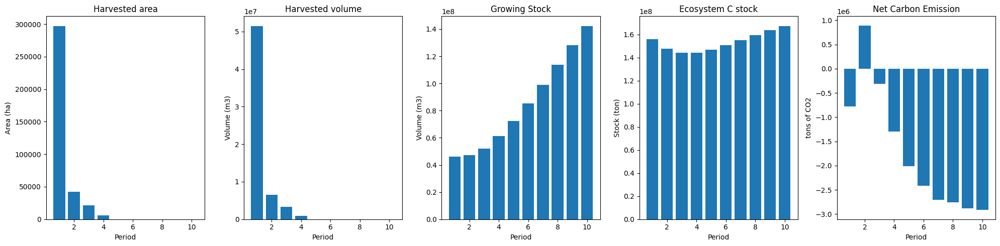

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_no_cons_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  65647
The economic indicator (the provincial government revenues) is:  2238735
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


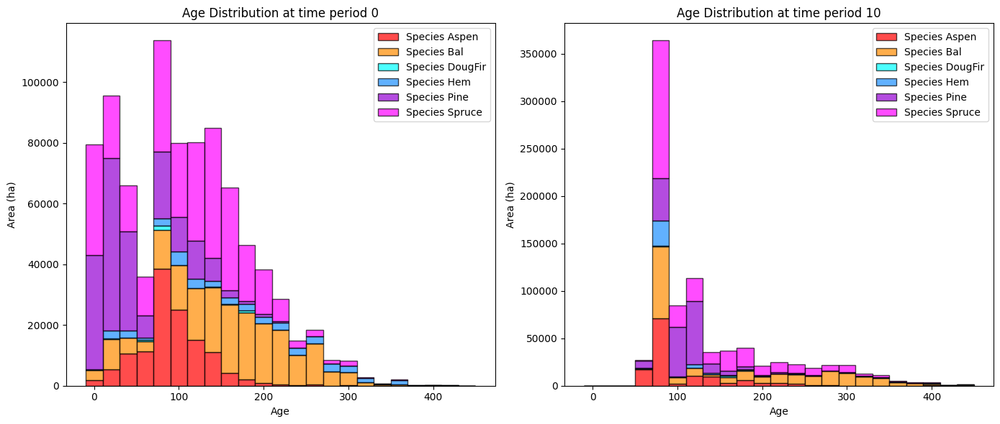

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_no_cons_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0            10    Difference
Hem      19152.127229   7612.420986 -11539.706243
DougFir    947.047810   1458.489527    511.441717
Bal      59315.970469  86596.028905  27280.058436
Spruce   36410.744598  75979.778849  39569.034251
Aspen    29632.731169  31534.125905   1901.394736
Pine      7432.733686  25931.899819  18499.166132

Overall diversity has **increased** by 76221.39 hectares from time period 0 to time period 10.


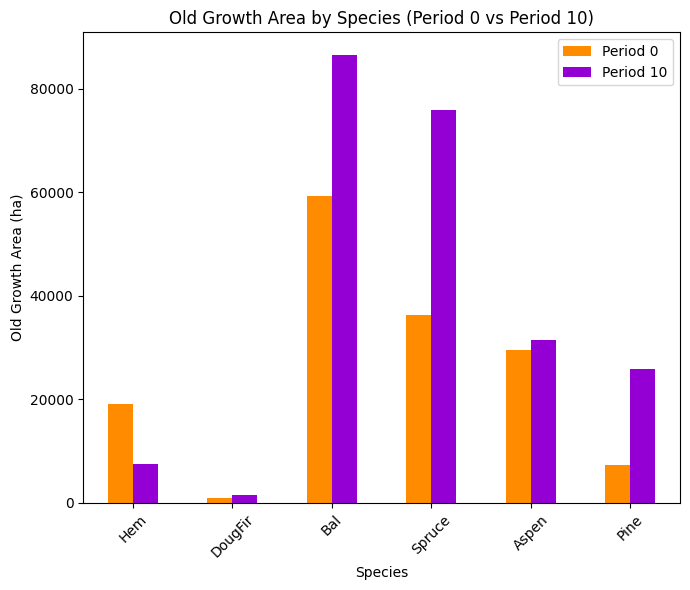

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_no_cons_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7371

Diversity has **decreased** by 2.21% from time 0 to time 10.


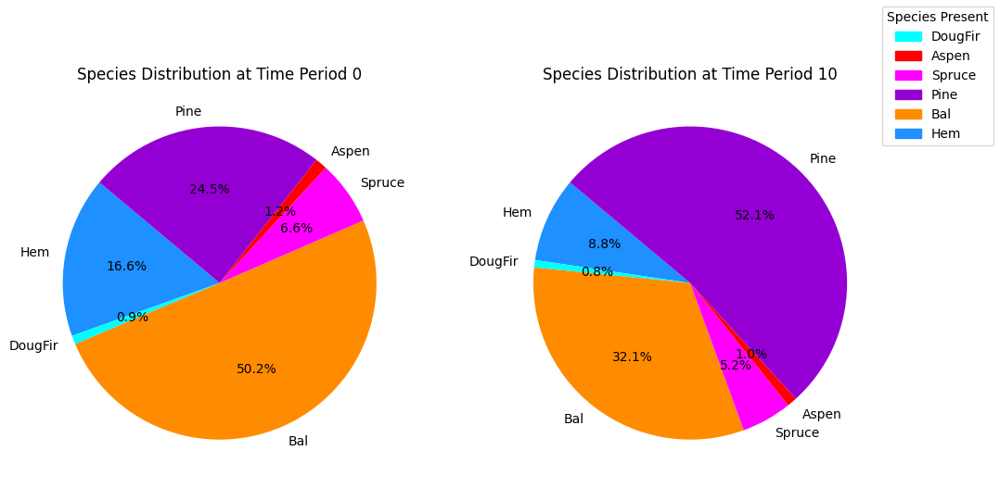

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_no_cons_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x67e9da31
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.31s
Presolved: 8375 rows, 74375 columns, 536310 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering t

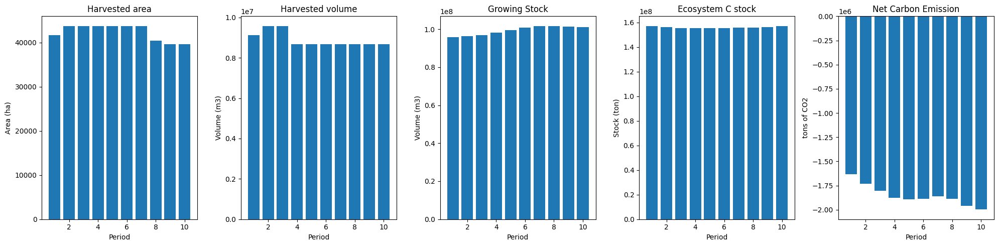

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


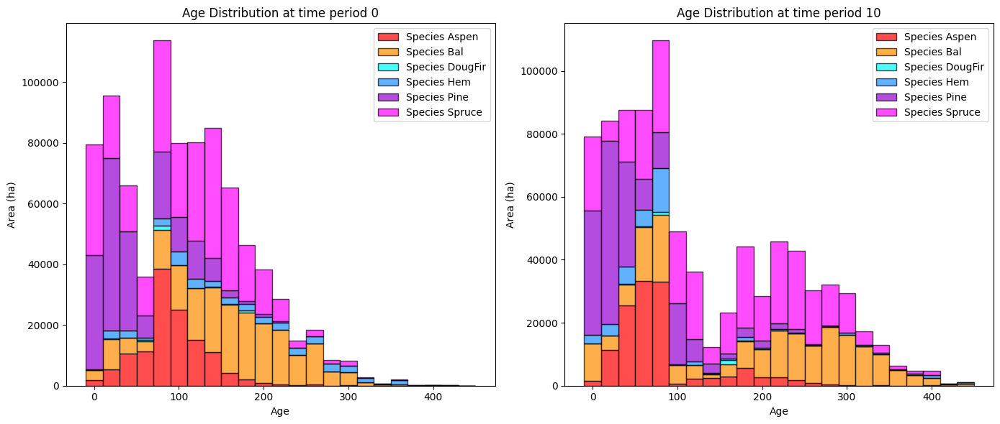

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    6279.556292 -12872.570937
DougFir    947.047810    1312.466058    365.418248
Bal      59315.970469  108811.384782  49495.414314
Spruce   36410.744598  134653.193927  98242.449329
Aspen    29632.731169   20687.141690  -8945.589480
Pine      7432.733686    9982.874965   2550.141279

Overall diversity has **increased** by 128835.26 hectares from time period 0 to time period 10.


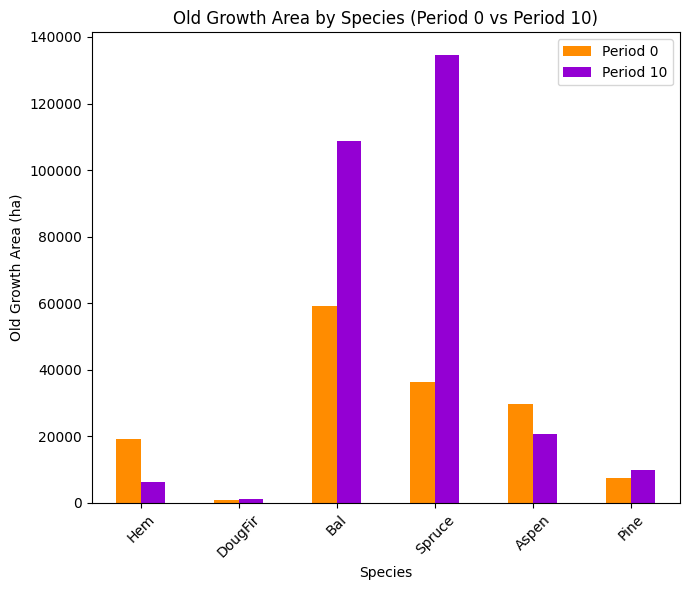

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7128

Diversity has **decreased** by 4.64% from time 0 to time 10.


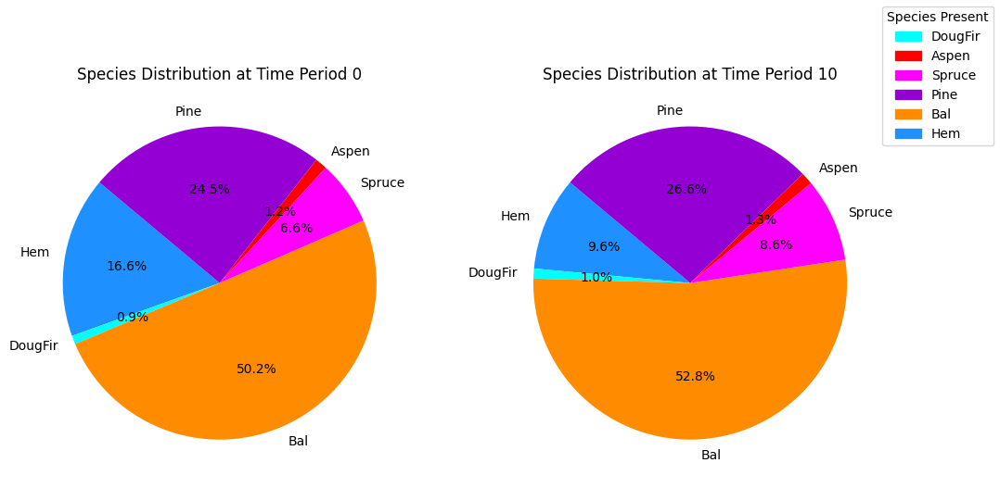

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_species_pie.pdf


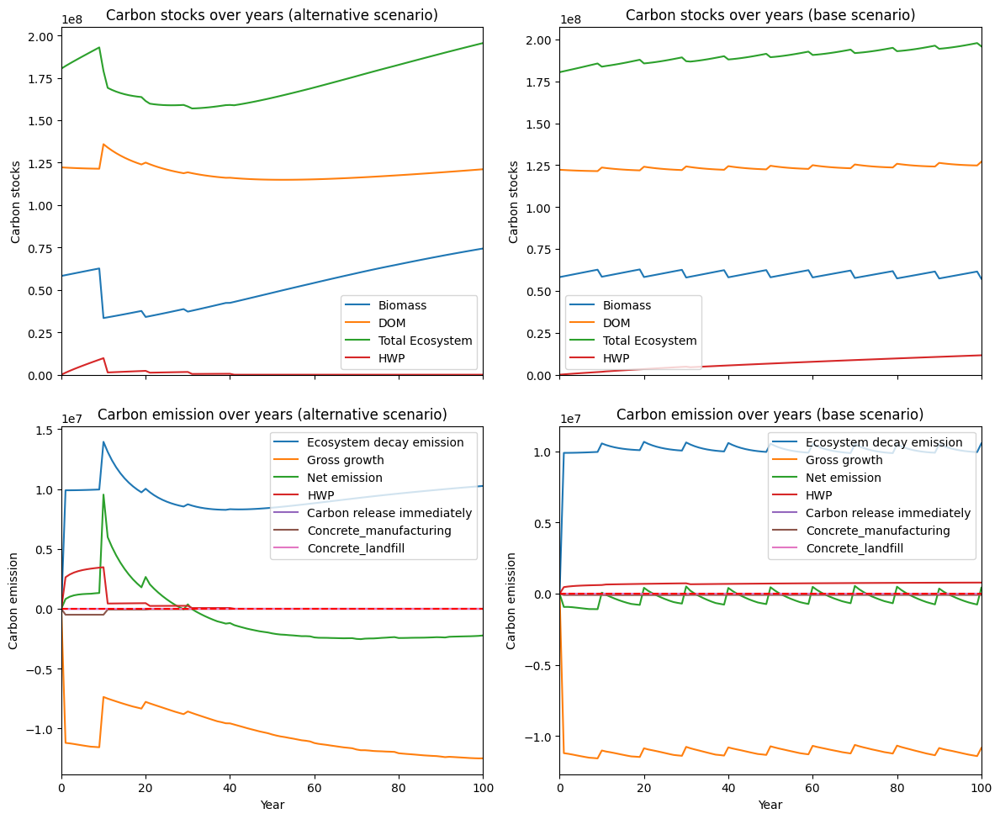

---------------------------------------------------------------------------------------
Net emission difference 74020345.35052101
Net emission base scenario 60849804.6723212
Net emission alternative scenario -13170540.67819982
dollar_per_ton is:  0.13509799167573883
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0   1332.864694   1332.864694
DougFir  0.0    146.023469    146.023469
Bal      0.0 -22215.355877 -22215.355877
Spruce   0.0 -58673.415079 -58673.415079
Aspen    0.0  10846.984216  10846.984216
Pine     0.0  15949.024853  15949.024853

Overall, the old growth area has **decreased** by -52613.87 hectares in the alternative scenario compared to the base scenario.


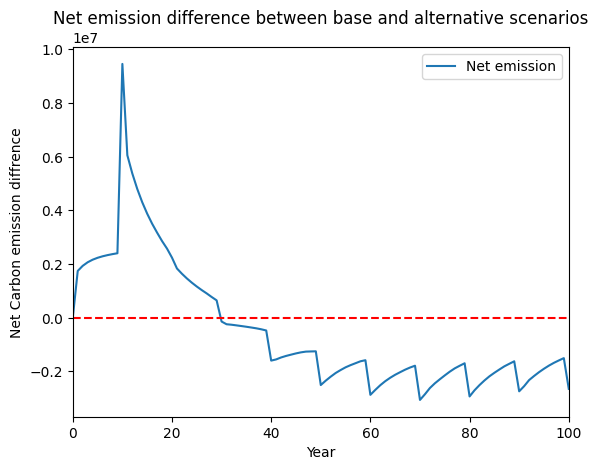

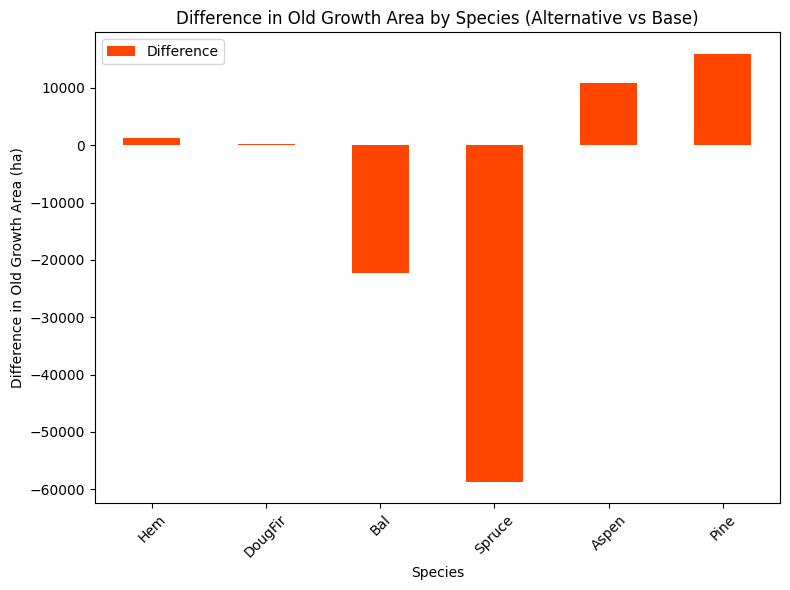

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_age_difference.pdf


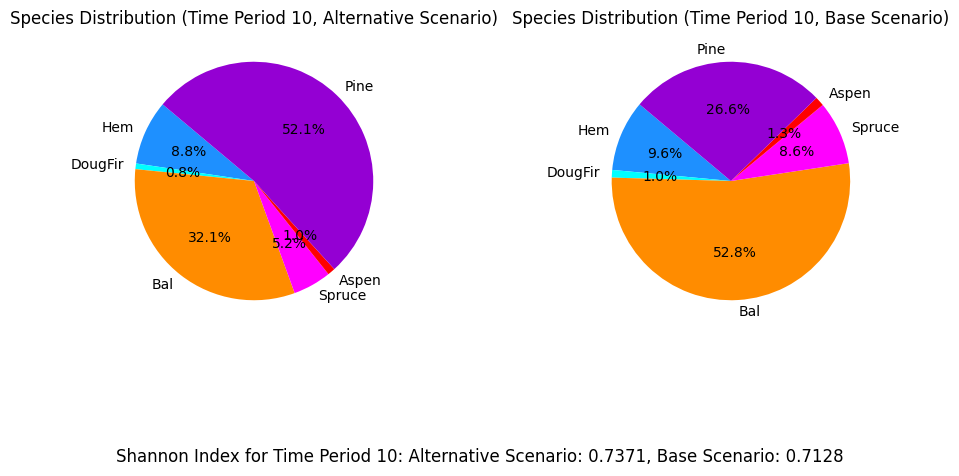

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_min_em_evenflow_cons...
running even flow constraints scenario
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17063 rows, 83258 columns and 514878 nonzeros
Model fingerprint: 0xe8a8cf0c
Coefficient statistics:
  Matrix range     [5e-03, 6e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]
Presolve removed 8690 rows and 8884 columns
Presolve time: 0.24s
Presolved: 8373 rows, 74374 columns, 486421 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Orde

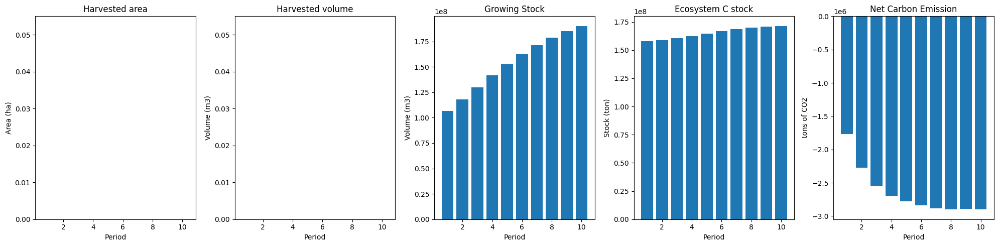

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_evenflow_cons_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  0
The economic indicator (the provincial government revenues) is:  0
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


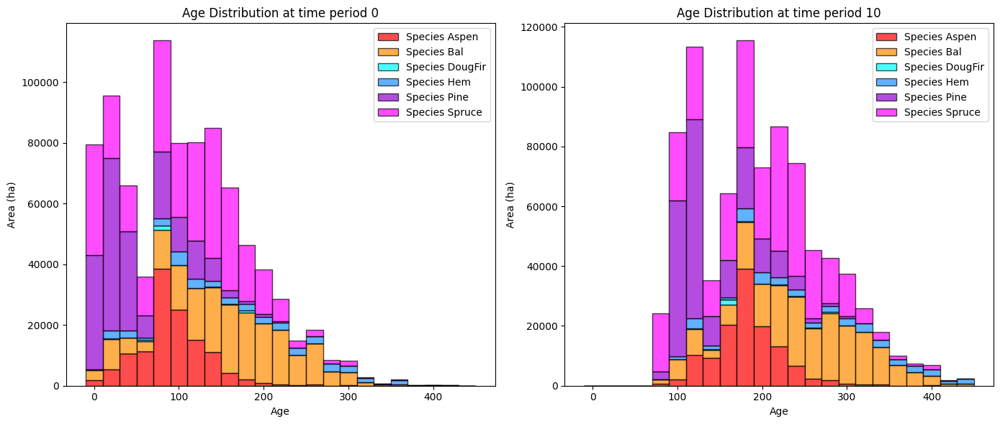

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_evenflow_cons_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229   32688.964561   13536.837333
DougFir    947.047810    2749.298212    1802.250402
Bal      59315.970469  157689.747715   98373.777247
Spruce   36410.744598  198358.607639  161947.863041
Aspen    29632.731169  118345.834248   88713.103079
Pine      7432.733686   70671.811755   63239.078069

Overall diversity has **increased** by 427612.91 hectares from time period 0 to time period 10.


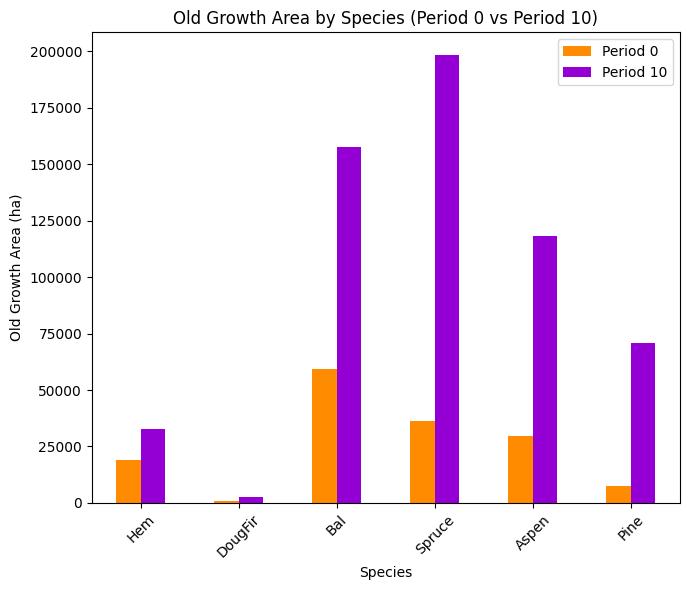

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_evenflow_cons_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7457

Diversity has **decreased** by 1.35% from time 0 to time 10.


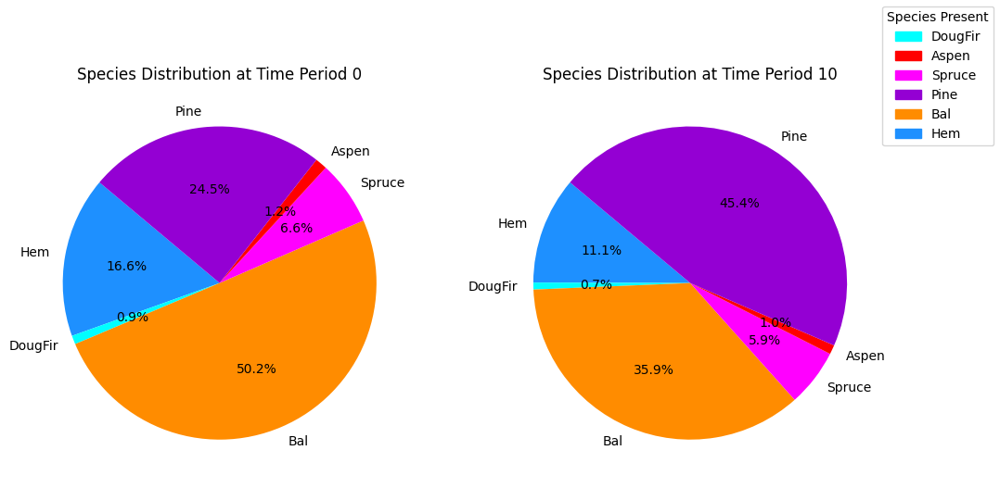

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_evenflow_cons_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x67e9da31
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.27s
Presolved: 8375 rows, 74375 columns, 536310 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Orde

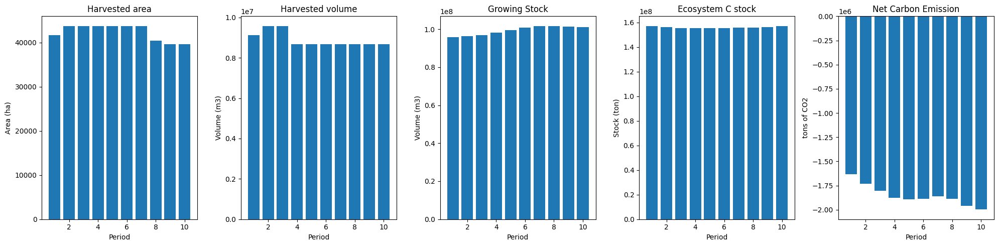

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


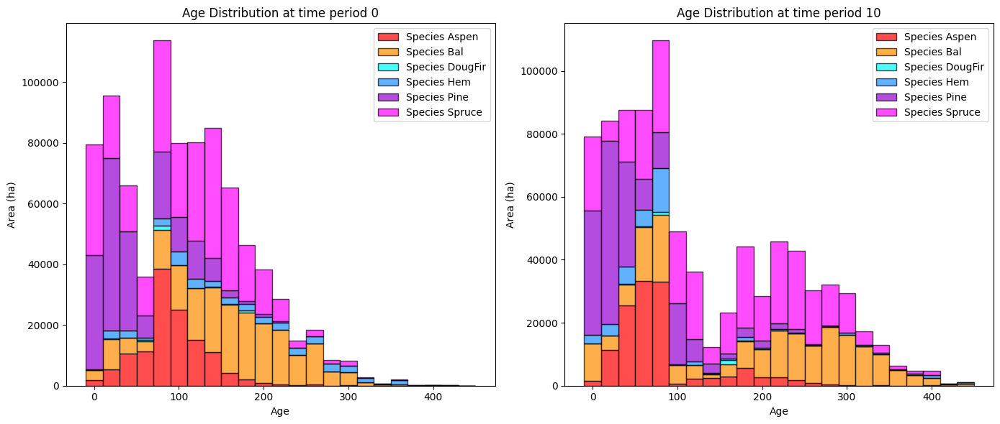

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    6279.556292 -12872.570937
DougFir    947.047810    1312.466058    365.418248
Bal      59315.970469  108811.384782  49495.414314
Spruce   36410.744598  134653.193927  98242.449329
Aspen    29632.731169   20687.141690  -8945.589480
Pine      7432.733686    9982.874965   2550.141279

Overall diversity has **increased** by 128835.26 hectares from time period 0 to time period 10.


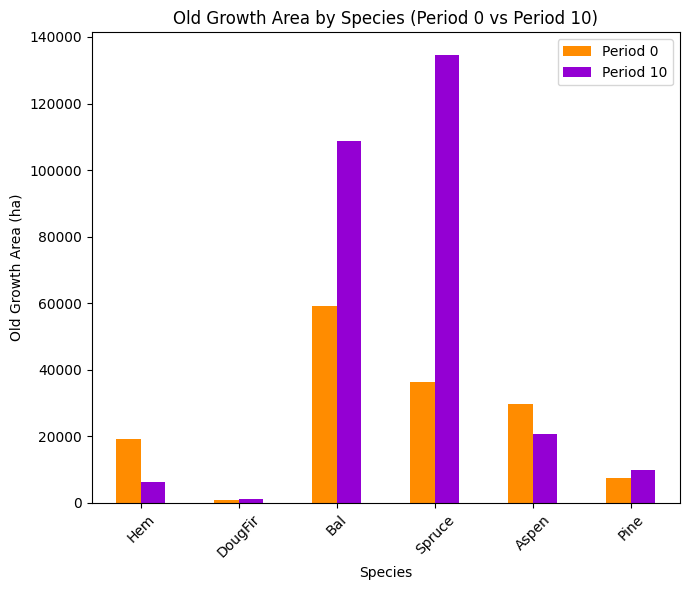

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7128

Diversity has **decreased** by 4.64% from time 0 to time 10.


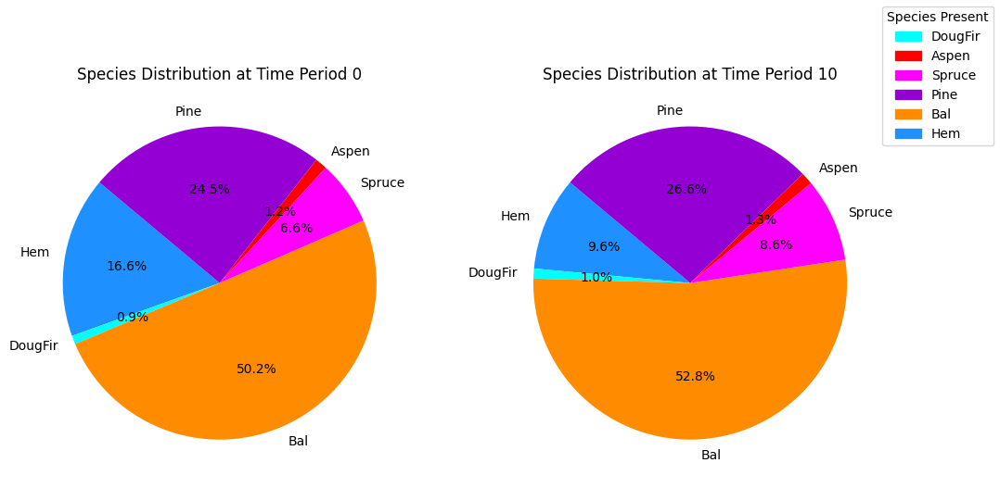

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_species_pie.pdf


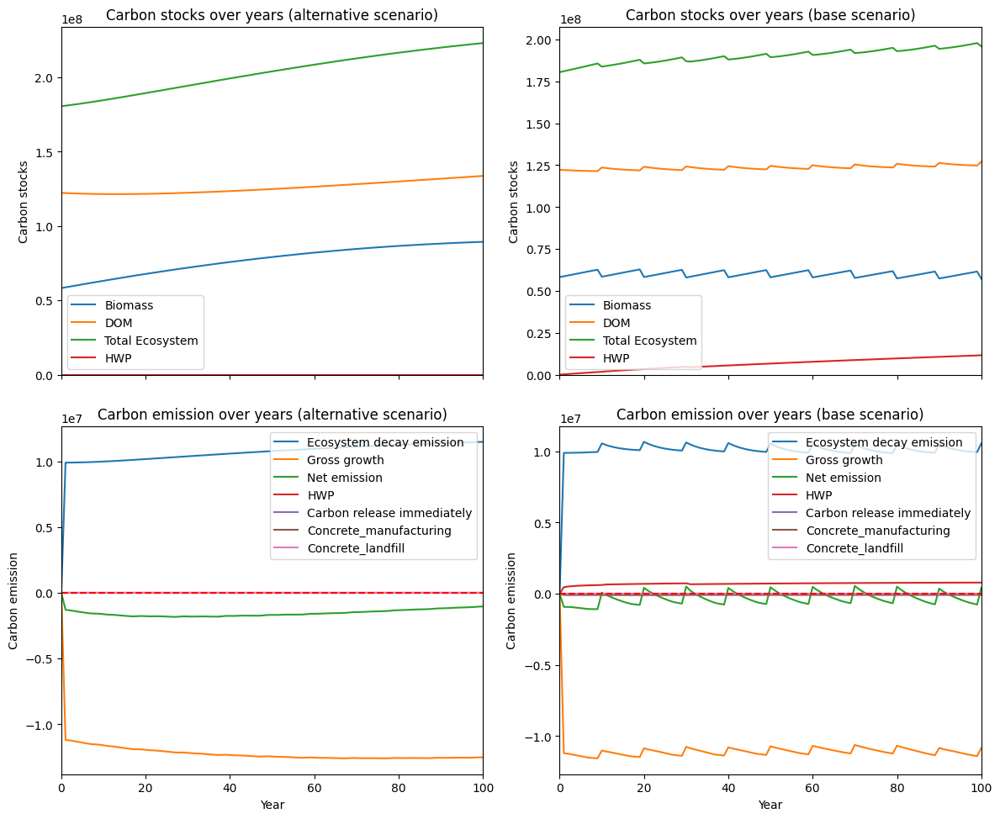

---------------------------------------------------------------------------------------
Net emission difference -26363233.351456694
Net emission base scenario -39533774.029656515
Net emission alternative scenario -13170540.67819982
dollar_per_ton is:  0.37931614330787133
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0  26409.408269  26409.408269
DougFir  0.0   1436.832154   1436.832154
Bal      0.0  48878.362933  48878.362933
Spruce   0.0  63705.413711  63705.413711
Aspen    0.0  97658.692558  97658.692558
Pine     0.0  60688.936790  60688.936790

Overall, the old growth area has **increased** by 298777.65 hectares in the alternative scenario compared to the base scenario.


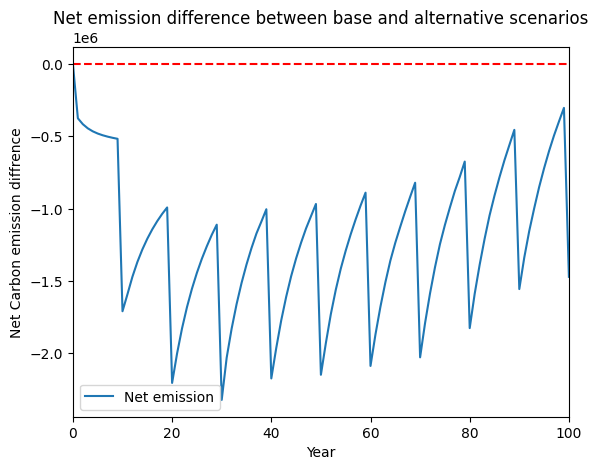

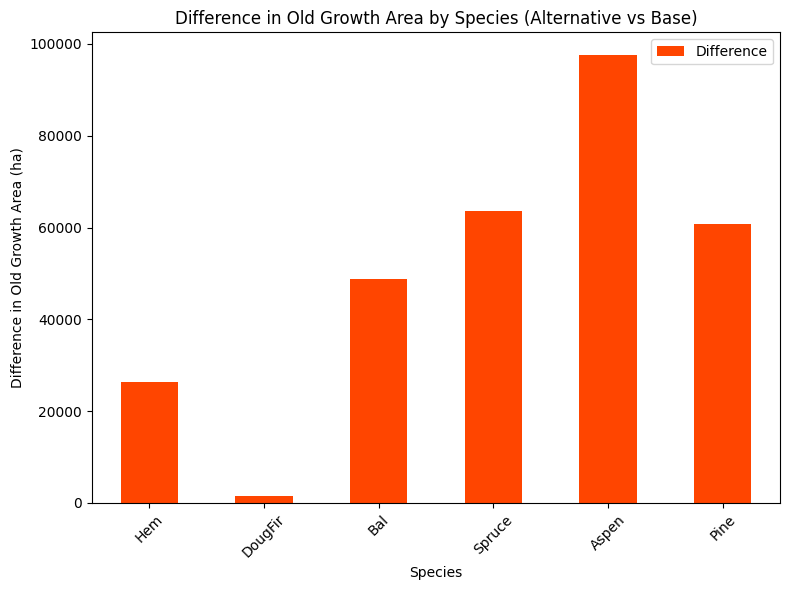

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_age_difference.pdf


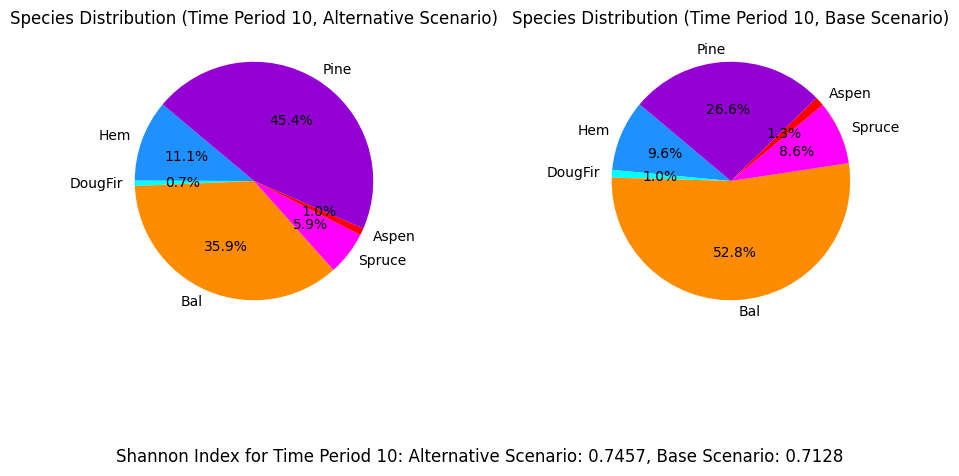

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_min_em_bau_eqtslvr...
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x67e9da31
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.26s
Presolved: 8375 ro

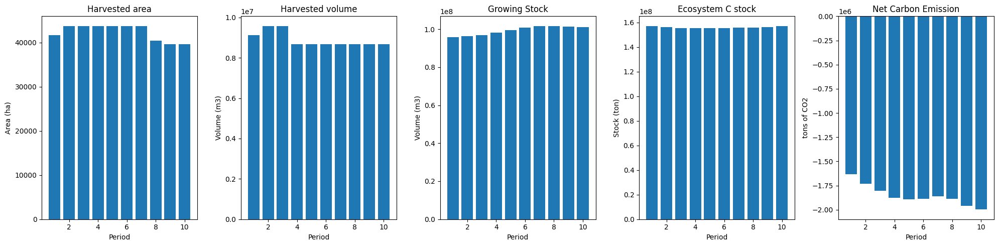

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


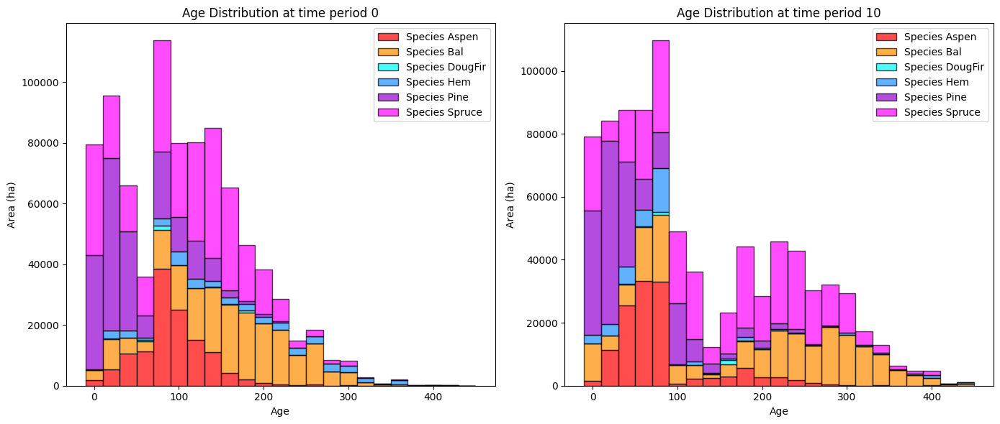

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    6279.556292 -12872.570937
DougFir    947.047810    1312.466058    365.418248
Bal      59315.970469  108811.384782  49495.414314
Spruce   36410.744598  134653.193927  98242.449329
Aspen    29632.731169   20687.141690  -8945.589480
Pine      7432.733686    9982.874965   2550.141279

Overall diversity has **increased** by 128835.26 hectares from time period 0 to time period 10.


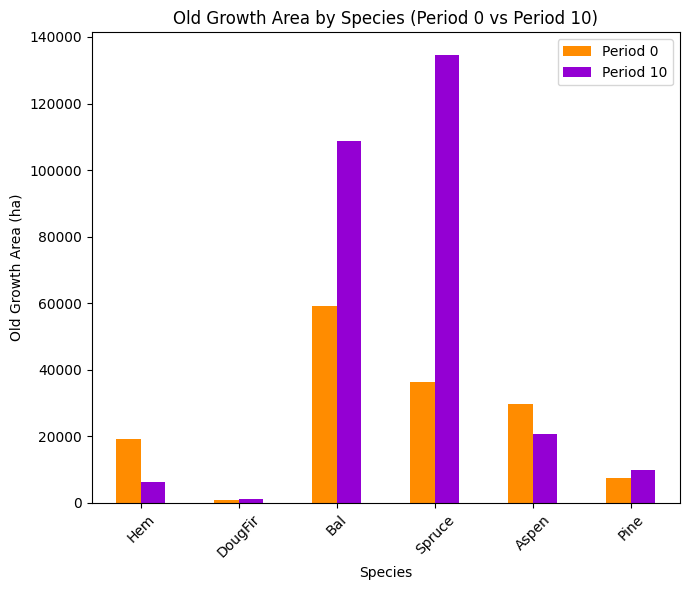

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7128

Diversity has **decreased** by 4.64% from time 0 to time 10.


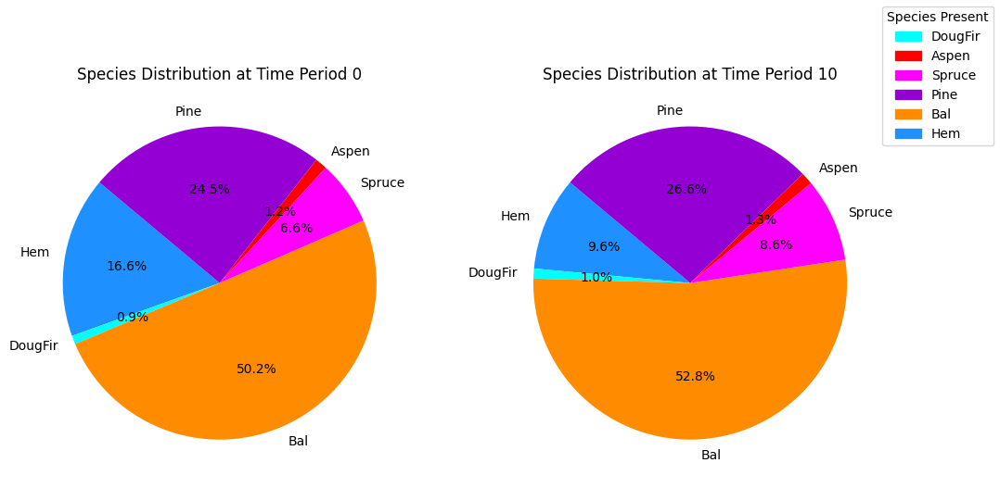

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x67e9da31
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.26s
Presolved: 8375 rows, 74375 columns, 536310 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Orderi

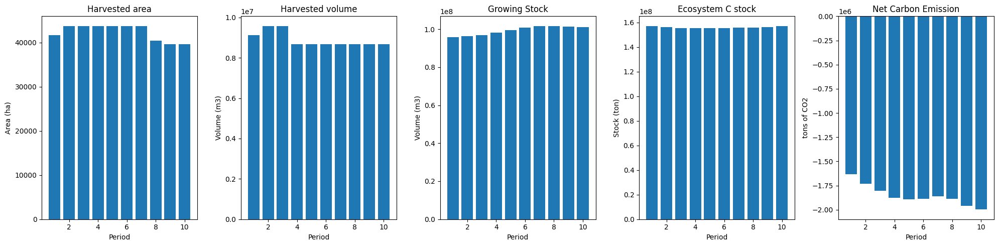

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


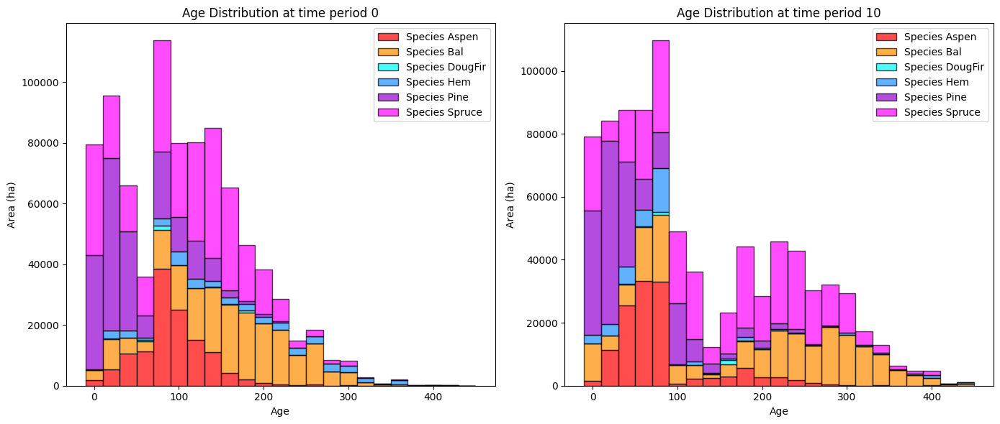

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    6279.556292 -12872.570937
DougFir    947.047810    1312.466058    365.418248
Bal      59315.970469  108811.384782  49495.414314
Spruce   36410.744598  134653.193927  98242.449329
Aspen    29632.731169   20687.141690  -8945.589480
Pine      7432.733686    9982.874965   2550.141279

Overall diversity has **increased** by 128835.26 hectares from time period 0 to time period 10.


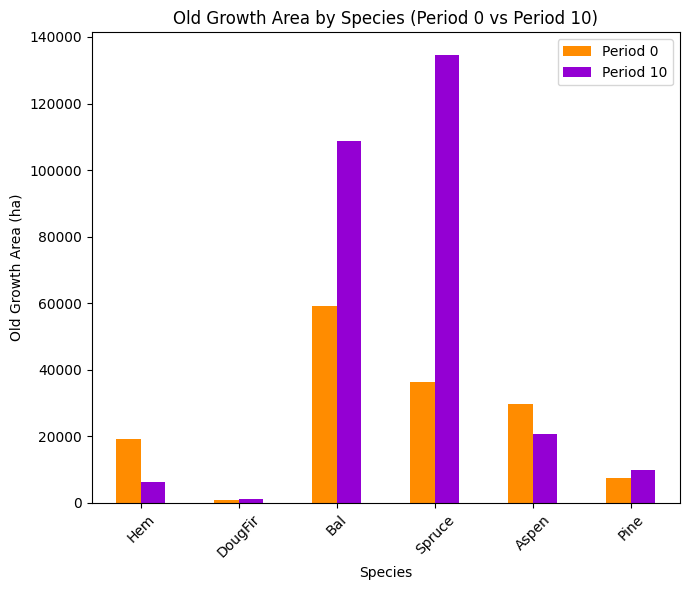

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7128

Diversity has **decreased** by 4.64% from time 0 to time 10.


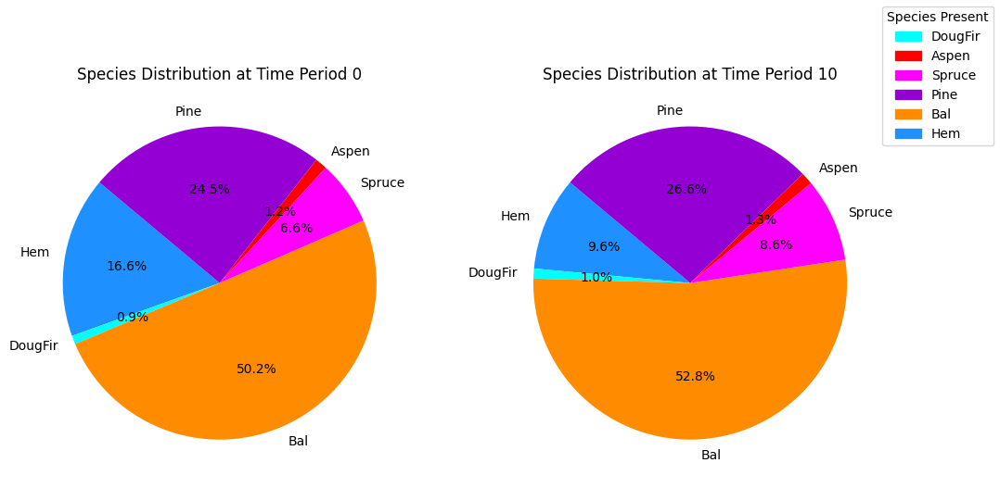

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_species_pie.pdf


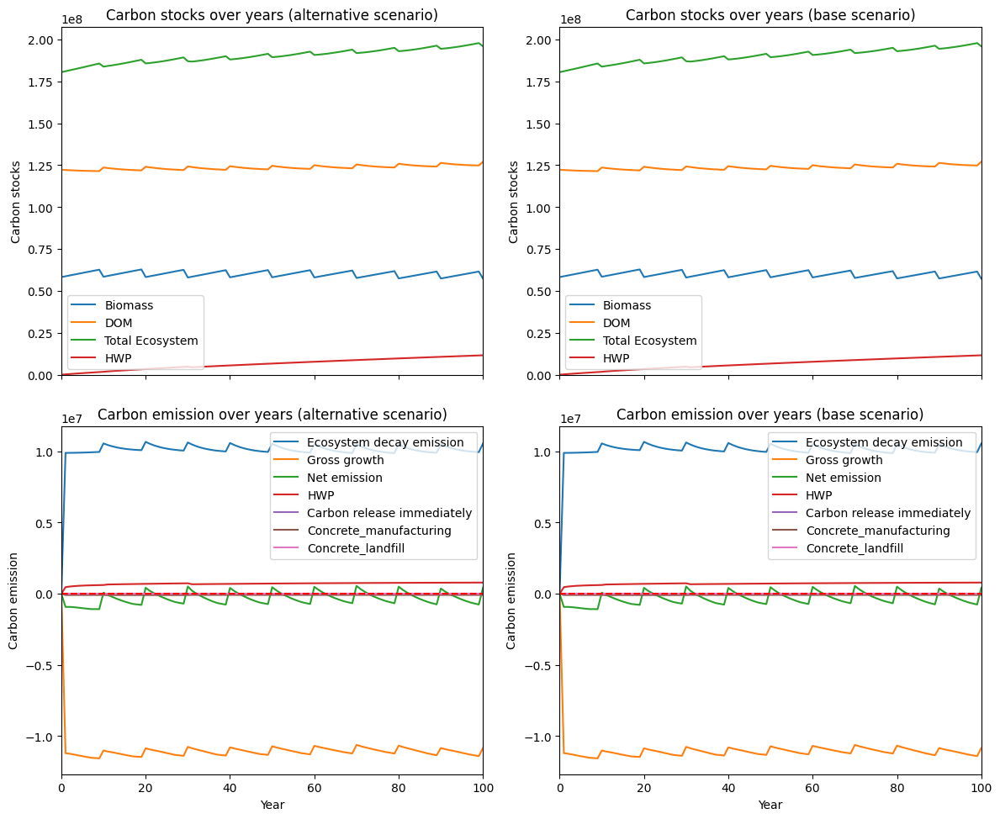

---------------------------------------------------------------------------------------
Net emission difference 0.0
Net emission base scenario -13170540.67819982
Net emission alternative scenario -13170540.67819982
dollar_per_ton is:  inf
Comparison of Old Growth Areas (Alternative - Base)
           0   10  Difference
Hem      0.0  0.0         0.0
DougFir  0.0  0.0         0.0
Bal      0.0  0.0         0.0
Spruce   0.0  0.0         0.0
Aspen    0.0  0.0         0.0
Pine     0.0  0.0         0.0

Overall, the old growth area has **increased** by 0.00 hectares in the alternative scenario compared to the base scenario.


/media/data/project/eghasemi/nbds_mining/util_opt.py:1211: RuntimeWarning: divide by zero encountered in scalar divide
  dollar_per_ton = abs(budget_input / dif_scenario.iloc[:25]['Net emission'].sum())


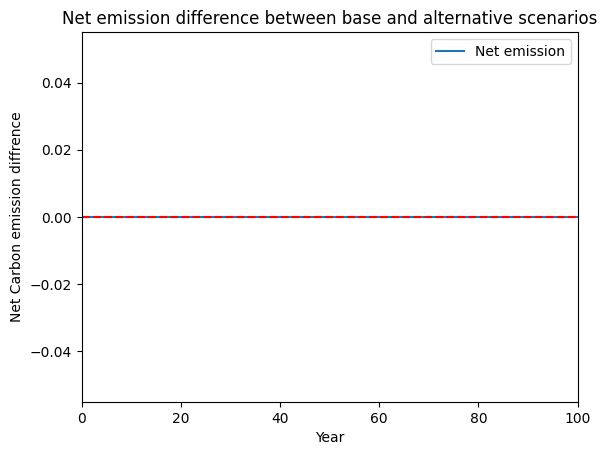

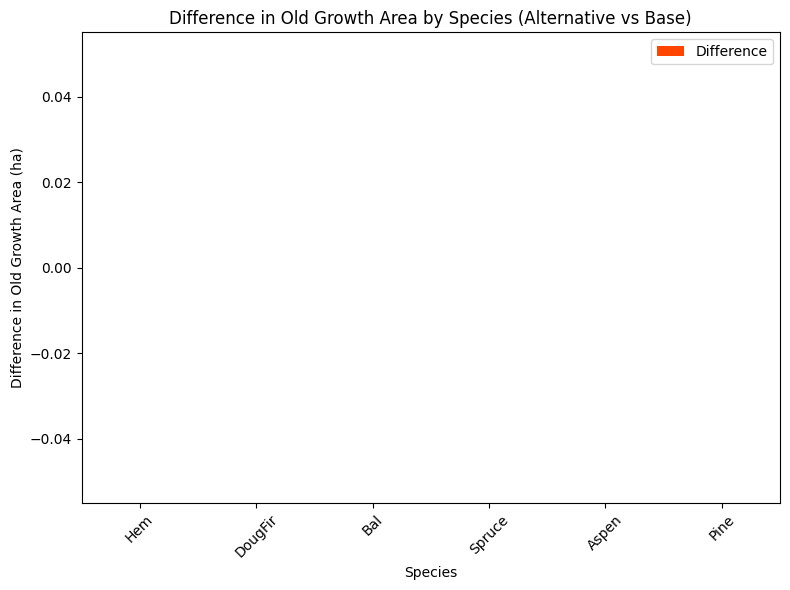

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_age_difference.pdf


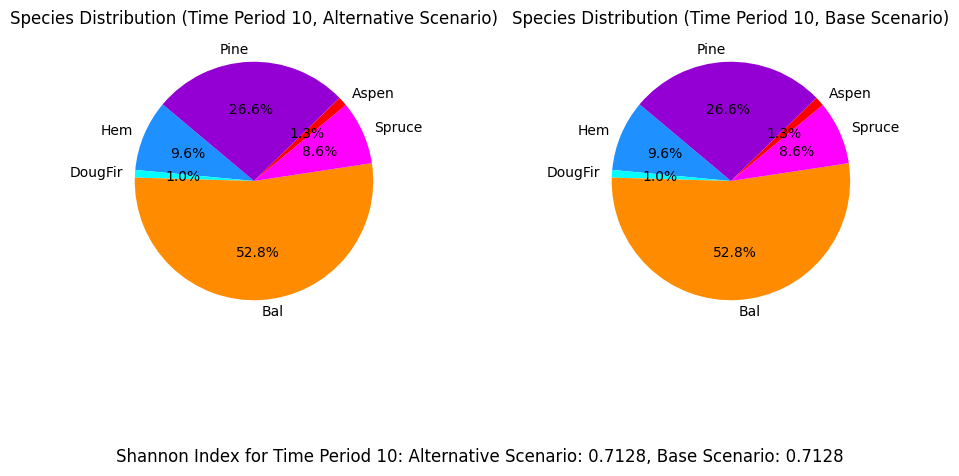

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_min_em_eqtslvr_AAC_90%...
running the scenario for the Equity Silver mining site (90%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x864a7c3f
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.23s
Presolved: 8375 r

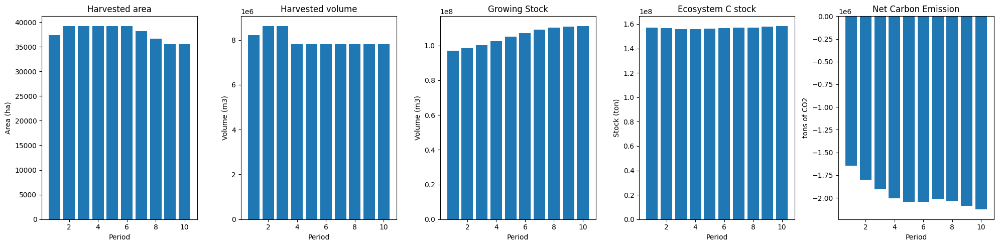

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_90%_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  84678
The economic indicator (the provincial government revenues) is:  2887716
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


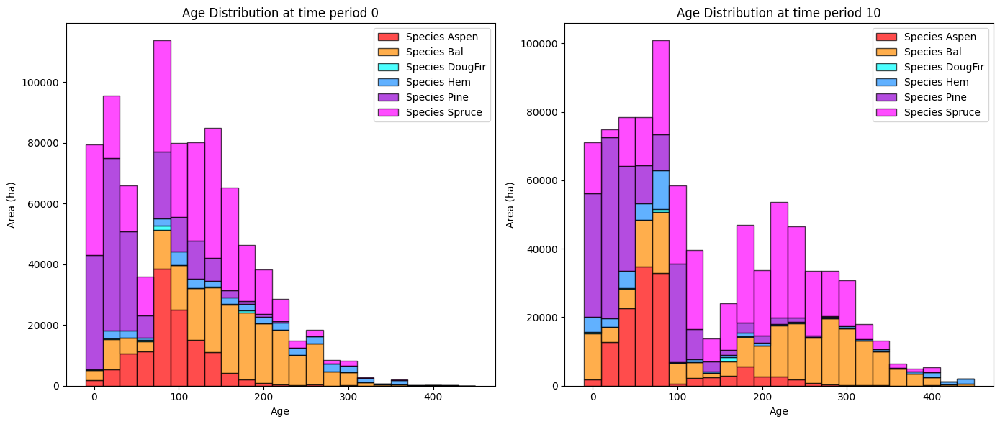

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_90%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229    8678.207553  -10473.919676
DougFir    947.047810    1460.857220     513.809410
Bal      59315.970469  114478.014003   55162.043534
Spruce   36410.744598  154445.069905  118034.325307
Aspen    29632.731169   20685.827842   -8946.903327
Pine      7432.733686   10302.112143    2869.378457

Overall diversity has **increased** by 157158.73 hectares from time period 0 to time period 10.


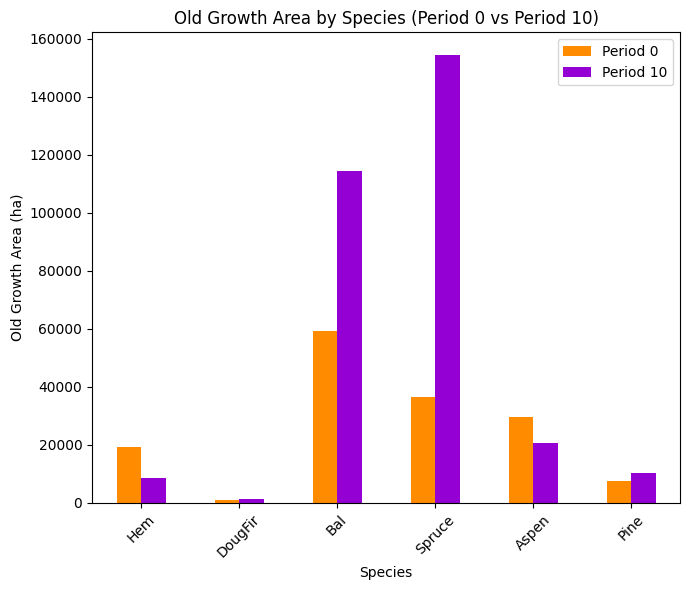

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_90%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7174

Diversity has **decreased** by 4.18% from time 0 to time 10.


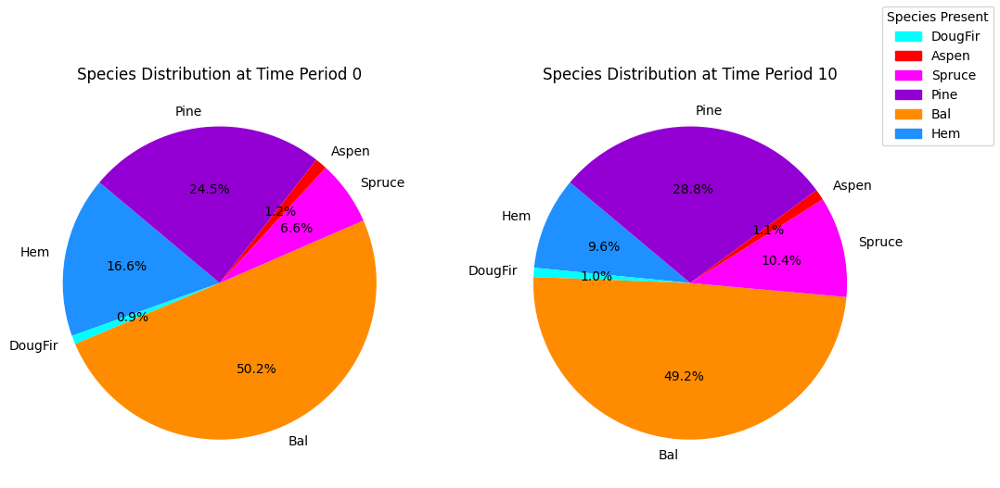

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_90%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x67e9da31
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.24s
Presolved: 8375 rows, 74375 columns, 536310 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

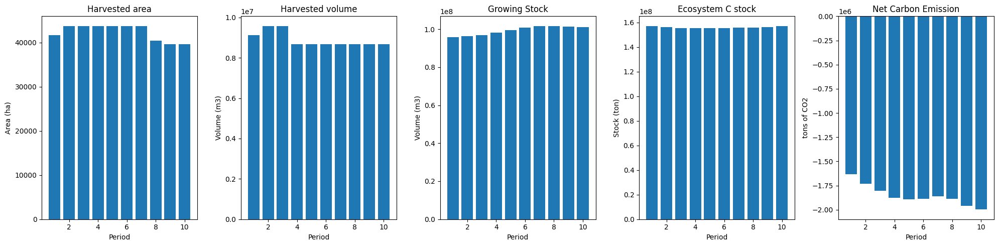

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


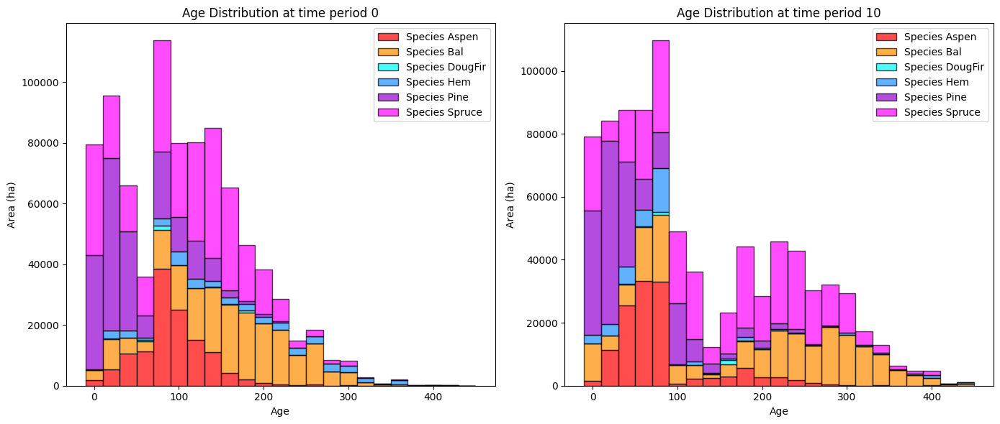

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    6279.556292 -12872.570937
DougFir    947.047810    1312.466058    365.418248
Bal      59315.970469  108811.384782  49495.414314
Spruce   36410.744598  134653.193927  98242.449329
Aspen    29632.731169   20687.141690  -8945.589480
Pine      7432.733686    9982.874965   2550.141279

Overall diversity has **increased** by 128835.26 hectares from time period 0 to time period 10.


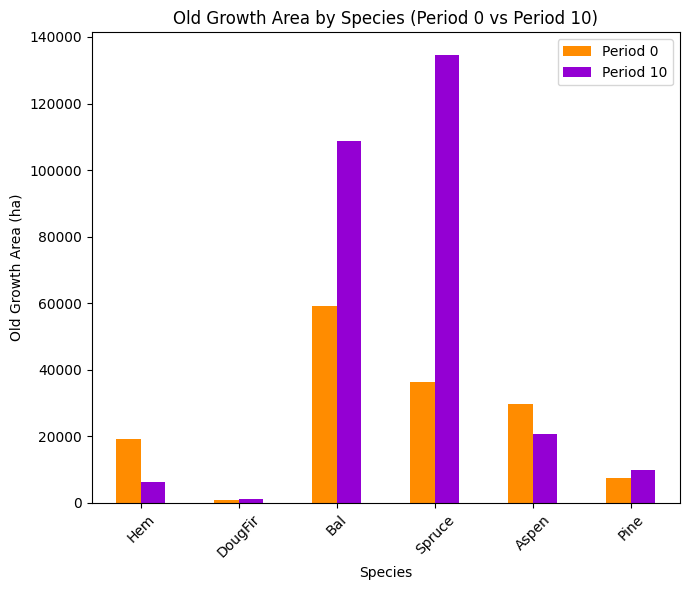

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7128

Diversity has **decreased** by 4.64% from time 0 to time 10.


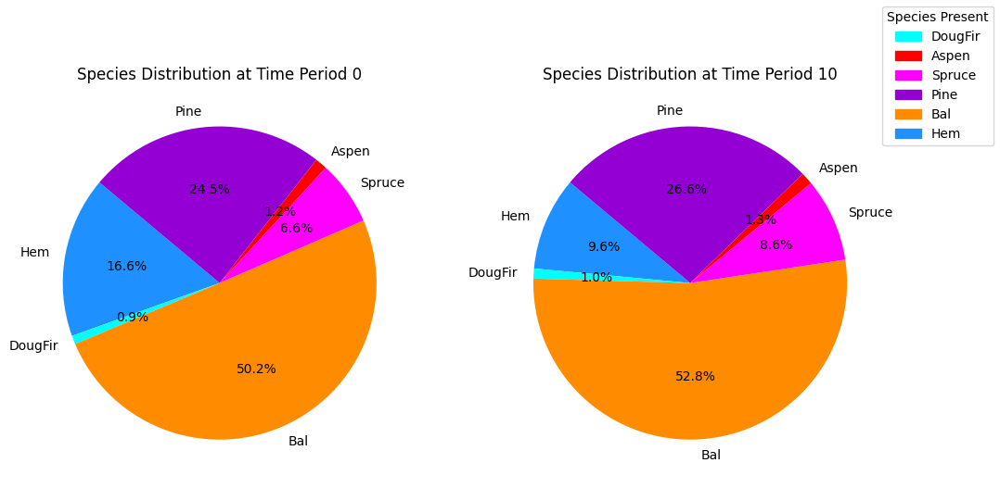

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_species_pie.pdf


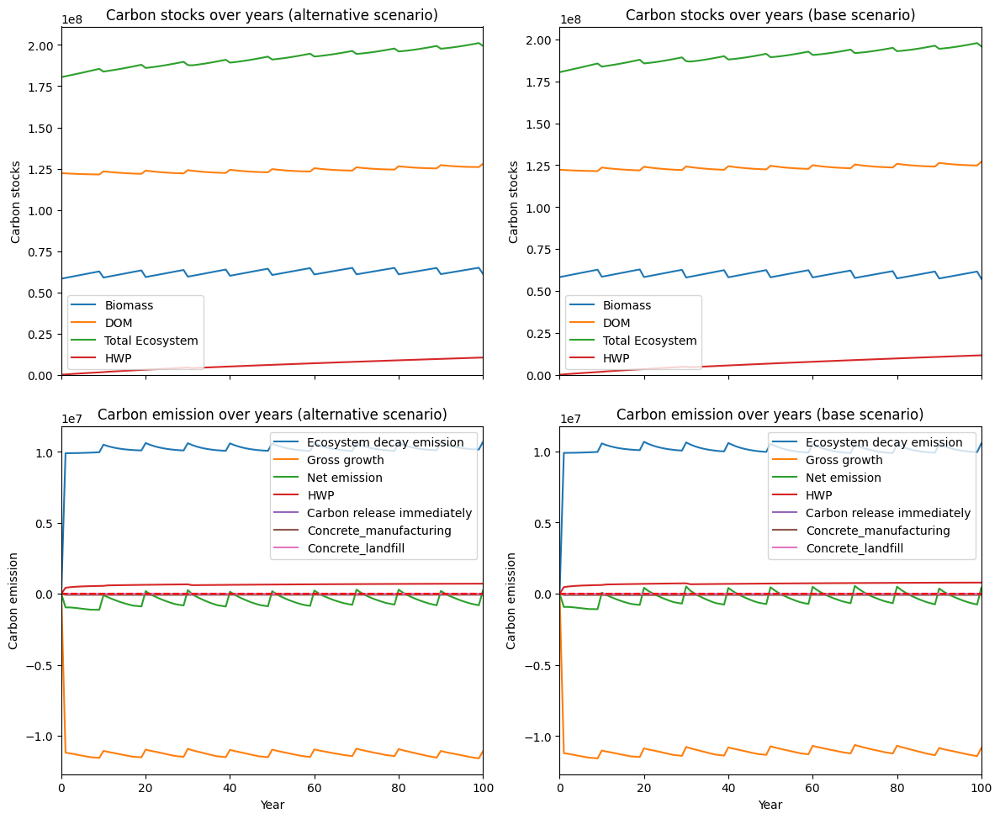

---------------------------------------------------------------------------------------
Net emission difference -2839672.2892413544
Net emission base scenario -16010212.967441171
Net emission alternative scenario -13170540.67819982
dollar_per_ton is:  3.5215331141860724
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0   2398.651261   2398.651261
DougFir  0.0    148.391162    148.391162
Bal      0.0   5666.629220   5666.629220
Spruce   0.0  19791.875977  19791.875977
Aspen    0.0     -1.313848     -1.313848
Pine     0.0    319.237178    319.237178

Overall, the old growth area has **increased** by 28323.47 hectares in the alternative scenario compared to the base scenario.


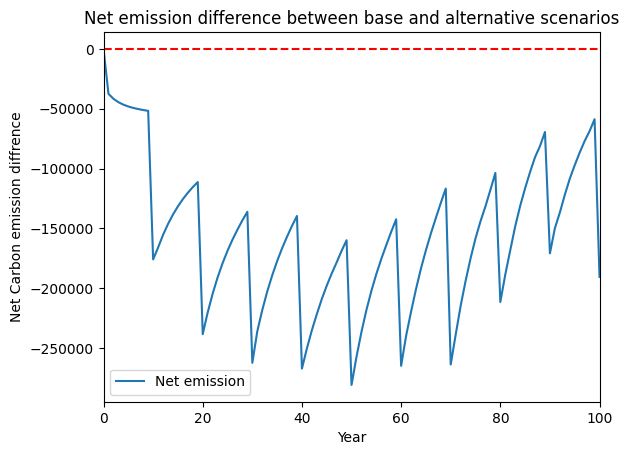

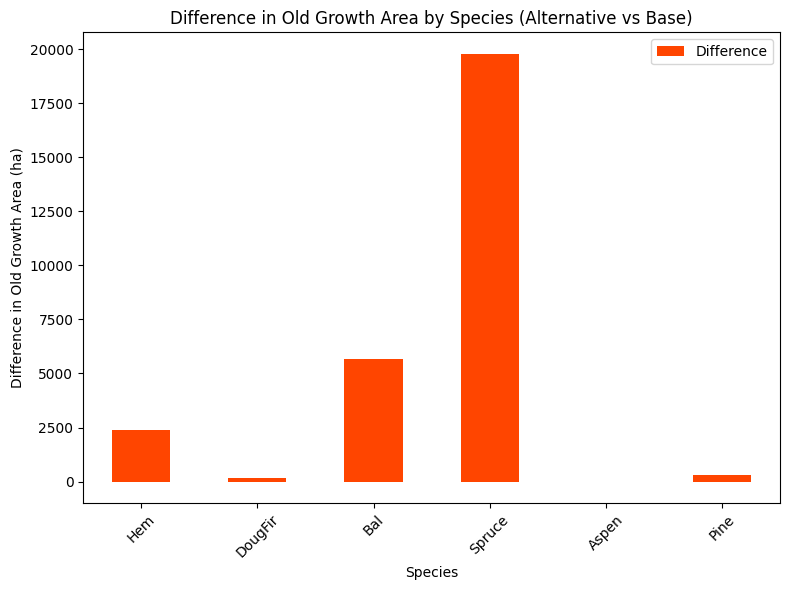

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_age_difference.pdf


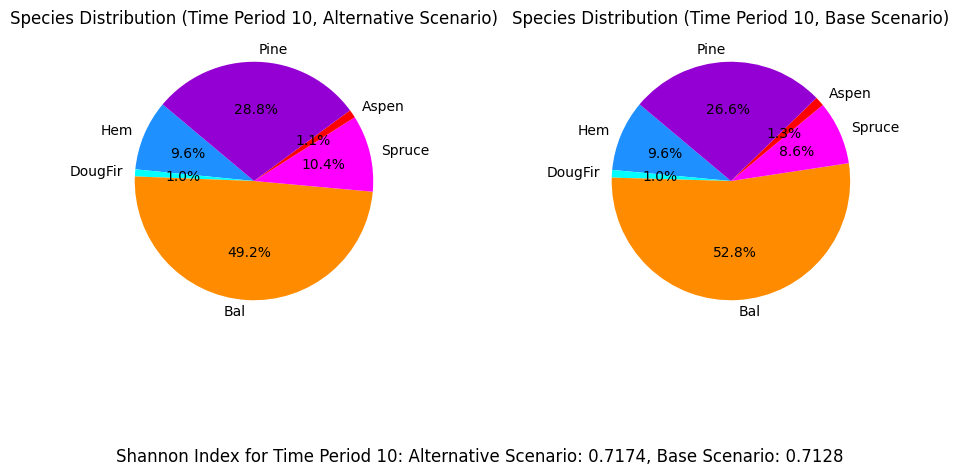

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_min_em_eqtslvr_AAC_80%...
running the scenario for the Equity Silver mining site (80%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xb6745659
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.28s
Presolved: 8375 r

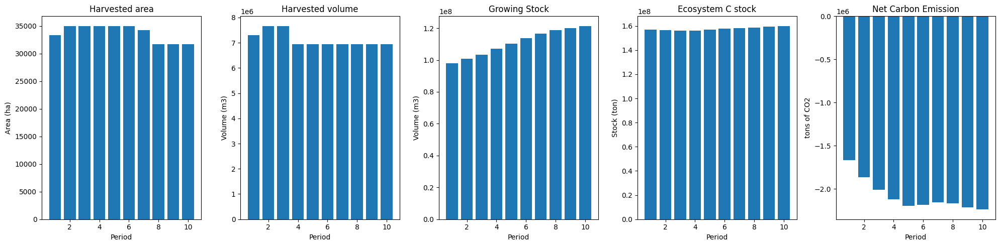

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_80%_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  75269
The economic indicator (the provincial government revenues) is:  2566858
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


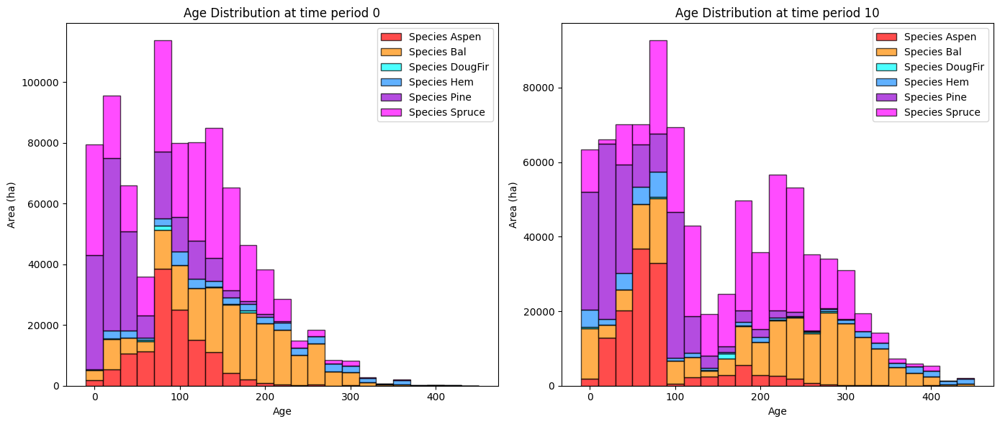

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_80%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229   13886.537530   -5265.589699
DougFir    947.047810    1903.532071     956.484261
Bal      59315.970469  115025.902455   55709.931987
Spruce   36410.744598  169371.421513  132960.676915
Aspen    29632.731169   20686.002475   -8946.728694
Pine      7432.733686   10419.200258    2986.466571

Overall diversity has **increased** by 178401.24 hectares from time period 0 to time period 10.


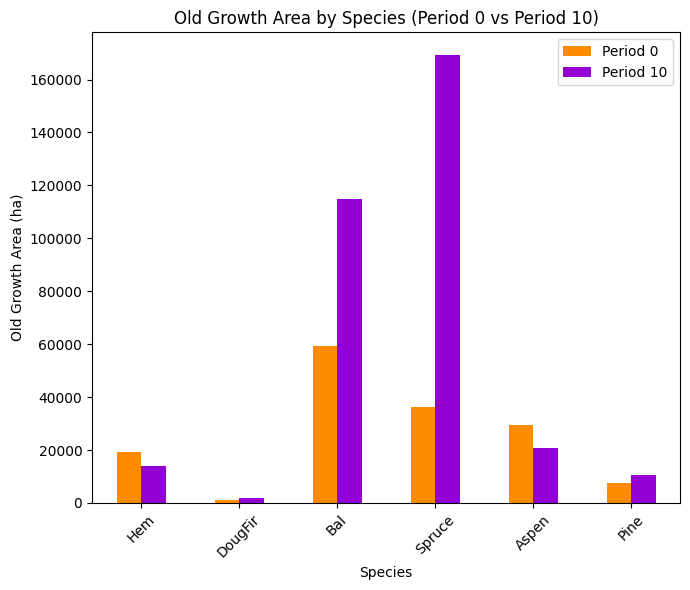

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_80%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7181

Diversity has **decreased** by 4.10% from time 0 to time 10.


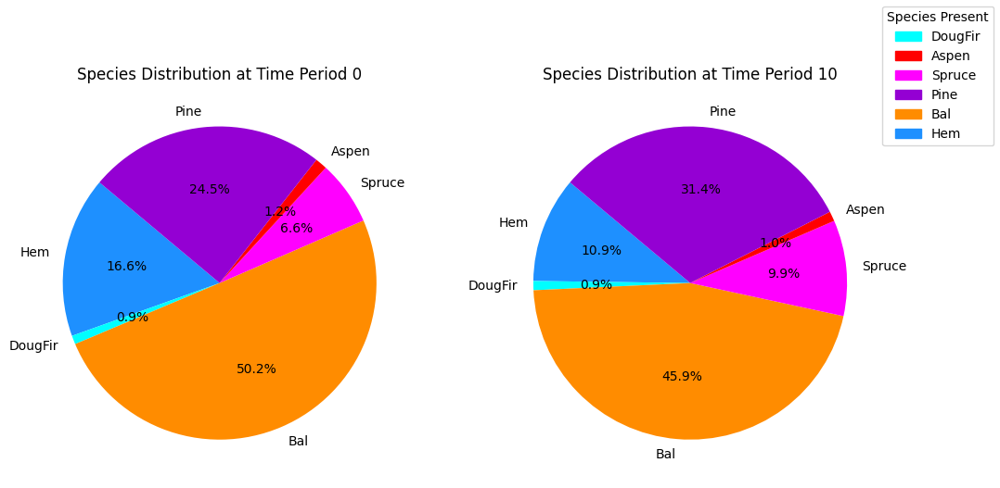

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_80%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x67e9da31
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.35s
Presolved: 8375 rows, 74375 columns, 536310 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

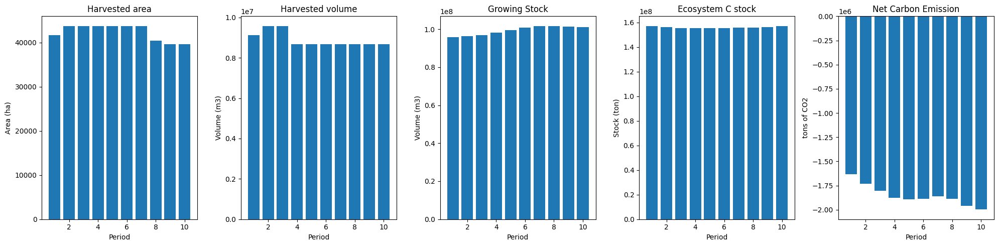

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


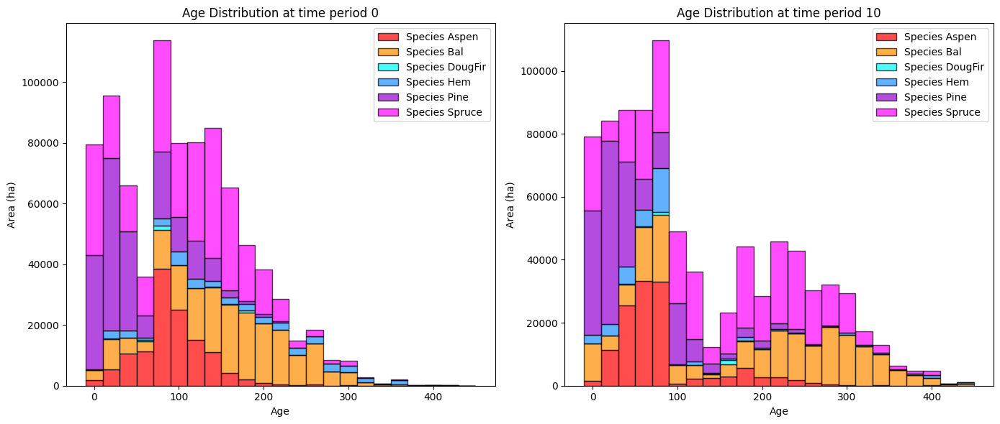

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    6279.556292 -12872.570937
DougFir    947.047810    1312.466058    365.418248
Bal      59315.970469  108811.384782  49495.414314
Spruce   36410.744598  134653.193927  98242.449329
Aspen    29632.731169   20687.141690  -8945.589480
Pine      7432.733686    9982.874965   2550.141279

Overall diversity has **increased** by 128835.26 hectares from time period 0 to time period 10.


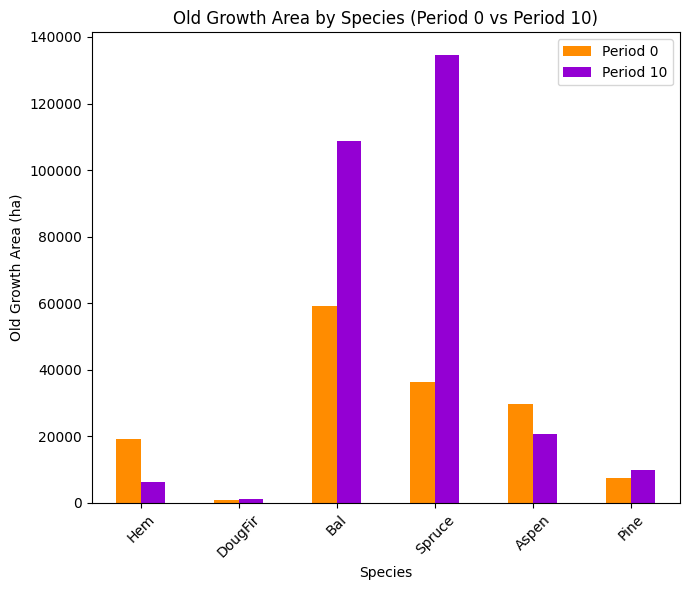

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7128

Diversity has **decreased** by 4.64% from time 0 to time 10.


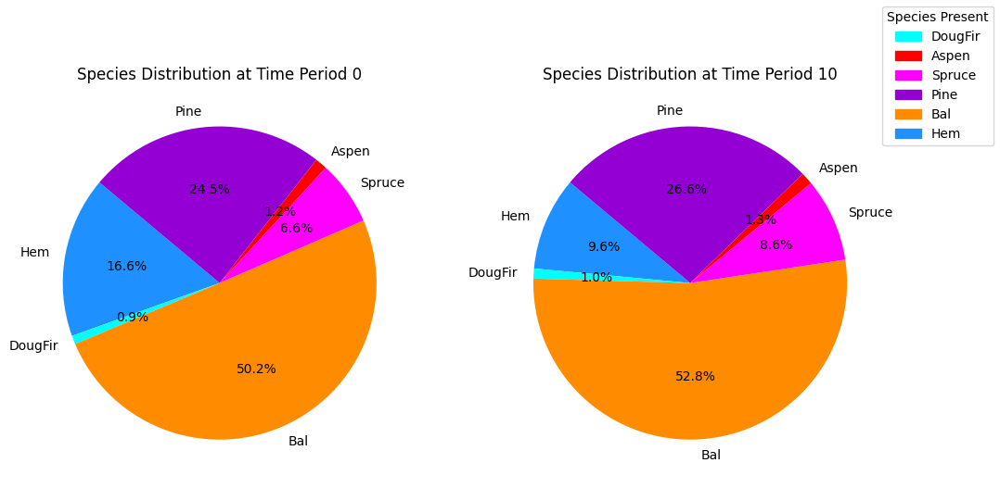

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_species_pie.pdf


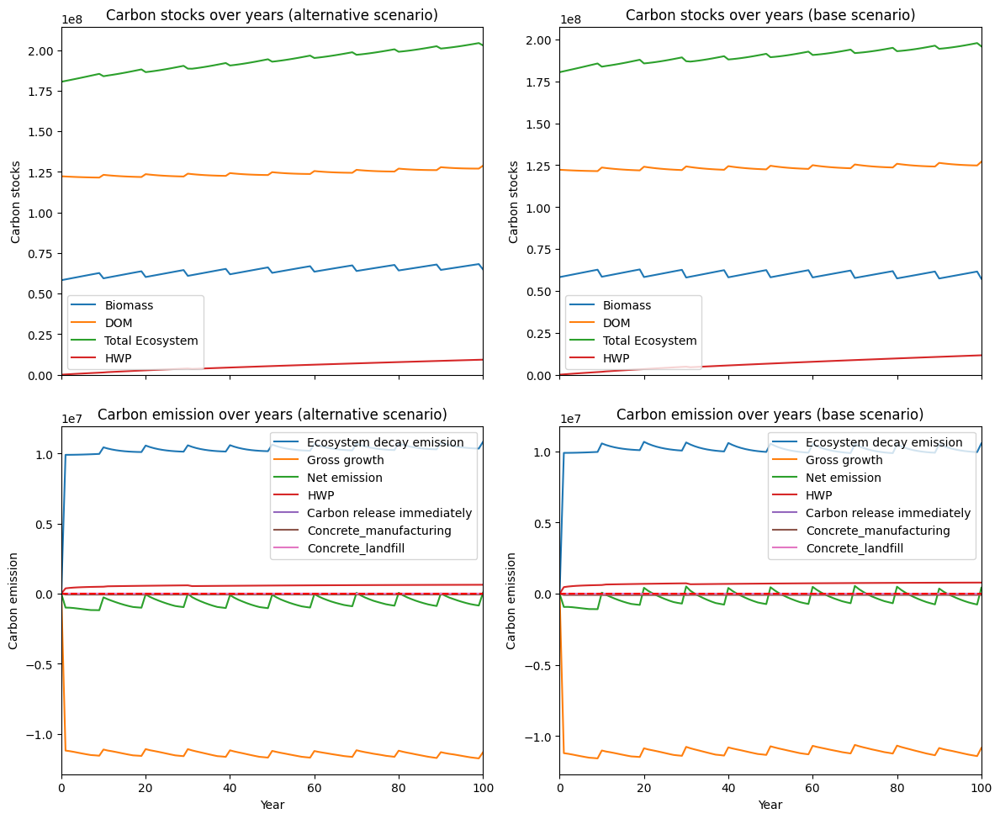

---------------------------------------------------------------------------------------
Net emission difference -5650077.955152402
Net emission base scenario -18820618.63335222
Net emission alternative scenario -13170540.67819982
dollar_per_ton is:  1.7698870846340855
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0   7606.981238   7606.981238
DougFir  0.0    591.066013    591.066013
Bal      0.0   6214.517673   6214.517673
Spruce   0.0  34718.227585  34718.227585
Aspen    0.0     -1.139215     -1.139215
Pine     0.0    436.325292    436.325292

Overall, the old growth area has **increased** by 49565.98 hectares in the alternative scenario compared to the base scenario.


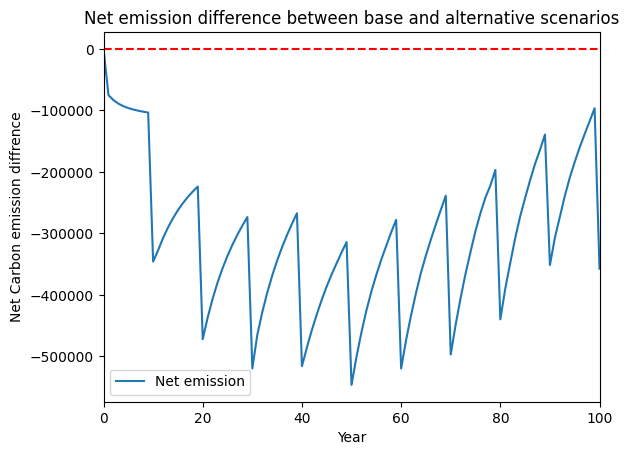

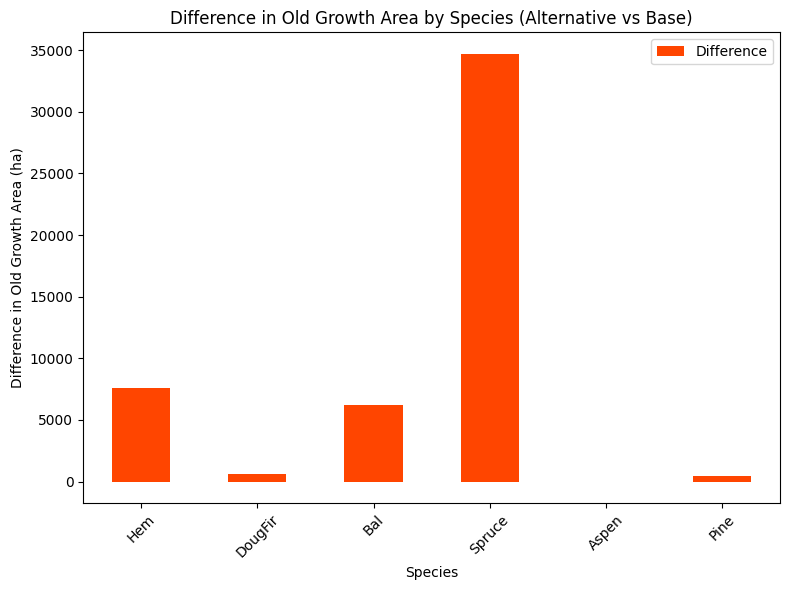

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_age_difference.pdf


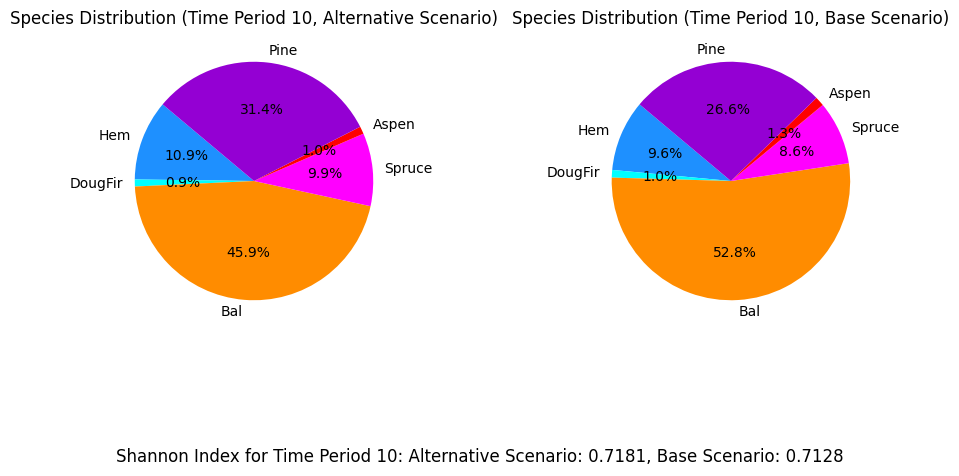

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_min_em_eqtslvr_AAC_70%...
running the scenario for the Equity Silver mining site (70%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x0d6f1dda
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.32s
Presolved: 8375 r

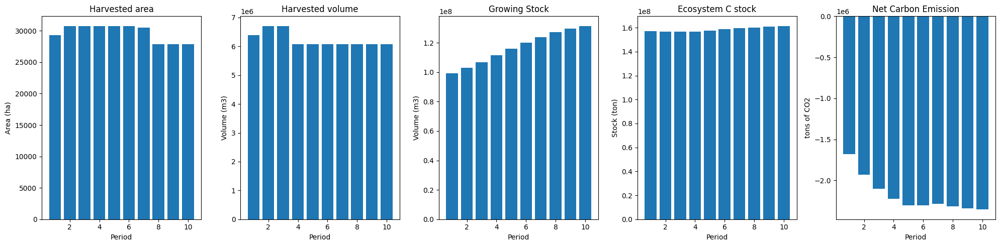

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_70%_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  65861
The economic indicator (the provincial government revenues) is:  2246001
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


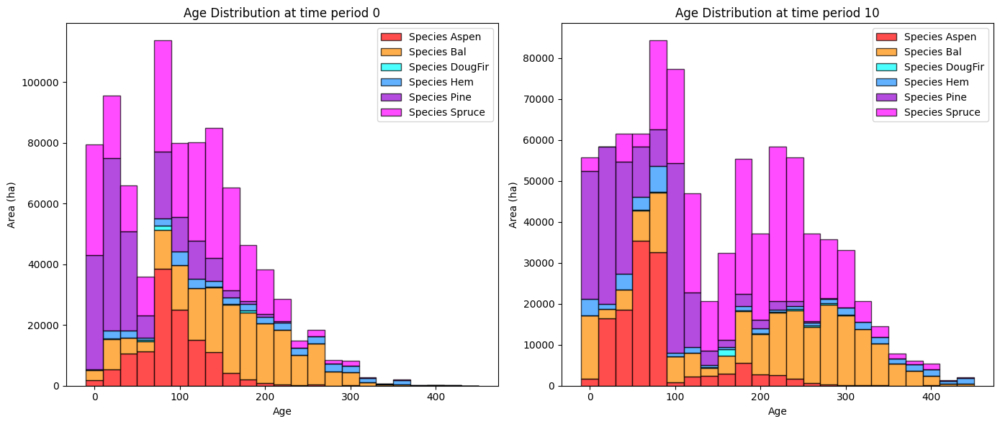

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_70%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229   16438.183795   -2713.943434
DougFir    947.047810    2587.448146    1640.400336
Bal      59315.970469  119435.597254   60119.626785
Spruce   36410.744598  183524.152429  147113.407831
Aspen    29632.731169   20693.454225   -8939.276944
Pine      7432.733686   11181.407772    3748.674085

Overall diversity has **increased** by 200968.89 hectares from time period 0 to time period 10.


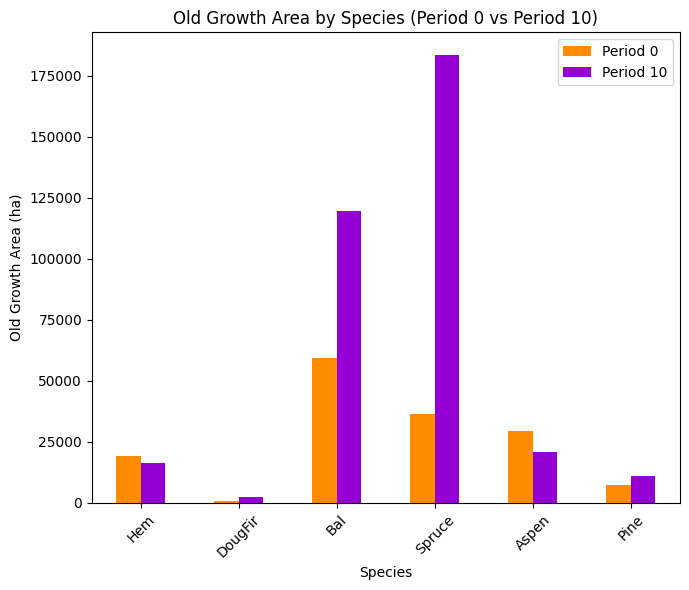

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_70%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7158

Diversity has **decreased** by 4.34% from time 0 to time 10.


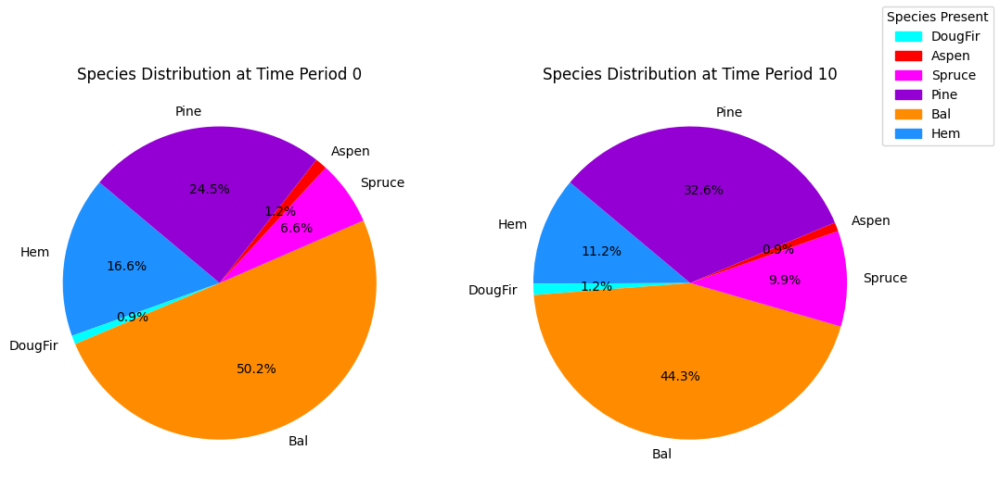

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_70%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x67e9da31
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.30s
Presolved: 8375 rows, 74375 columns, 536310 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

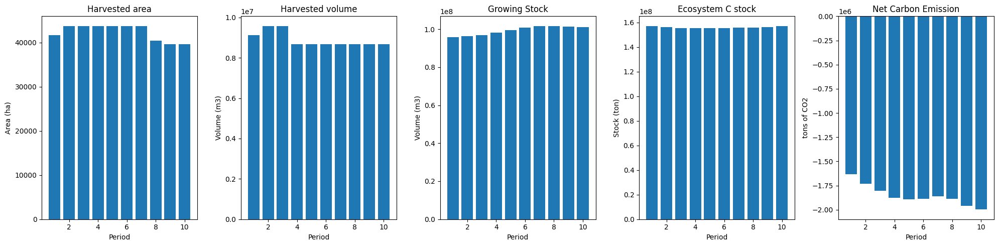

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


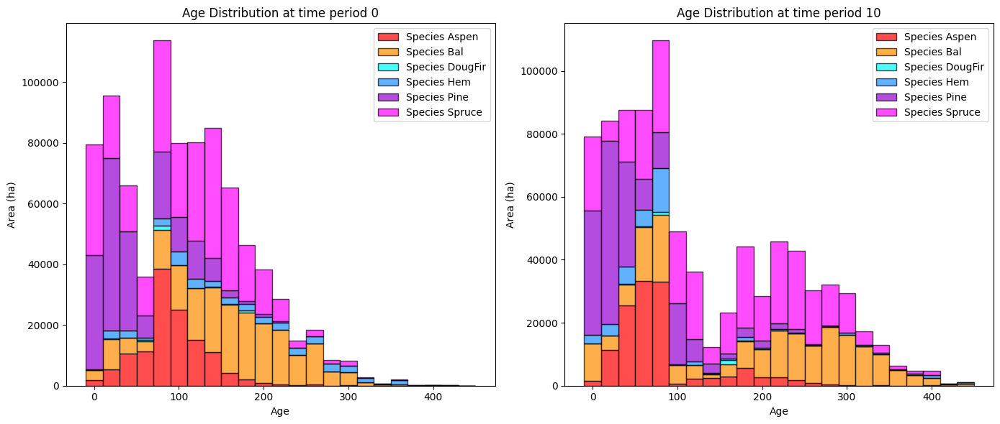

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    6279.556292 -12872.570937
DougFir    947.047810    1312.466058    365.418248
Bal      59315.970469  108811.384782  49495.414314
Spruce   36410.744598  134653.193927  98242.449329
Aspen    29632.731169   20687.141690  -8945.589480
Pine      7432.733686    9982.874965   2550.141279

Overall diversity has **increased** by 128835.26 hectares from time period 0 to time period 10.


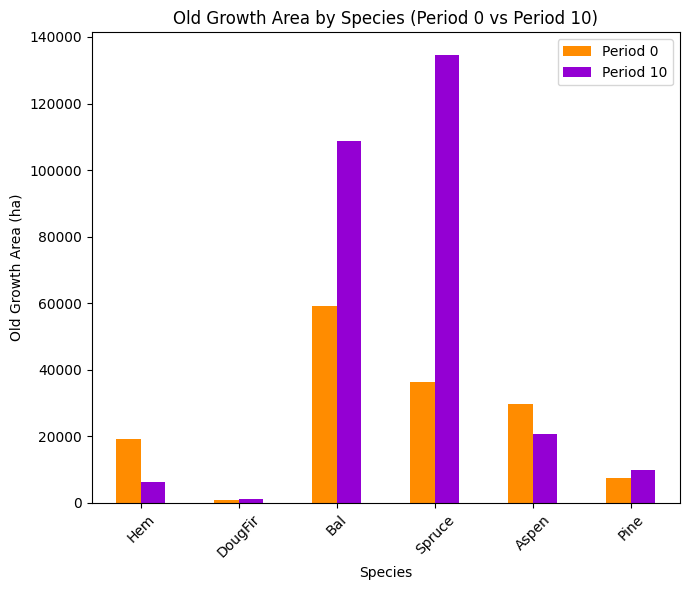

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7128

Diversity has **decreased** by 4.64% from time 0 to time 10.


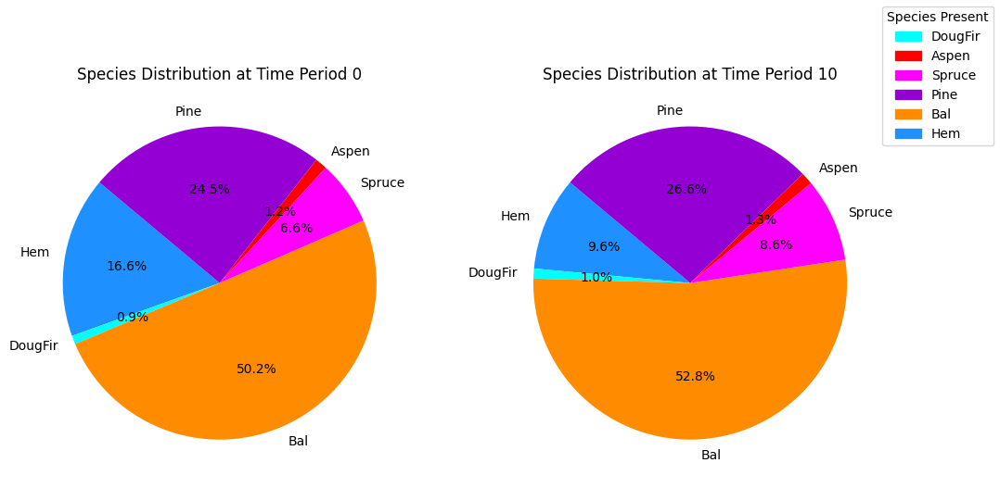

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_species_pie.pdf


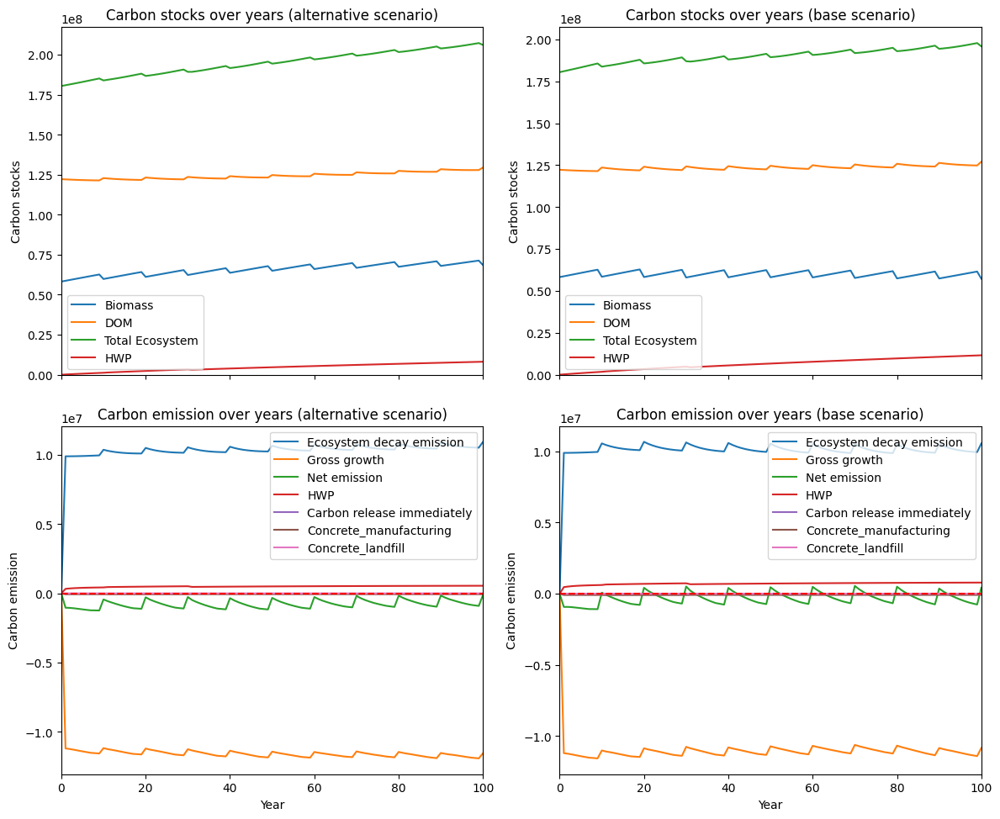

---------------------------------------------------------------------------------------
Net emission difference -8407605.305116758
Net emission base scenario -21578145.98331658
Net emission alternative scenario -13170540.67819982
dollar_per_ton is:  1.1893993161065888
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0  10158.627503  10158.627503
DougFir  0.0   1274.982088   1274.982088
Bal      0.0  10624.212472  10624.212472
Spruce   0.0  48870.958502  48870.958502
Aspen    0.0      6.312536      6.312536
Pine     0.0   1198.532806   1198.532806

Overall, the old growth area has **increased** by 72133.63 hectares in the alternative scenario compared to the base scenario.


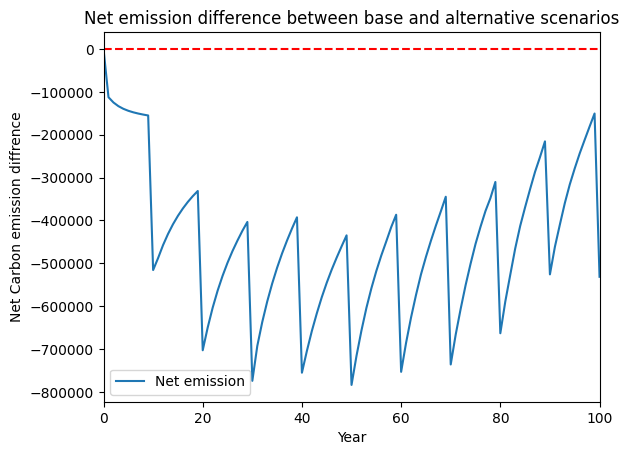

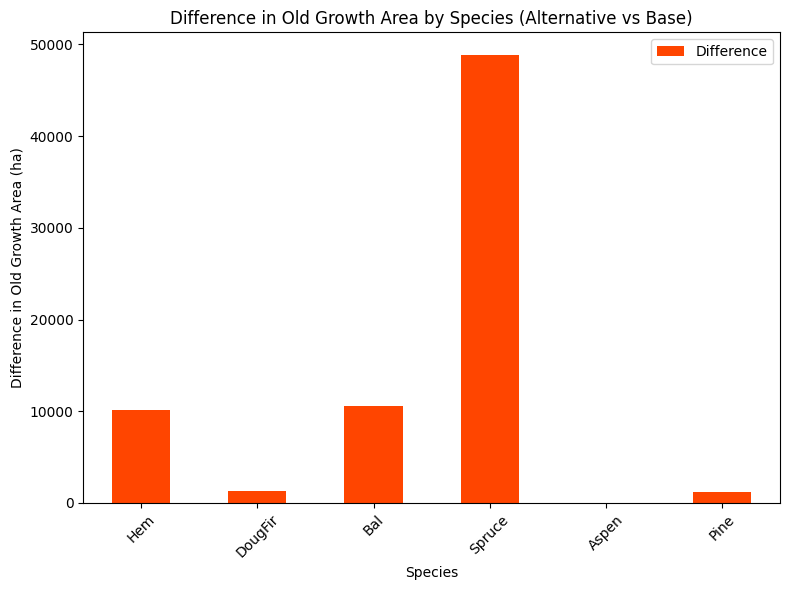

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_age_difference.pdf


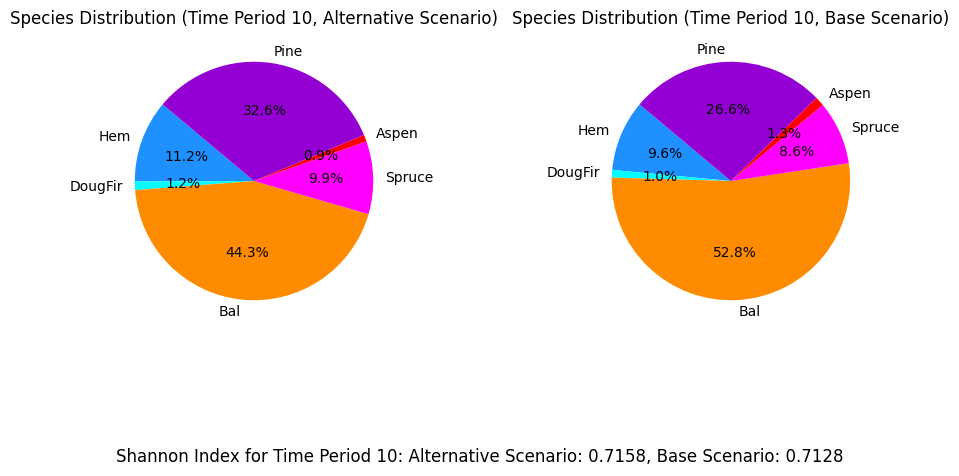

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_min_em_eqtslvr_AAC_60%...
running the scenario for the Equity Silver mining site (60%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x8e851909
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.32s
Presolved: 8375 r

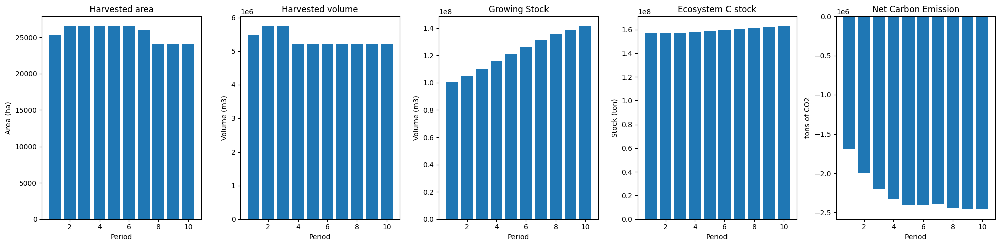

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_60%_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  56452
The economic indicator (the provincial government revenues) is:  1925144
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


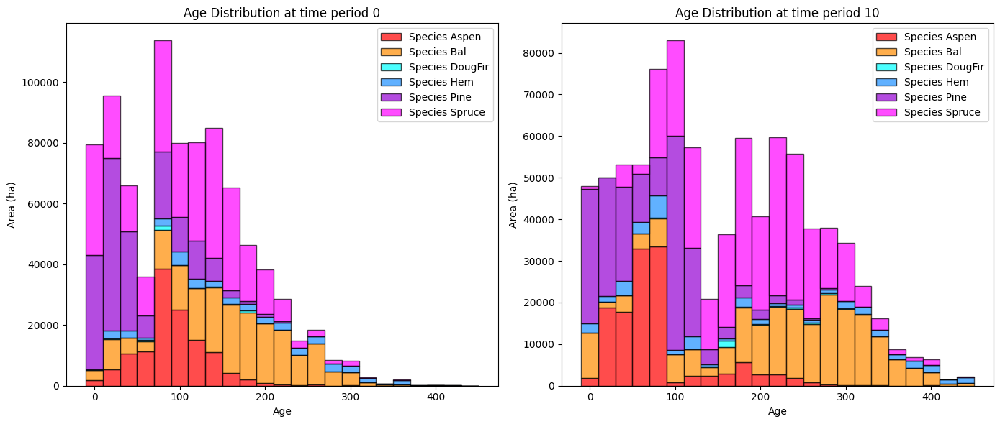

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_60%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229   18226.266728    -925.860501
DougFir    947.047810    2663.605097    1716.557287
Bal      59315.970469  134534.161261   75218.190792
Spruce   36410.744598  188490.244656  152079.500058
Aspen    29632.731169   20698.520701   -8934.210469
Pine      7432.733686   13606.620254    6173.886568

Overall diversity has **increased** by 225328.06 hectares from time period 0 to time period 10.


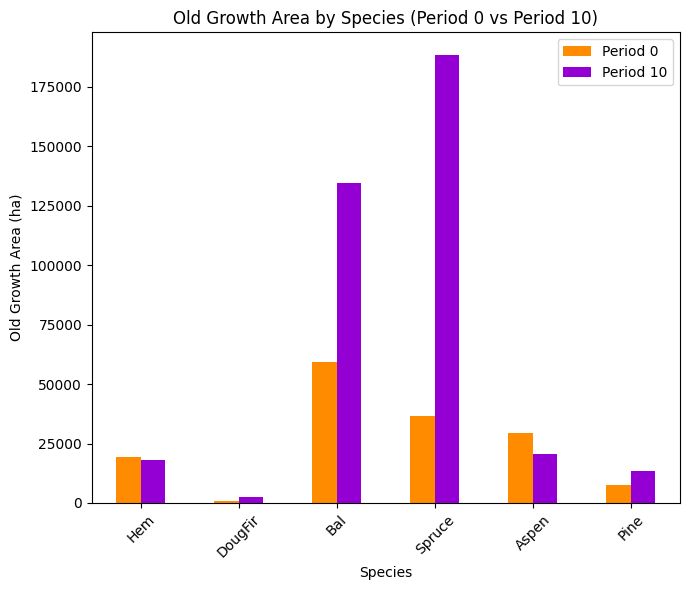

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_60%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7183

Diversity has **decreased** by 4.09% from time 0 to time 10.


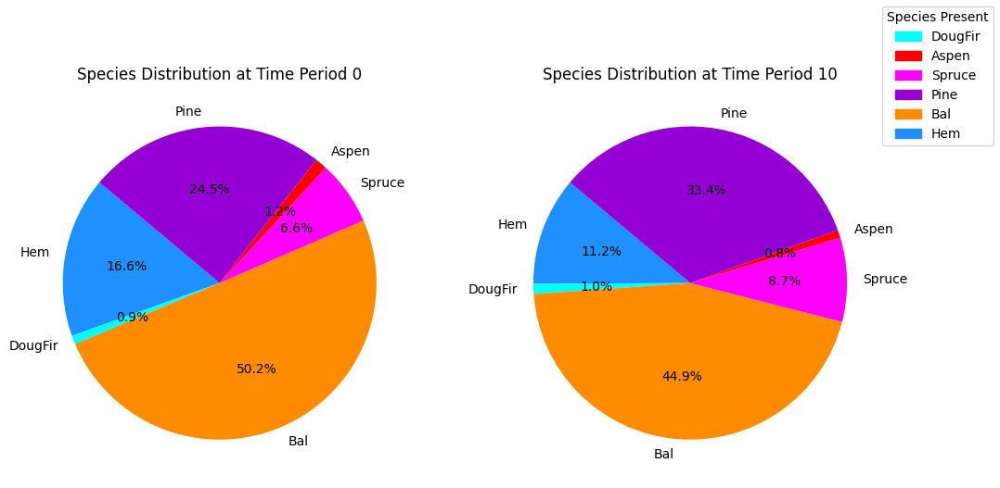

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_60%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x67e9da31
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.30s
Presolved: 8375 rows, 74375 columns, 536310 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

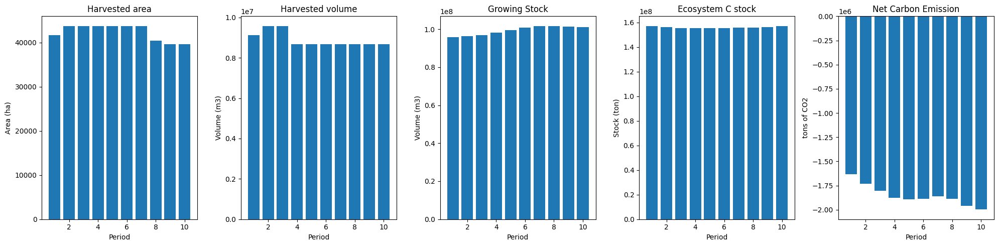

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


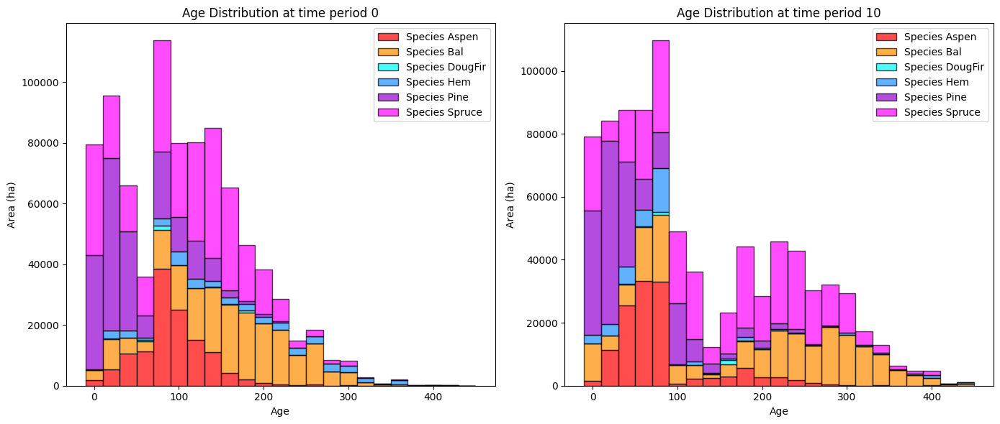

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    6279.556292 -12872.570937
DougFir    947.047810    1312.466058    365.418248
Bal      59315.970469  108811.384782  49495.414314
Spruce   36410.744598  134653.193927  98242.449329
Aspen    29632.731169   20687.141690  -8945.589480
Pine      7432.733686    9982.874965   2550.141279

Overall diversity has **increased** by 128835.26 hectares from time period 0 to time period 10.


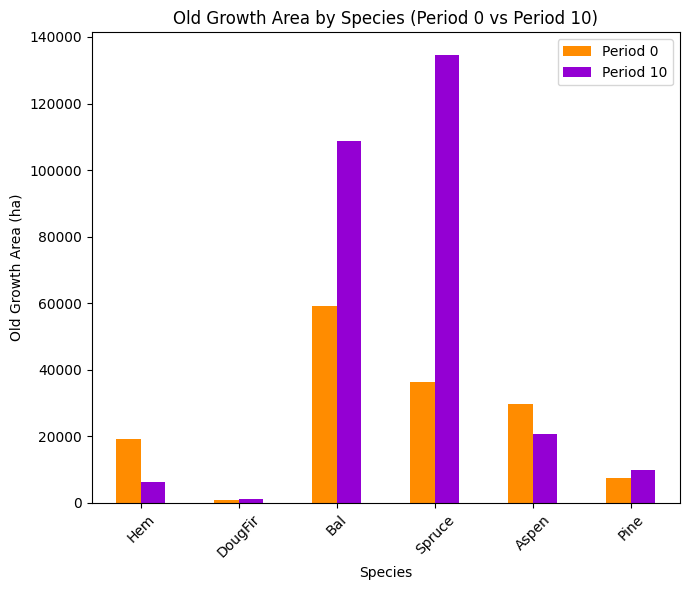

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7128

Diversity has **decreased** by 4.64% from time 0 to time 10.


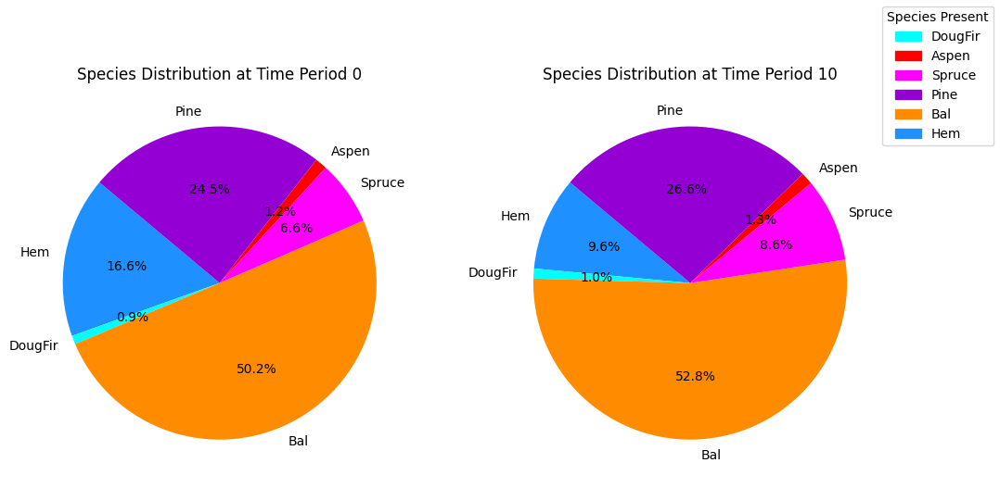

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_species_pie.pdf


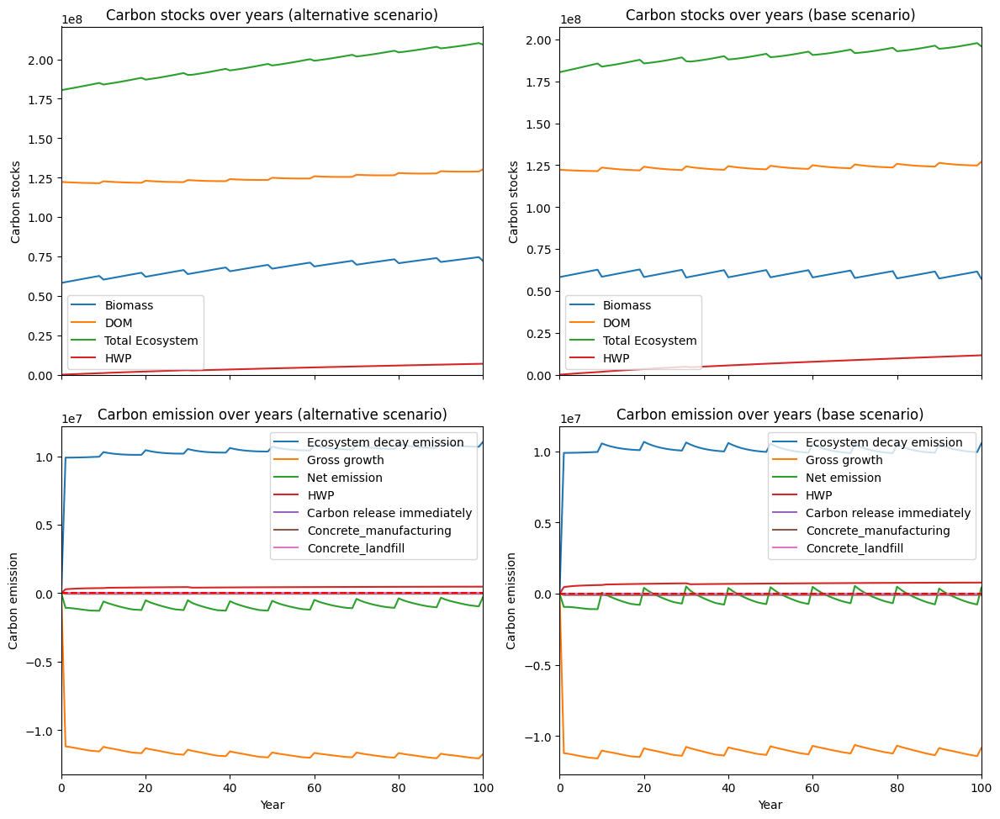

---------------------------------------------------------------------------------------
Net emission difference -11295617.40503083
Net emission base scenario -24466158.08323065
Net emission alternative scenario -13170540.67819982
dollar_per_ton is:  0.8852991068506101
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0  11946.710436  11946.710436
DougFir  0.0   1351.139039   1351.139039
Bal      0.0  25722.776479  25722.776479
Spruce   0.0  53837.050729  53837.050729
Aspen    0.0     11.379011     11.379011
Pine     0.0   3623.745289   3623.745289

Overall, the old growth area has **increased** by 96492.80 hectares in the alternative scenario compared to the base scenario.


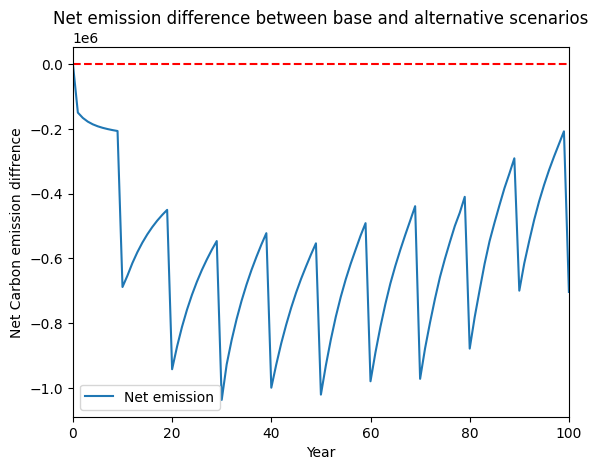

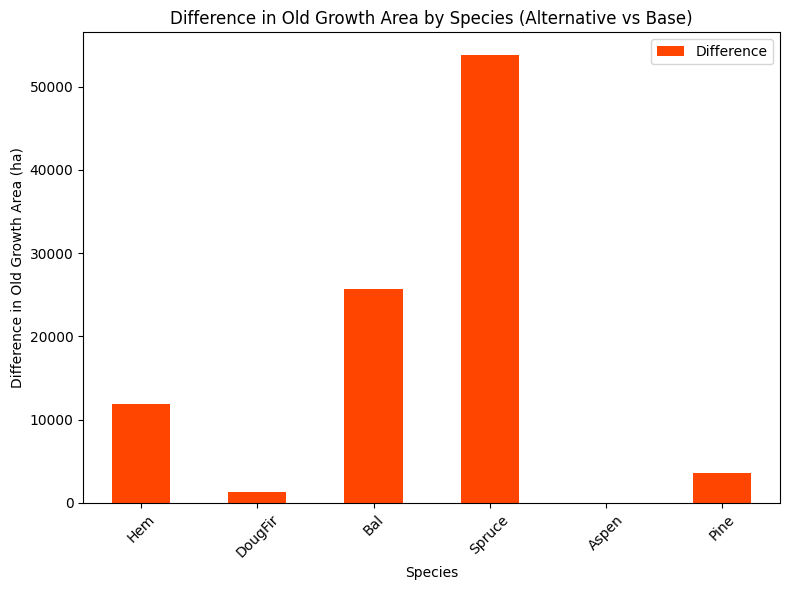

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_age_difference.pdf


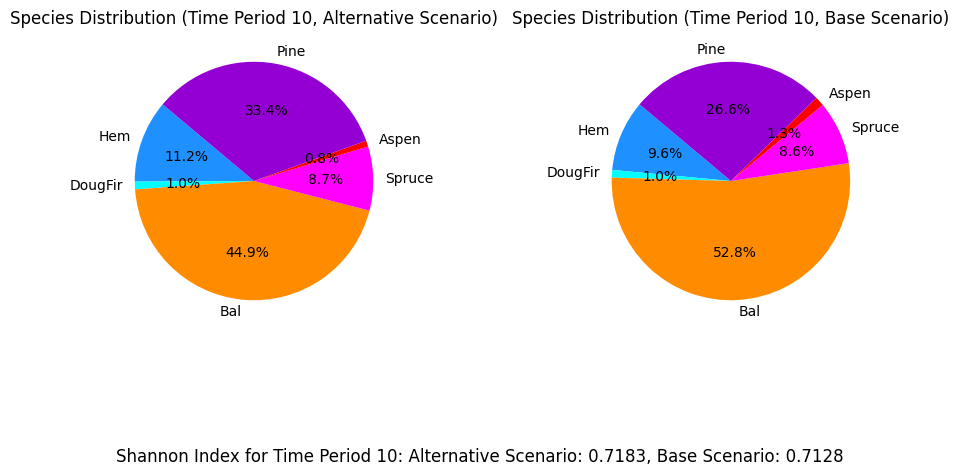

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_min_em_eqtslvr_AAC_50%...
running the scenario for the Equity Silver mining site (50%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xe88b76bf
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8231 rows and 8227 columns
Presolve time: 0.05s

Solved in 0 iter

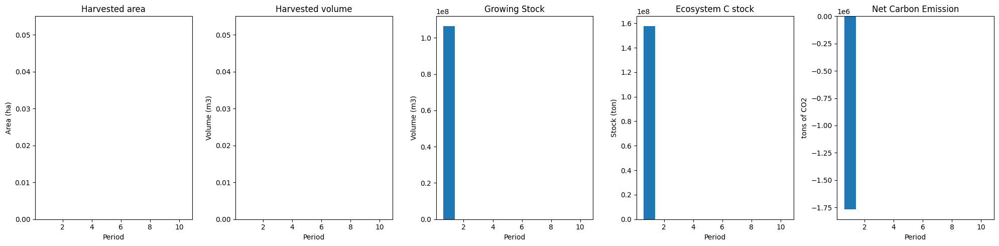

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_50%_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  0
The economic indicator (the provincial government revenues) is:  0
------------------------------------------------


UnboundLocalError: local variable 'sch' referenced before assignment

In [12]:
Start = time.time()
scenario_names = scenario_options.get(case_study, [])
for scenario_name in scenario_names:
    print(f"Running for {case_study}_{obj_mode}_{scenario_name}...")
    results_scenarios(fm, 
                      clt_percentage, 
                      credibility, 
                      budget_input, 
                      n_steps, 
                      max_harvest, 
                      scenario_name, 
                      displacement_effect, 
                      hwp_pool_effect_value, 
                      release_immediately_value, 
                      case_study, 
                      obj_mode,                   
                      pickle_output_base=False, 
                      pickle_output_alter=False)
print('It took', round((time.time() - Start) / 60, 1), "minutes to run all scenarios.")

Running for equitysilver_min_em_eqtslvr_AAC_50%...
running the scenario for the Equity Silver mining site (50%_AAC),
Set parameter Username
Academic license - for non-commercial use only - expires 2025-01-09
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xe952bb0e
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.25s
Presolved: 8375 rows, 74375 columns, 536310 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier l

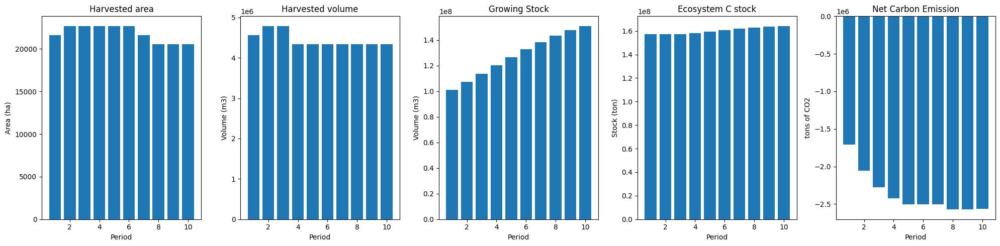

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_50%_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  47043
The economic indicator (the provincial government revenues) is:  1604286
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


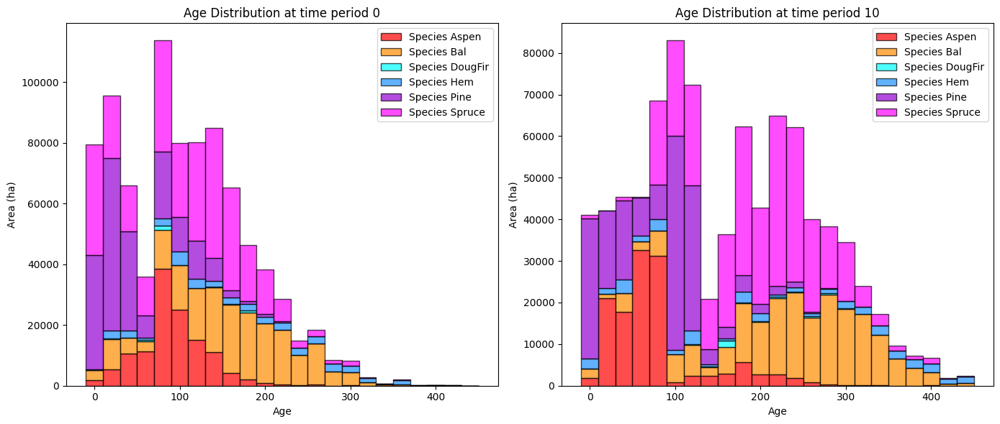

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_50%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229   22064.066086    2911.938857
DougFir    947.047810    2749.298212    1802.250402
Bal      59315.970469  144560.269229   85244.298760
Spruce   36410.744598  195902.116987  159491.372389
Aspen    29632.731169   20697.809369   -8934.921801
Pine      7432.733686   17510.038536   10077.304850

Overall diversity has **increased** by 250592.24 hectares from time period 0 to time period 10.


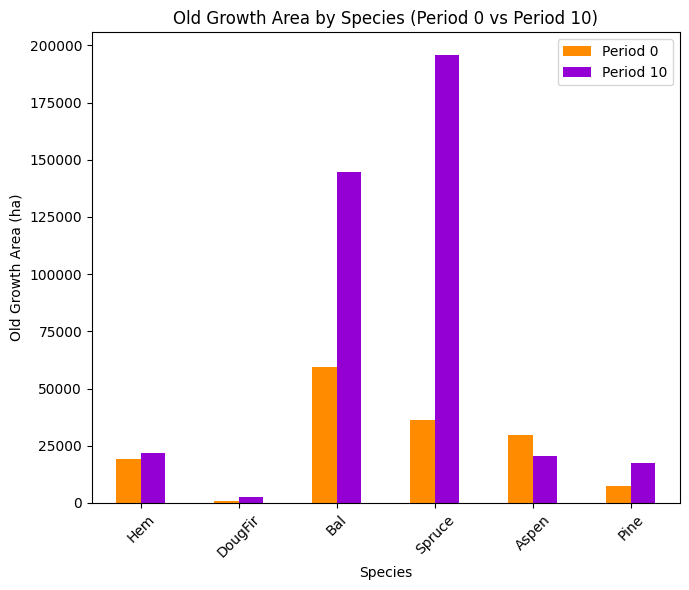

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_50%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7179

Diversity has **decreased** by 4.13% from time 0 to time 10.


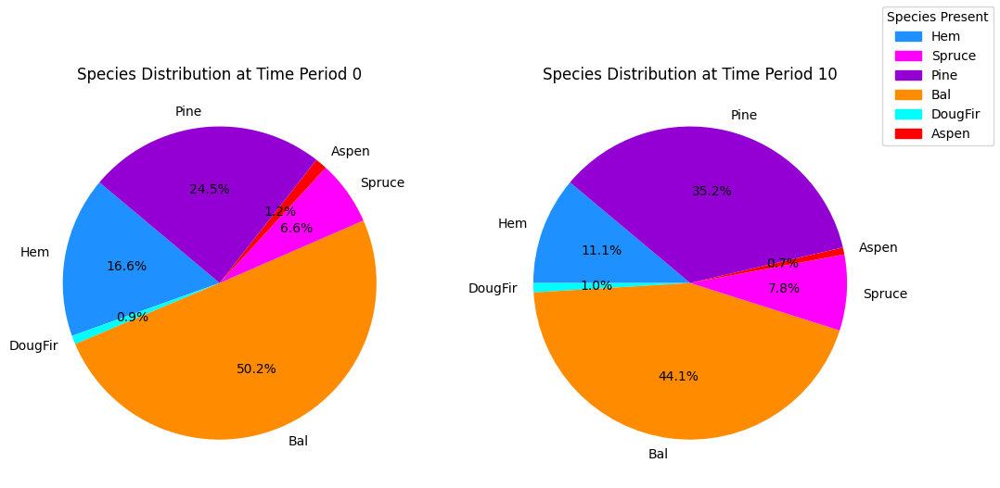

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_50%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x67e9da31
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.28s
Presolved: 8375 rows, 74375 columns, 536310 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

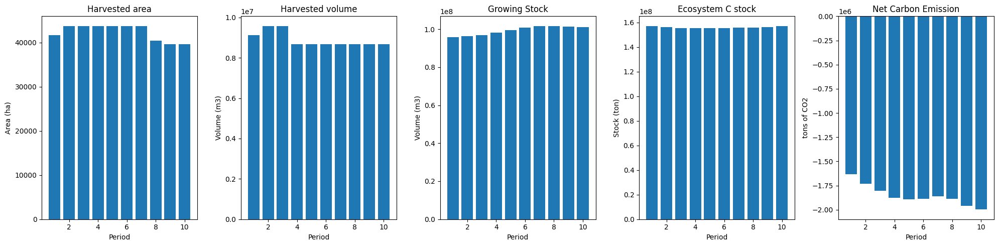

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


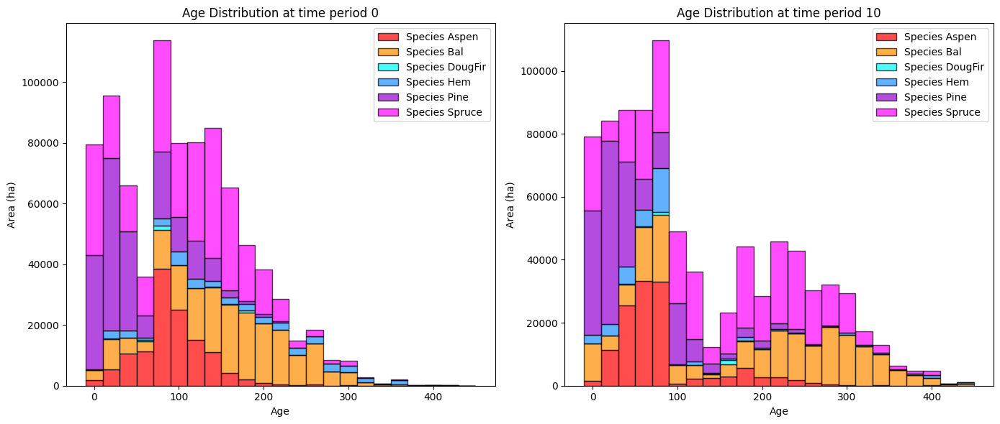

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    6279.556292 -12872.570937
DougFir    947.047810    1312.466058    365.418248
Bal      59315.970469  108811.384782  49495.414314
Spruce   36410.744598  134653.193927  98242.449329
Aspen    29632.731169   20687.141690  -8945.589480
Pine      7432.733686    9982.874965   2550.141279

Overall diversity has **increased** by 128835.26 hectares from time period 0 to time period 10.


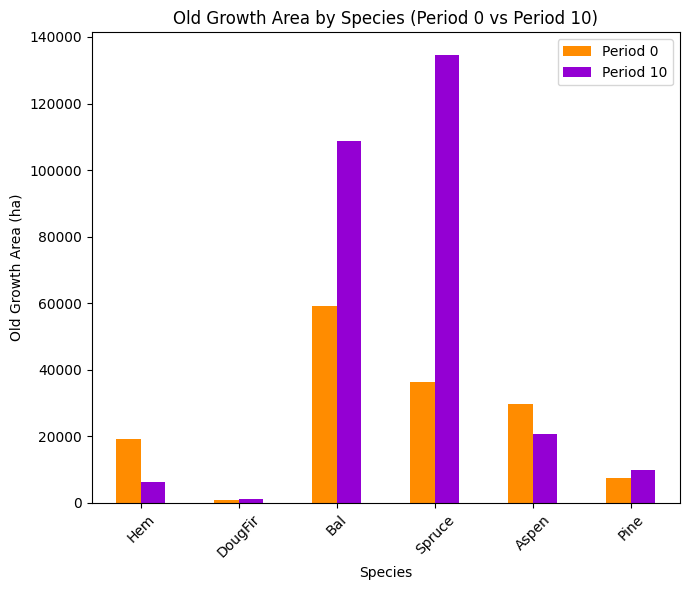

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7128

Diversity has **decreased** by 4.64% from time 0 to time 10.


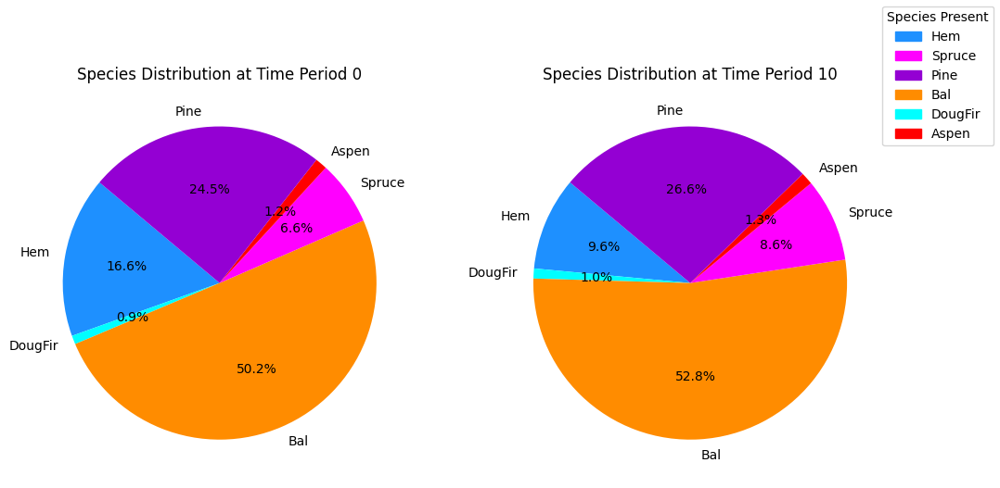

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_species_pie.pdf


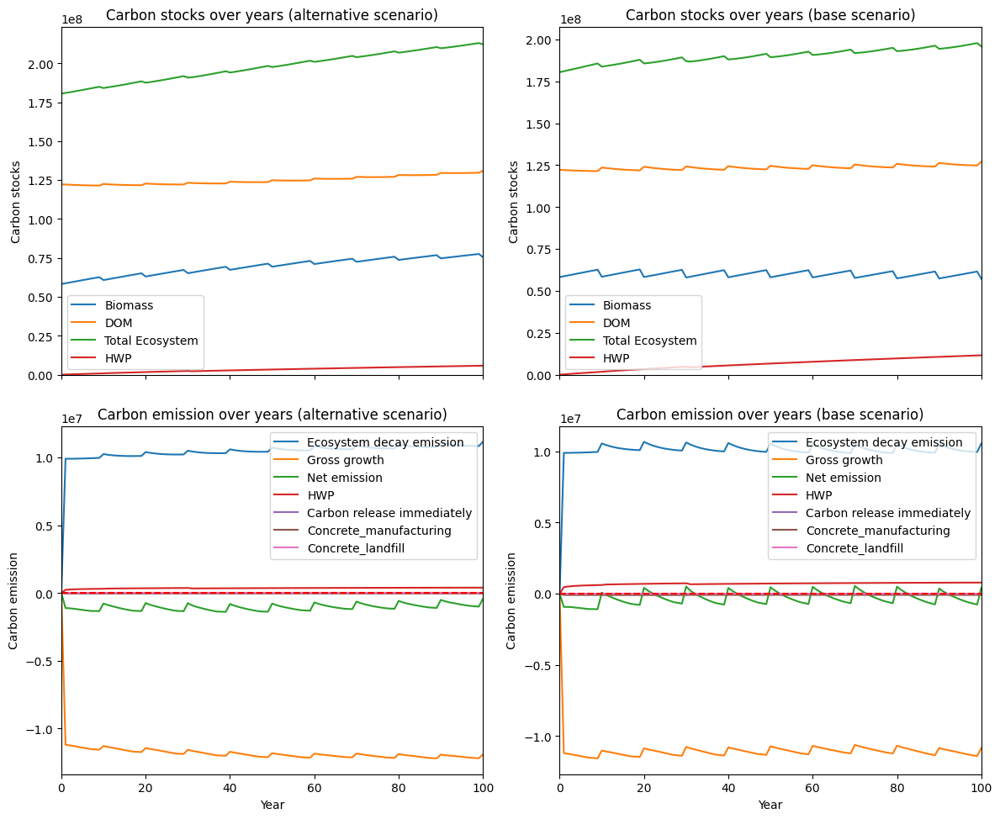

---------------------------------------------------------------------------------------
Net emission difference -13923948.89411672
Net emission base scenario -27094489.57231654
Net emission alternative scenario -13170540.67819982
dollar_per_ton is:  0.7181870657558428
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0  15784.509794  15784.509794
DougFir  0.0   1436.832154   1436.832154
Bal      0.0  35748.884447  35748.884447
Spruce   0.0  61248.923060  61248.923060
Aspen    0.0     10.667679     10.667679
Pine     0.0   7527.163571   7527.163571

Overall, the old growth area has **increased** by 121756.98 hectares in the alternative scenario compared to the base scenario.


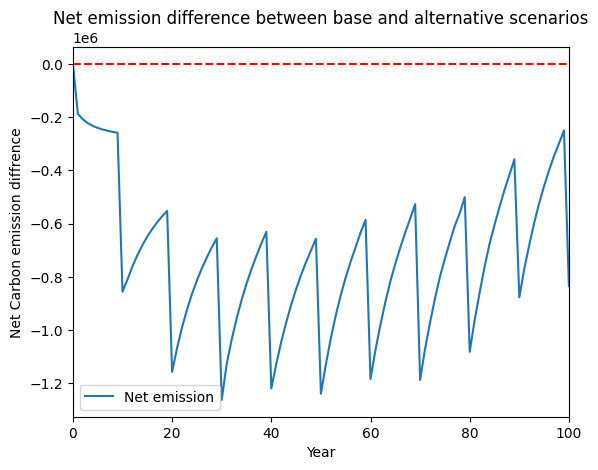

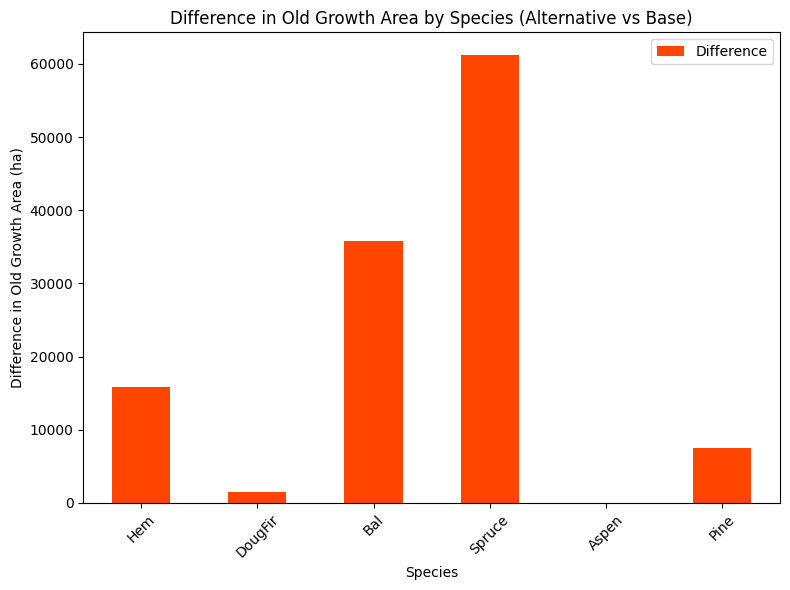

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_age_difference.pdf


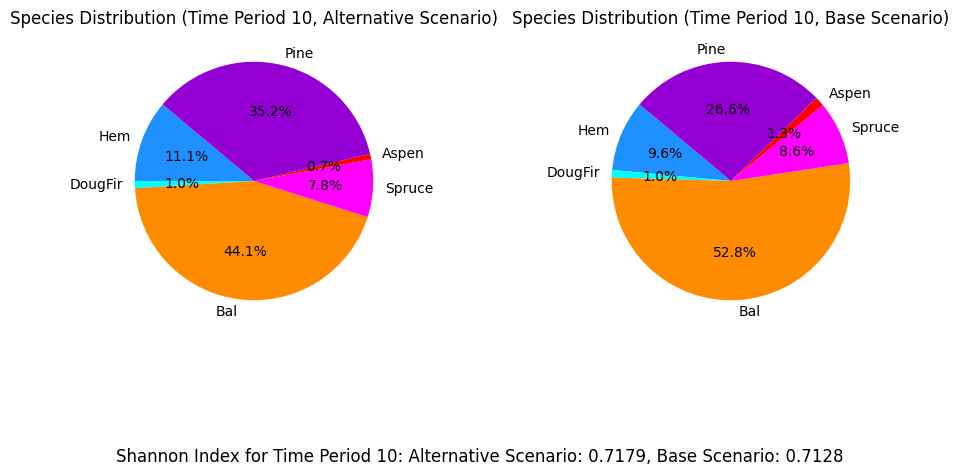

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_min_em_eqtslvr_AAC_40%...
running the scenario for the Equity Silver mining site (40%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xb0a13ca0
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.26s
Presolved: 8375 r

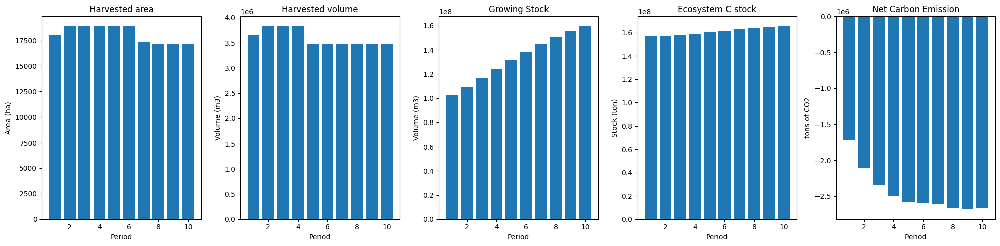

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_40%_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  38020
The economic indicator (the provincial government revenues) is:  1296592
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


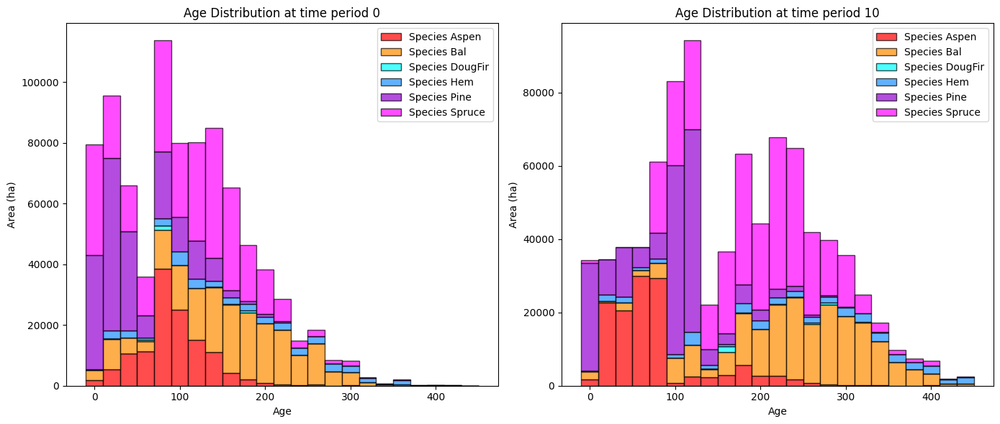

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_40%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229   27380.470574    8228.343345
DougFir    947.047810    2749.298212    1802.250402
Bal      59315.970469  149332.675935   90016.705467
Spruce   36410.744598  197818.592269  161407.847671
Aspen    29632.731169   20732.721399   -8900.009771
Pine      7432.733686   24661.133590   17228.399903

Overall diversity has **increased** by 269783.54 hectares from time period 0 to time period 10.


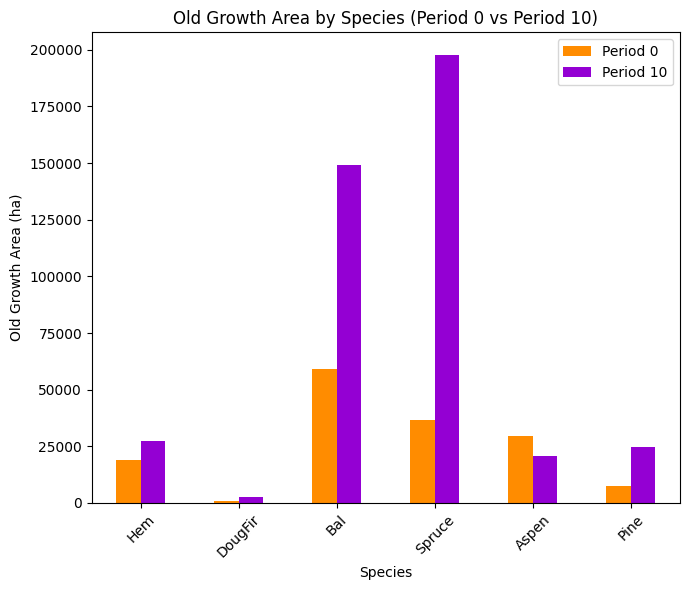

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_40%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7220

Diversity has **decreased** by 3.72% from time 0 to time 10.


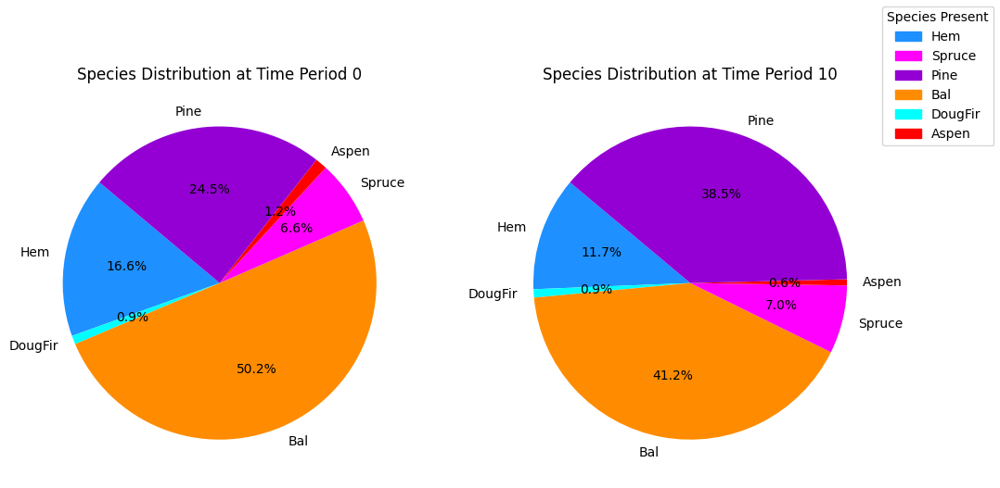

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_40%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x67e9da31
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.28s
Presolved: 8375 rows, 74375 columns, 536310 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

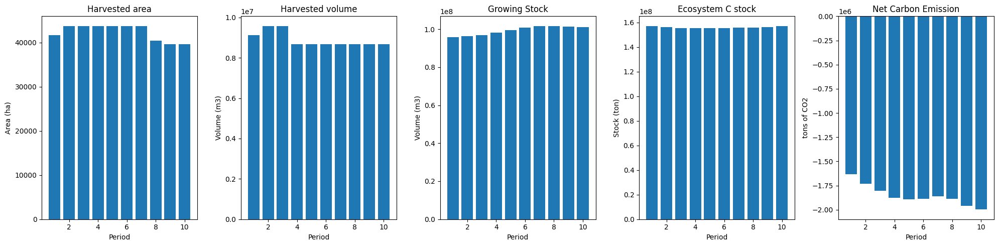

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


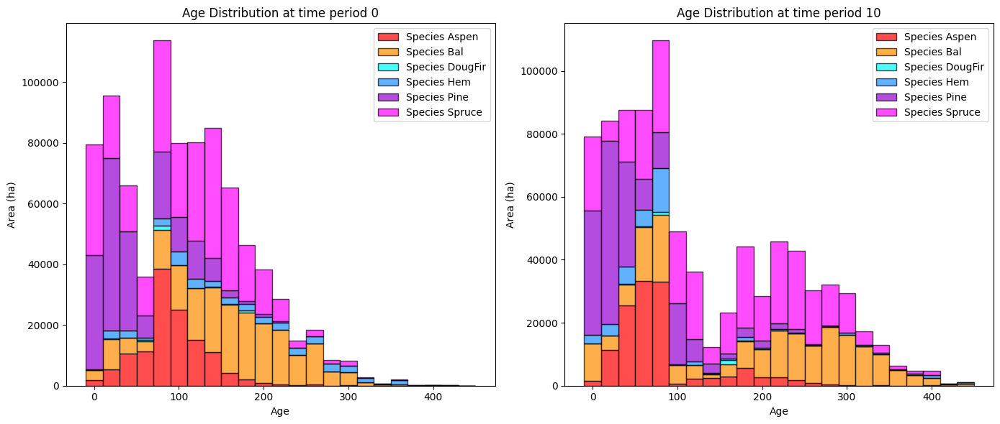

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    6279.556292 -12872.570937
DougFir    947.047810    1312.466058    365.418248
Bal      59315.970469  108811.384782  49495.414314
Spruce   36410.744598  134653.193927  98242.449329
Aspen    29632.731169   20687.141690  -8945.589480
Pine      7432.733686    9982.874965   2550.141279

Overall diversity has **increased** by 128835.26 hectares from time period 0 to time period 10.


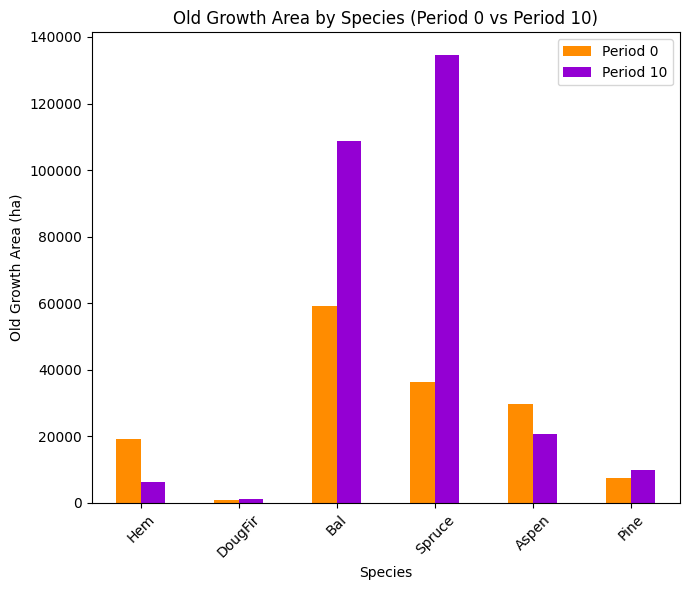

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7128

Diversity has **decreased** by 4.64% from time 0 to time 10.


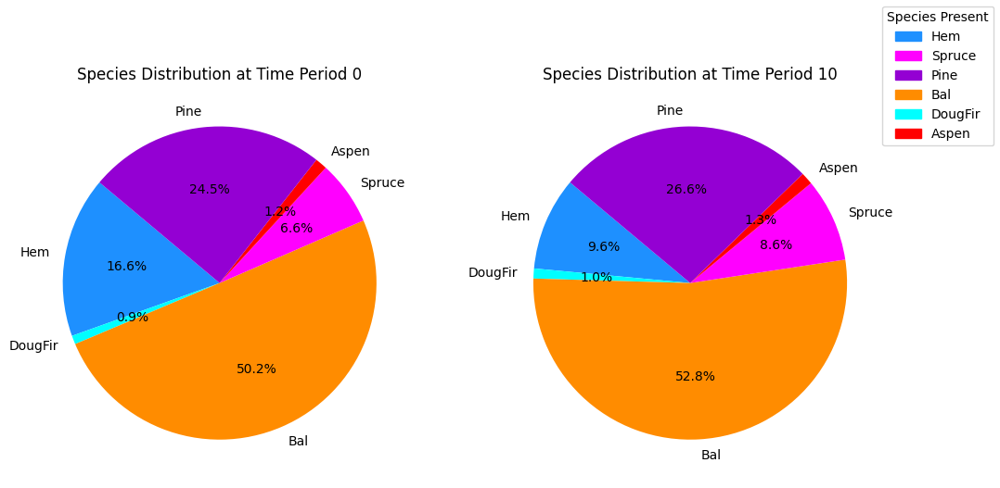

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_species_pie.pdf


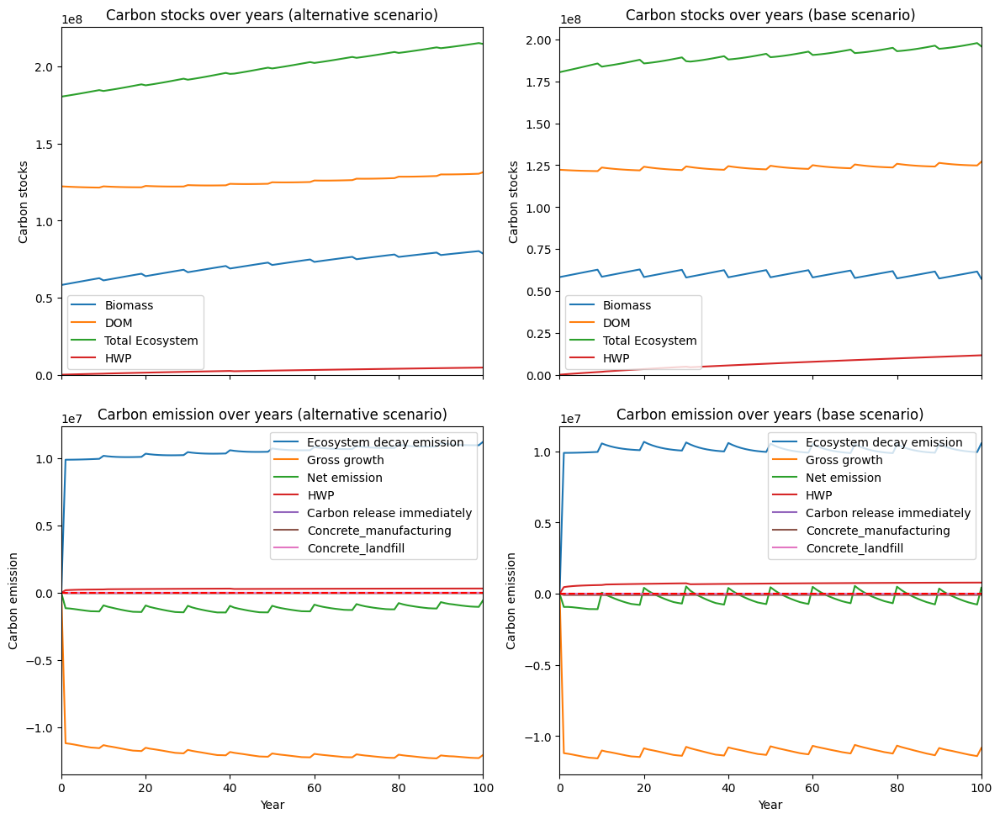

---------------------------------------------------------------------------------------
Net emission difference -16487554.787160052
Net emission base scenario -29658095.465359867
Net emission alternative scenario -13170540.67819982
dollar_per_ton is:  0.6065180755479679
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0  21100.914282  21100.914282
DougFir  0.0   1436.832154   1436.832154
Bal      0.0  40521.291153  40521.291153
Spruce   0.0  63165.398342  63165.398342
Aspen    0.0     45.579709     45.579709
Pine     0.0  14678.258624  14678.258624

Overall, the old growth area has **increased** by 140948.27 hectares in the alternative scenario compared to the base scenario.


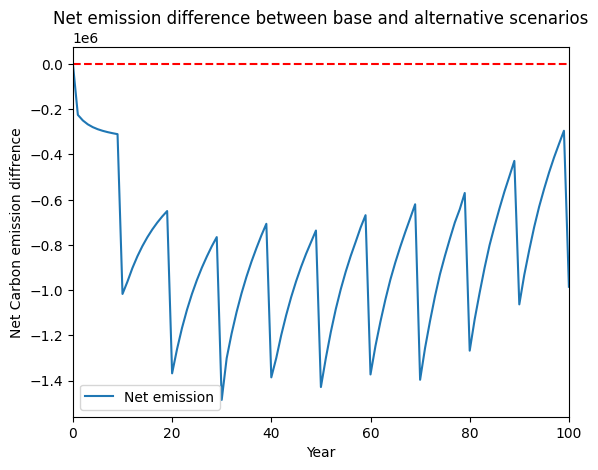

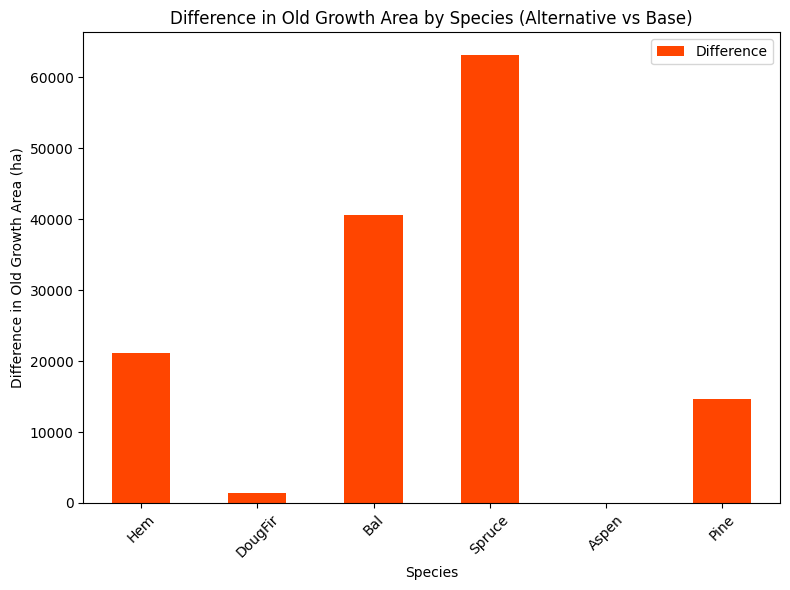

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_age_difference.pdf


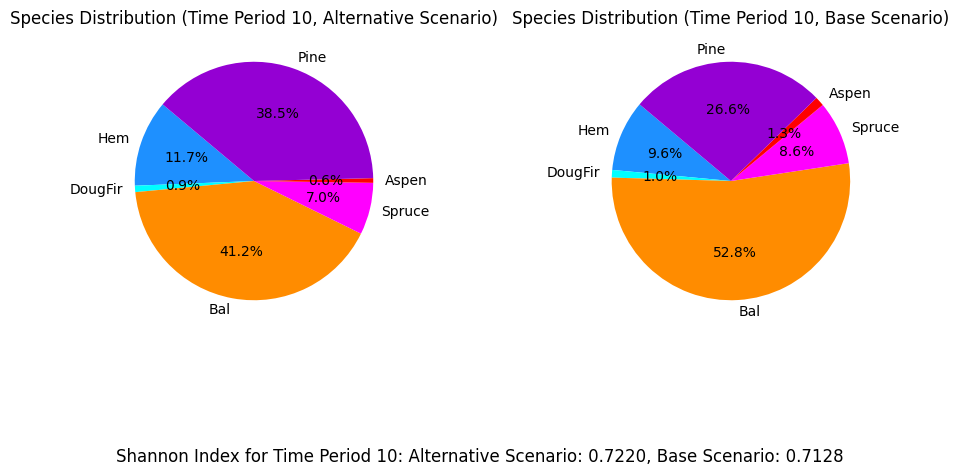

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_min_em_eqtslvr_AAC_30%...
running the scenario for the Equity Silver mining site (30%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x697eaca8
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.29s
Presolved: 8375 r

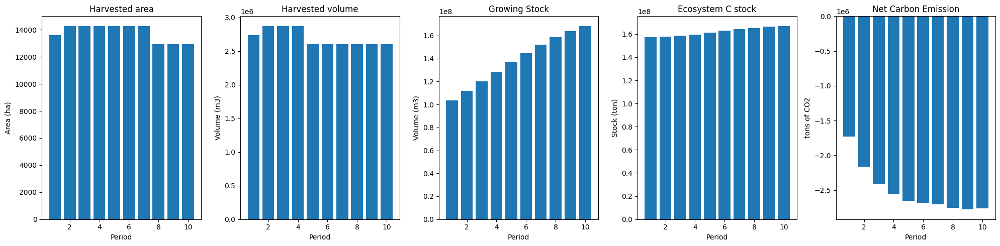

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_30%_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  28515
The economic indicator (the provincial government revenues) is:  972444
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


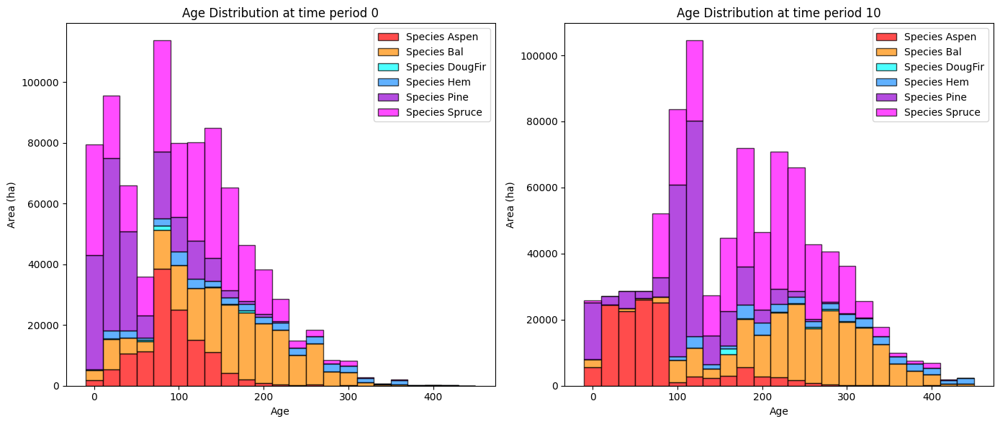

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_30%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229   32688.964561   13536.837333
DougFir    947.047810    2749.298212    1802.250402
Bal      59315.970469  153625.939493   94309.969024
Spruce   36410.744598  197818.592269  161407.847671
Aspen    29632.731169   20999.161872   -8633.569297
Pine      7432.733686   43098.353107   35665.619421

Overall diversity has **increased** by 298088.95 hectares from time period 0 to time period 10.


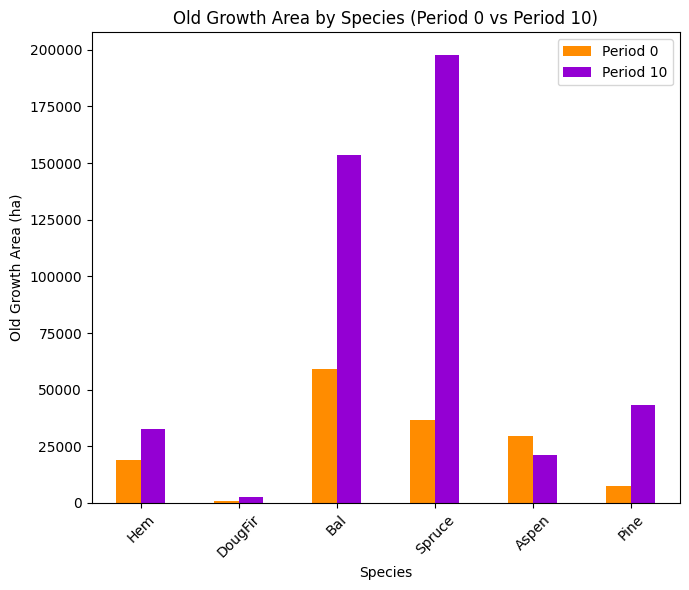

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_30%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7226

Diversity has **decreased** by 3.66% from time 0 to time 10.


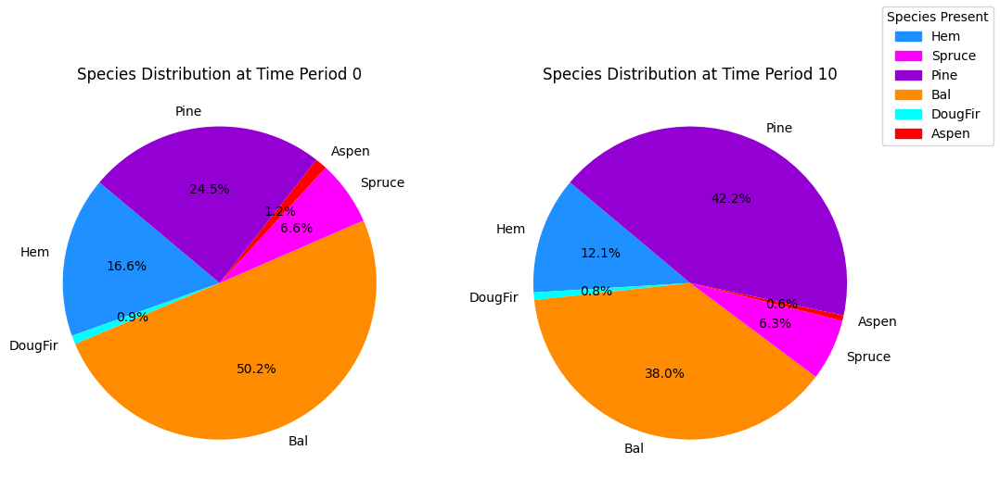

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_30%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x67e9da31
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.28s
Presolved: 8375 rows, 74375 columns, 536310 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

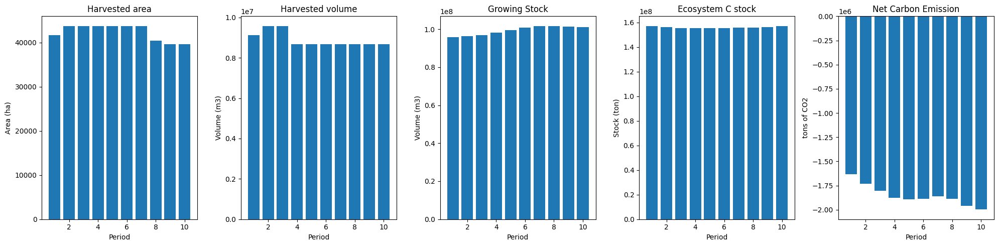

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


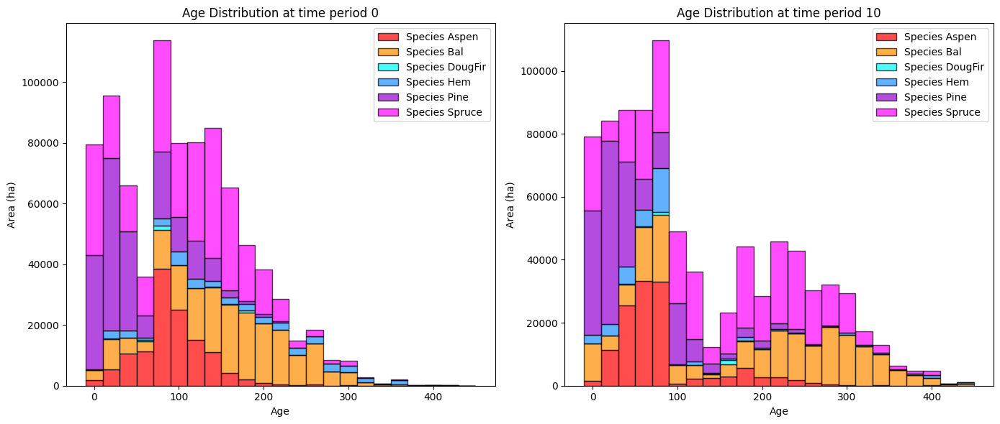

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    6279.556292 -12872.570937
DougFir    947.047810    1312.466058    365.418248
Bal      59315.970469  108811.384782  49495.414314
Spruce   36410.744598  134653.193927  98242.449329
Aspen    29632.731169   20687.141690  -8945.589480
Pine      7432.733686    9982.874965   2550.141279

Overall diversity has **increased** by 128835.26 hectares from time period 0 to time period 10.


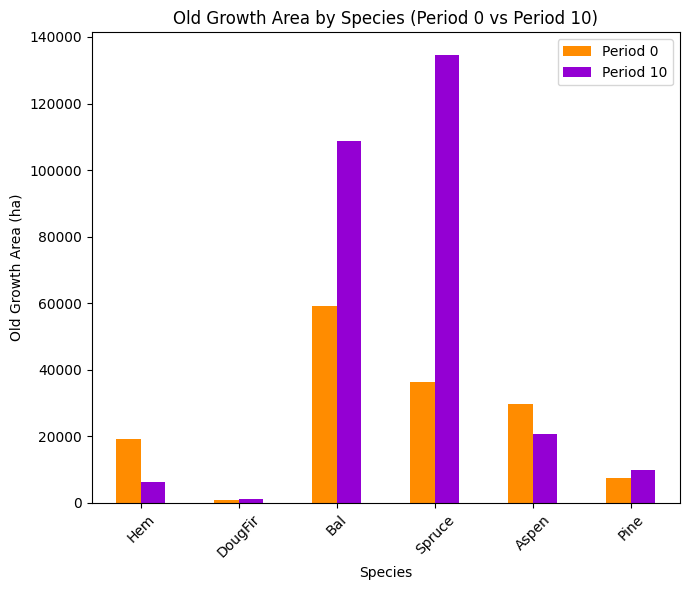

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7128

Diversity has **decreased** by 4.64% from time 0 to time 10.


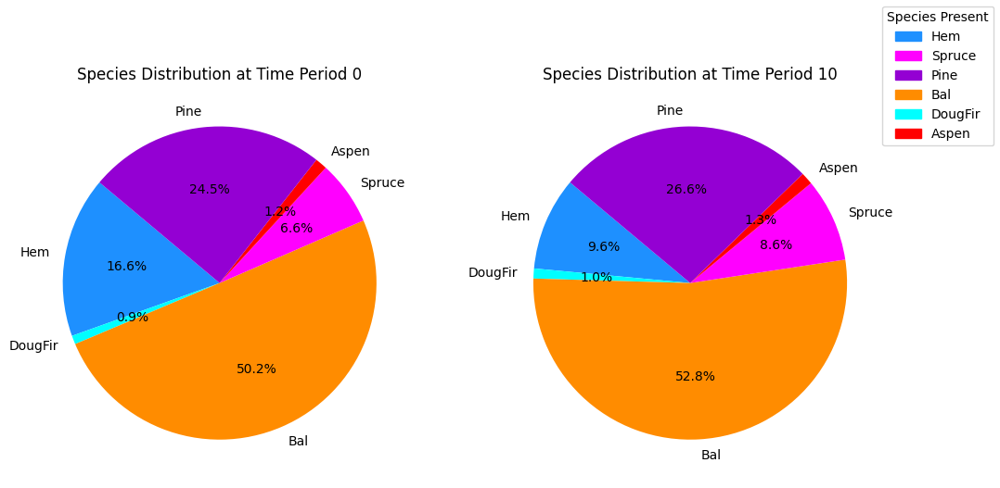

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_species_pie.pdf


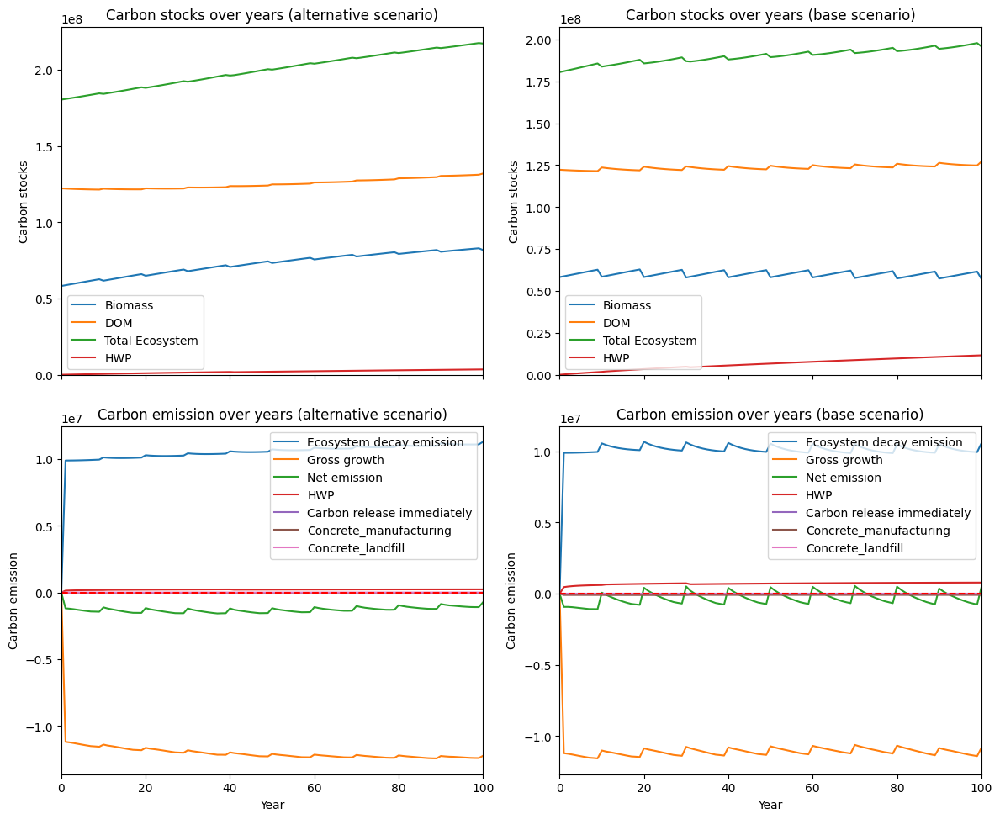

---------------------------------------------------------------------------------------
Net emission difference -19108144.48359047
Net emission base scenario -32278685.16179028
Net emission alternative scenario -13170540.67819982
dollar_per_ton is:  0.5233370518308419
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0  26409.408269  26409.408269
DougFir  0.0   1436.832154   1436.832154
Bal      0.0  44814.554711  44814.554711
Spruce   0.0  63165.398342  63165.398342
Aspen    0.0    312.020182    312.020182
Pine     0.0  33115.478141  33115.478141

Overall, the old growth area has **increased** by 169253.69 hectares in the alternative scenario compared to the base scenario.


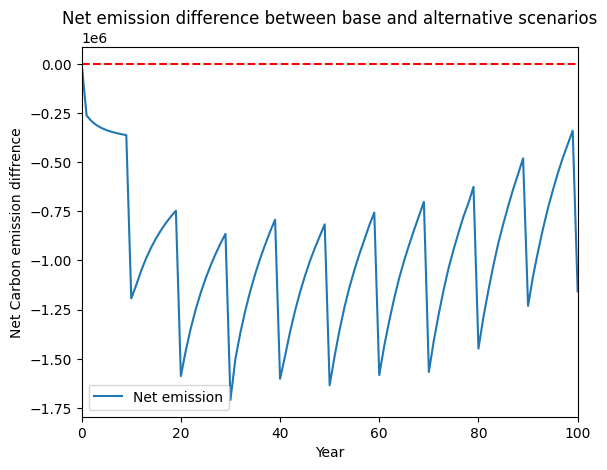

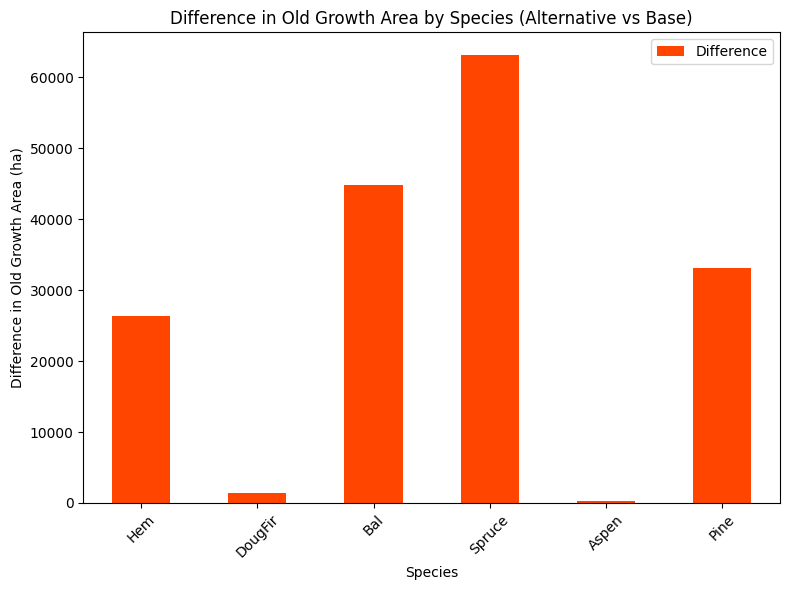

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_age_difference.pdf


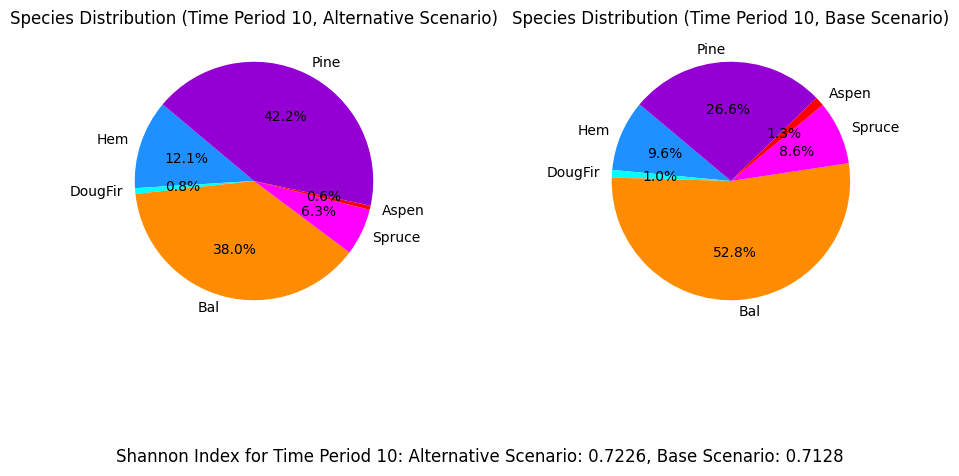

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_min_em_eqtslvr_AAC_20%...
running the scenario for the Equity Silver mining site (20%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xa6b103b8
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.24s
Presolved: 8375 r

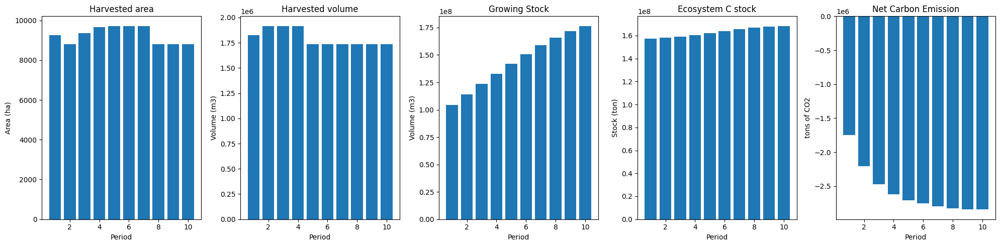

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_20%_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  19010
The economic indicator (the provincial government revenues) is:  648296
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


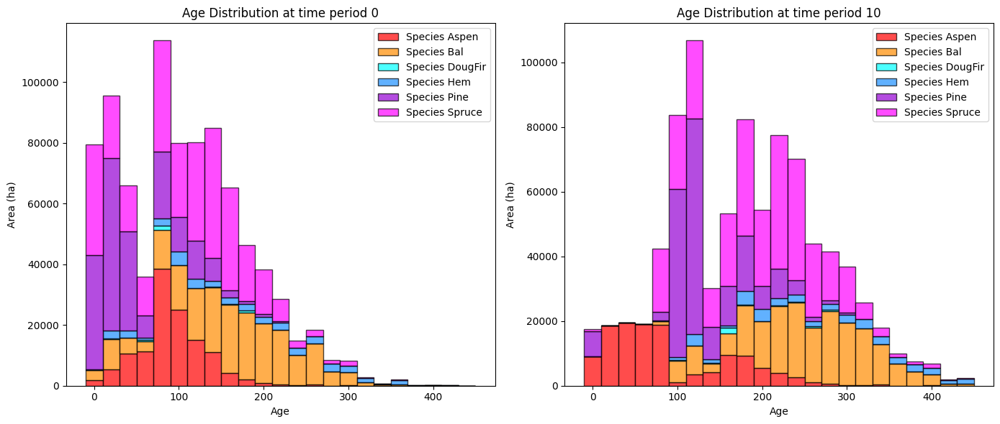

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_20%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229   32688.964561   13536.837333
DougFir    947.047810    2749.298212    1802.250402
Bal      59315.970469  157689.747715   98373.777247
Spruce   36410.744598  197818.592269  161407.847671
Aspen    29632.731169   38809.469634    9176.738465
Pine      7432.733686   63136.346663   55703.612977

Overall diversity has **increased** by 340001.06 hectares from time period 0 to time period 10.


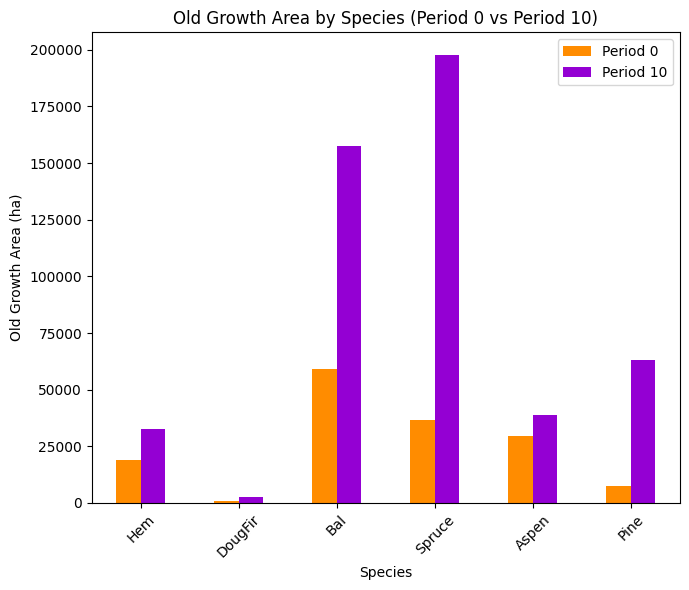

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_20%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7254

Diversity has **decreased** by 3.38% from time 0 to time 10.


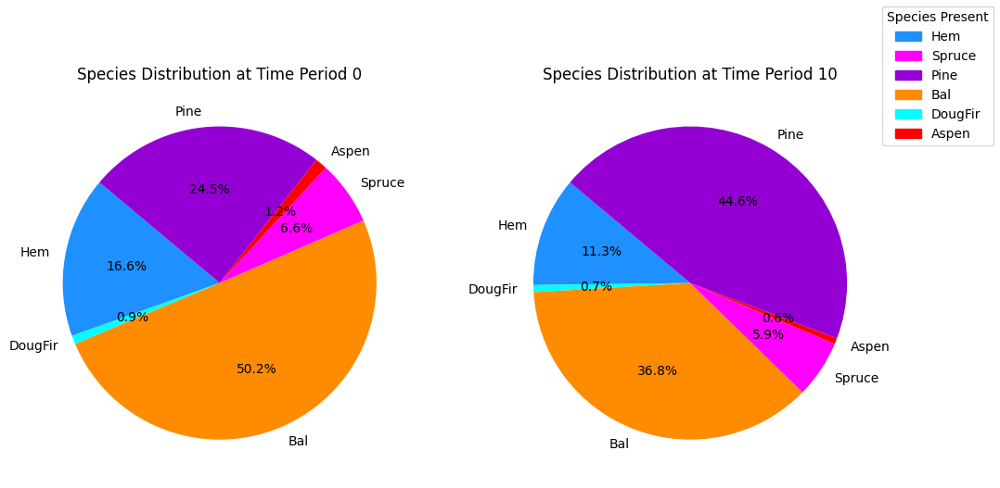

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_20%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x67e9da31
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.23s
Presolved: 8375 rows, 74375 columns, 536310 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

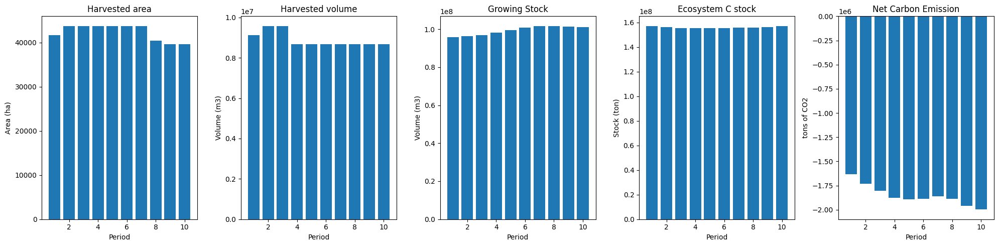

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


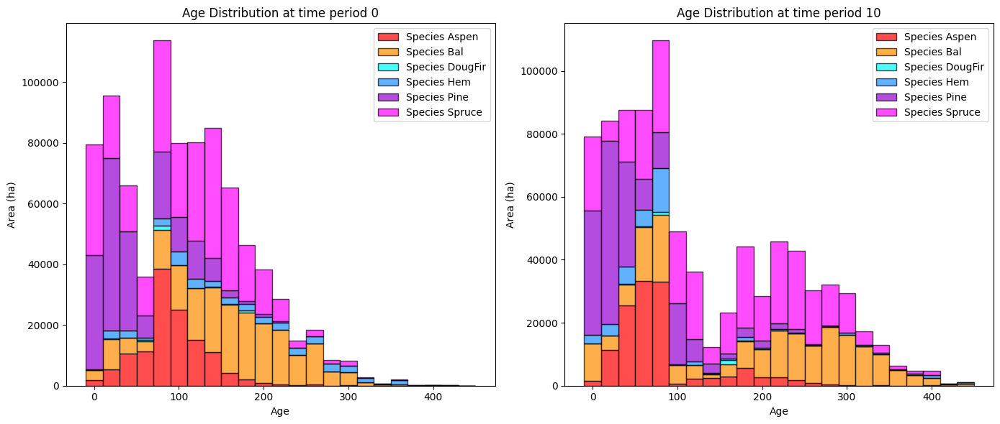

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    6279.556292 -12872.570937
DougFir    947.047810    1312.466058    365.418248
Bal      59315.970469  108811.384782  49495.414314
Spruce   36410.744598  134653.193927  98242.449329
Aspen    29632.731169   20687.141690  -8945.589480
Pine      7432.733686    9982.874965   2550.141279

Overall diversity has **increased** by 128835.26 hectares from time period 0 to time period 10.


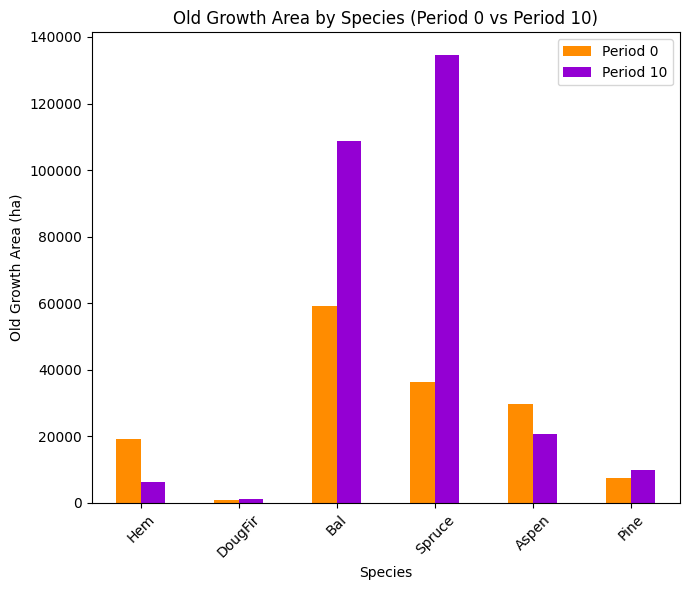

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7128

Diversity has **decreased** by 4.64% from time 0 to time 10.


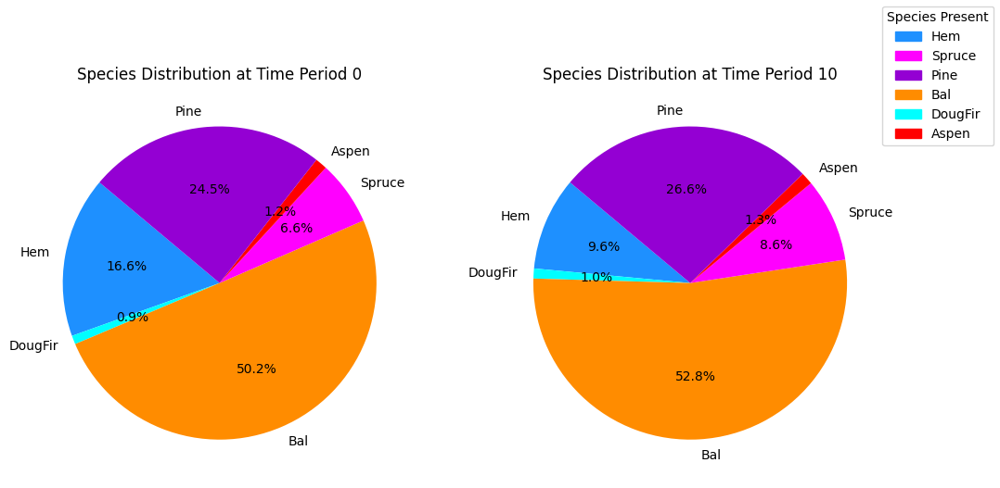

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_species_pie.pdf


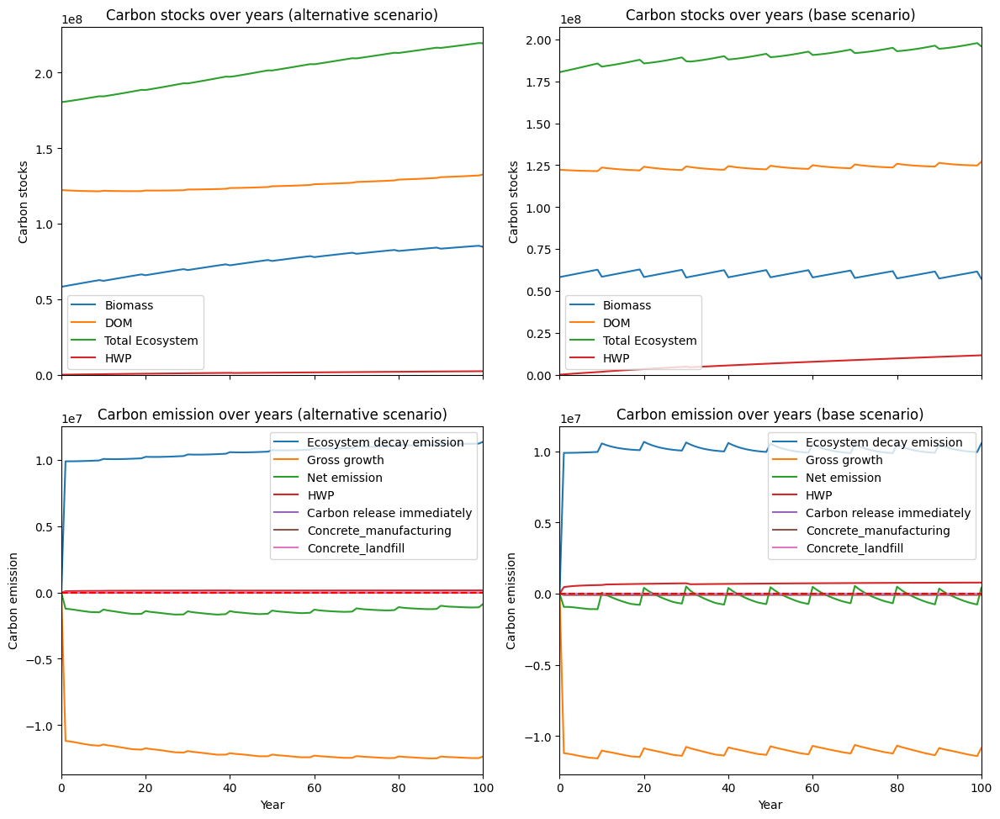

---------------------------------------------------------------------------------------
Net emission difference -21647572.56351851
Net emission base scenario -34818113.24171833
Net emission alternative scenario -13170540.67819982
dollar_per_ton is:  0.4619455585912881
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0  26409.408269  26409.408269
DougFir  0.0   1436.832154   1436.832154
Bal      0.0  48878.362933  48878.362933
Spruce   0.0  63165.398342  63165.398342
Aspen    0.0  18122.327945  18122.327945
Pine     0.0  53153.471697  53153.471697

Overall, the old growth area has **increased** by 211165.80 hectares in the alternative scenario compared to the base scenario.


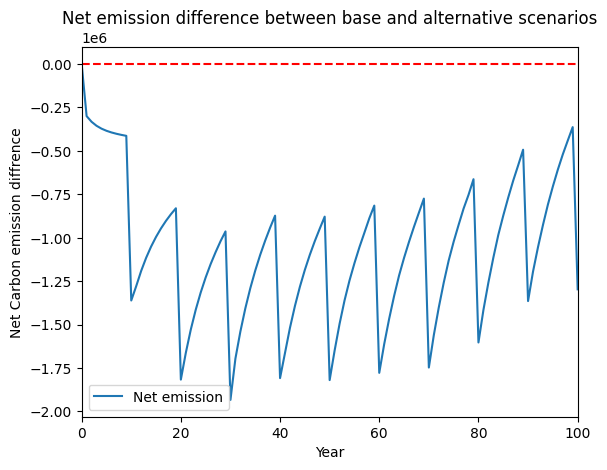

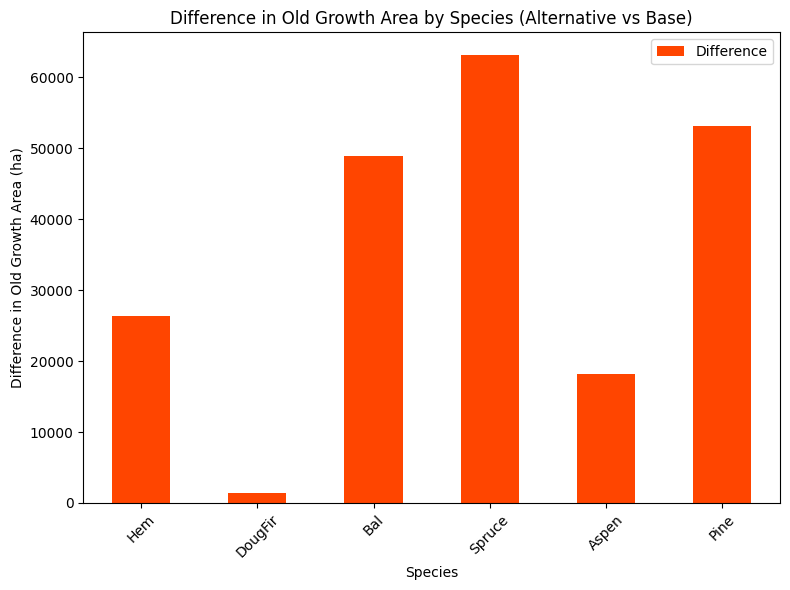

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_age_difference.pdf


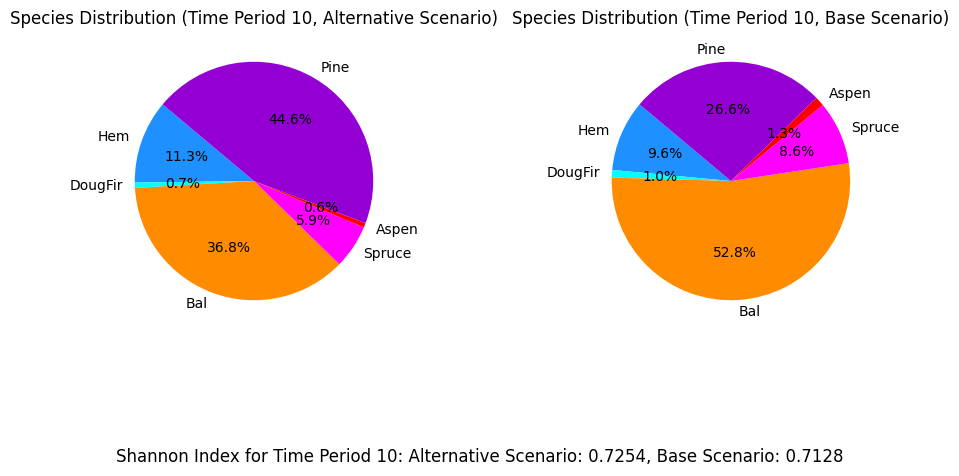

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for equitysilver_min_em_eqtslvr_AAC_10%...
running the scenario for the Equity Silver mining site (10%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0xdd83721b
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.22s
Presolved: 8375 r

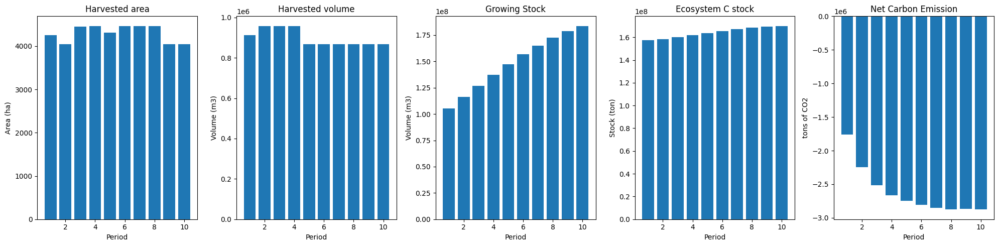

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_10%_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  9505
The economic indicator (the provincial government revenues) is:  324148
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


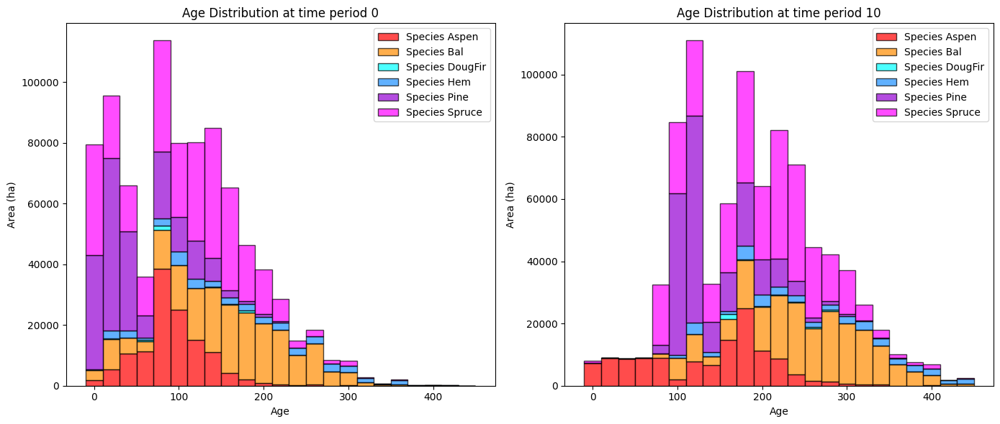

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_10%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10     Difference
Hem      19152.127229   32688.964561   13536.837333
DougFir    947.047810    2749.298212    1802.250402
Bal      59315.970469  157689.747715   98373.777247
Spruce   36410.744598  197818.592269  161407.847671
Aspen    29632.731169   77365.171979   47732.440810
Pine      7432.733686   70671.811755   63239.078069

Overall diversity has **increased** by 386092.23 hectares from time period 0 to time period 10.


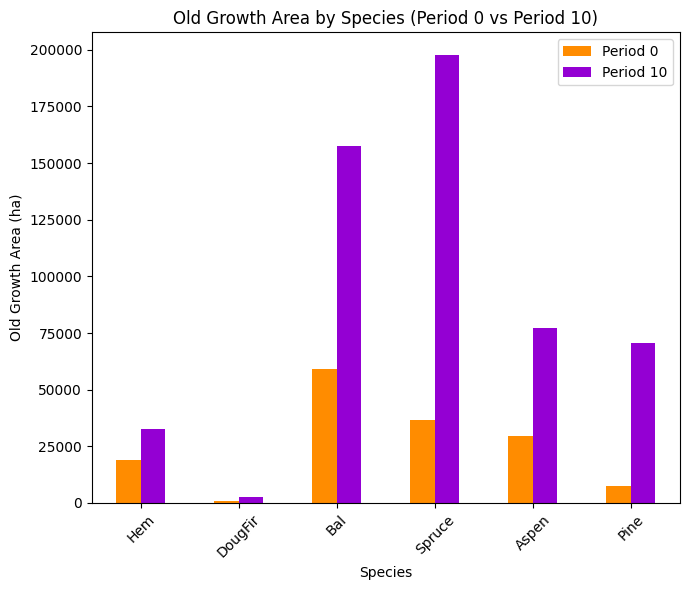

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_10%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7374

Diversity has **decreased** by 2.18% from time 0 to time 10.


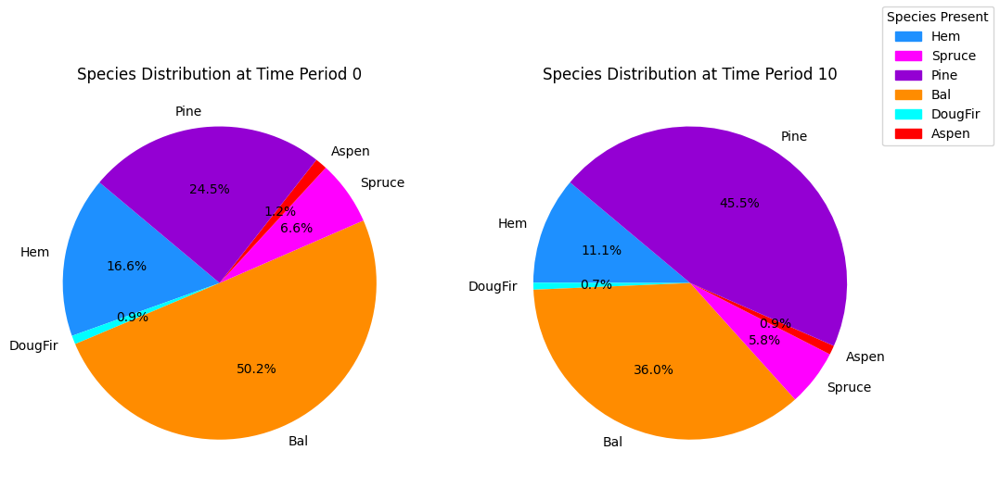

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_eqtslvr_AAC_10%_species_pie.pdf
running business as usual scenario for the Equity Silver mining site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 17067 rows, 83258 columns and 631504 nonzeros
Model fingerprint: 0x67e9da31
Coefficient statistics:
  Matrix range     [5e-03, 7e+05]
  Objective range  [4e-03, 2e+05]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+11]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 8692 rows and 8884 columns
Presolve time: 0.27s
Presolved: 8375 rows, 74375 columns, 536310 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Or

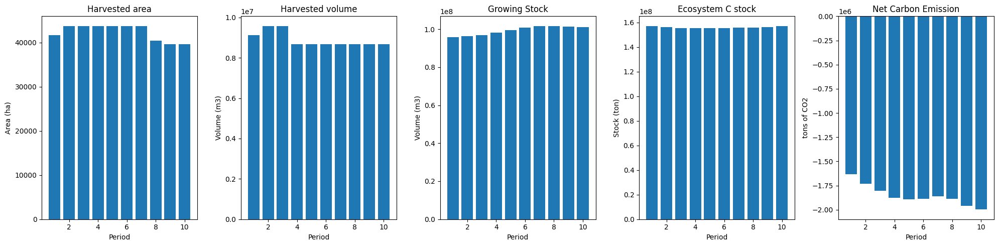

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_scheduling_minemission.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  94087
The economic indicator (the provincial government revenues) is:  3208573
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


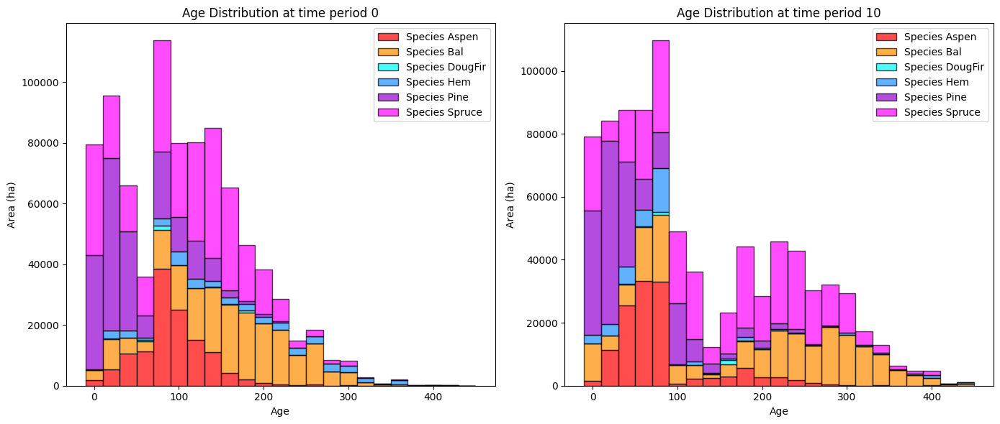

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                    0             10    Difference
Hem      19152.127229    6279.556292 -12872.570937
DougFir    947.047810    1312.466058    365.418248
Bal      59315.970469  108811.384782  49495.414314
Spruce   36410.744598  134653.193927  98242.449329
Aspen    29632.731169   20687.141690  -8945.589480
Pine      7432.733686    9982.874965   2550.141279

Overall diversity has **increased** by 128835.26 hectares from time period 0 to time period 10.


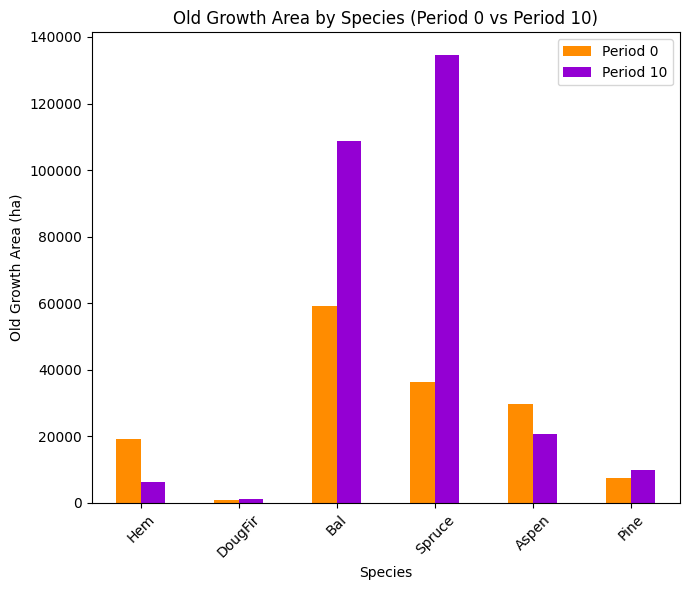

Clustered column plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.7592
Shannon Evenness Index for time period 10: 0.7128

Diversity has **decreased** by 4.64% from time 0 to time 10.


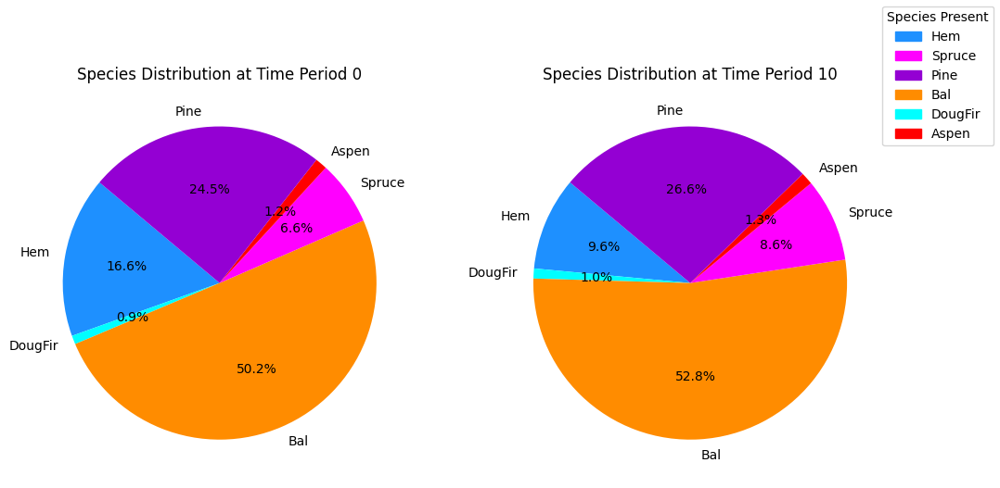

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_bau_eqtslvr_species_pie.pdf


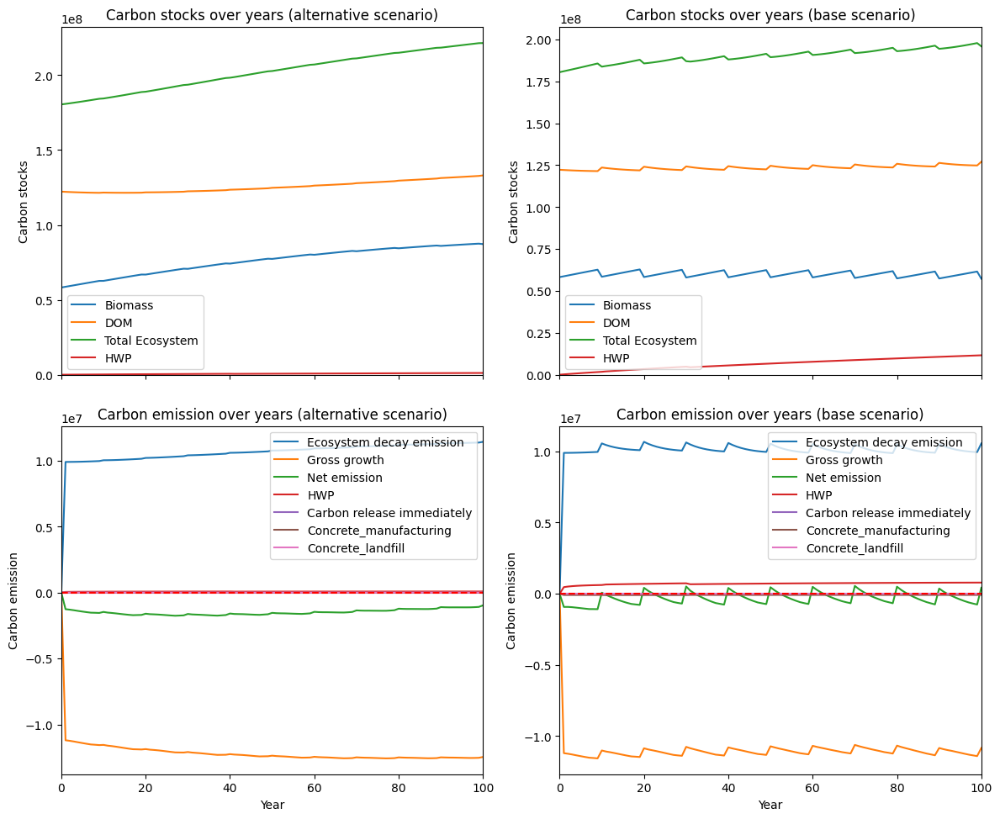

---------------------------------------------------------------------------------------
Net emission difference -24145357.233963113
Net emission base scenario -37315897.91216293
Net emission alternative scenario -13170540.67819982
dollar_per_ton is:  0.4141582956550295
Comparison of Old Growth Areas (Alternative - Base)
           0            10    Difference
Hem      0.0  26409.408269  26409.408269
DougFir  0.0   1436.832154   1436.832154
Bal      0.0  48878.362933  48878.362933
Spruce   0.0  63165.398342  63165.398342
Aspen    0.0  56678.030289  56678.030289
Pine     0.0  60688.936790  60688.936790

Overall, the old growth area has **increased** by 257256.97 hectares in the alternative scenario compared to the base scenario.


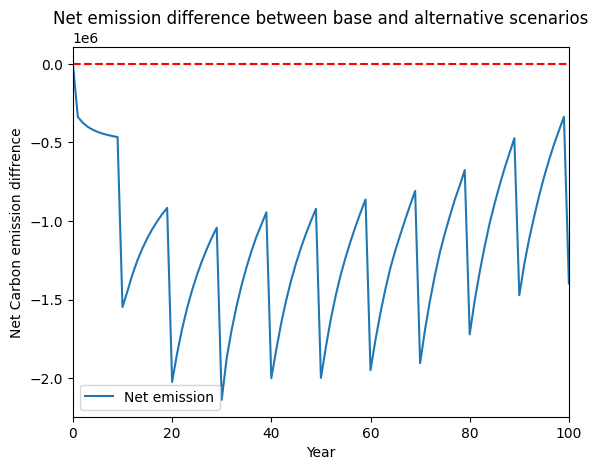

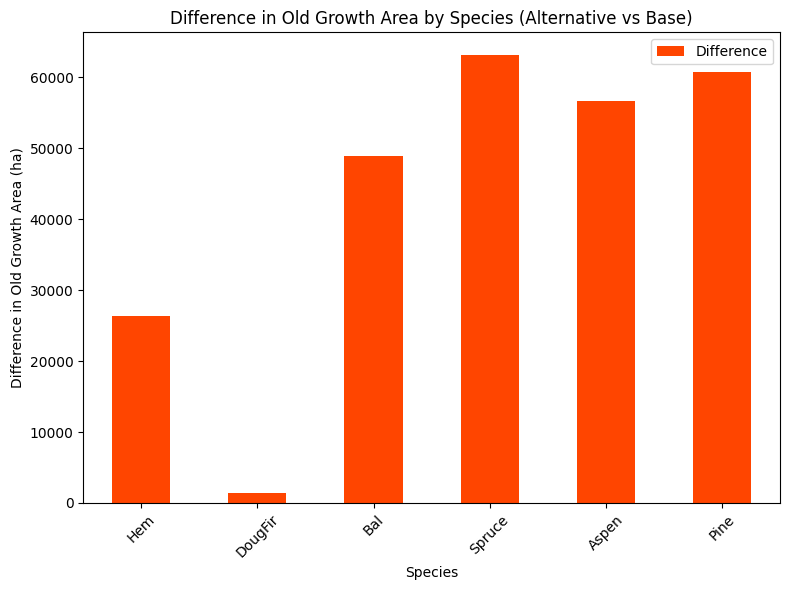

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_age_difference.pdf


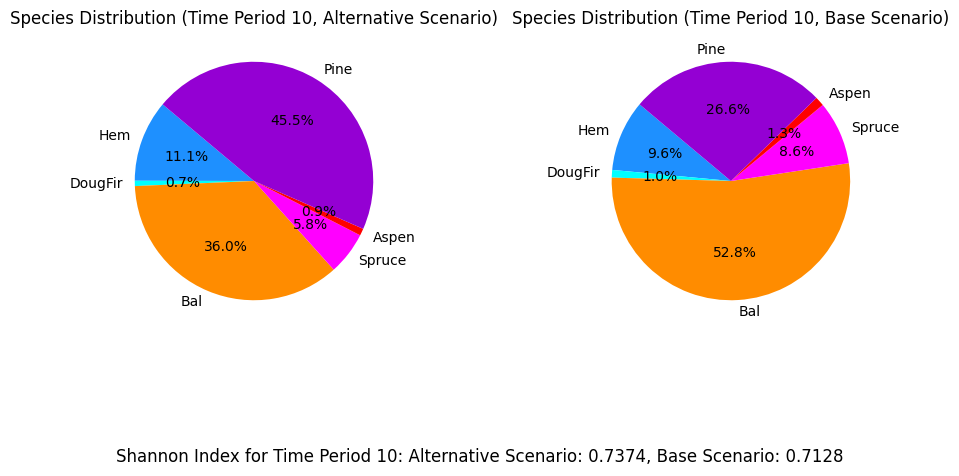

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/equitysilver/equitysilver_min_em_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
It took 154.7 minutes to run all scenarios.


In [12]:
Start = time.time()
scenario_names = ['eqtslvr_AAC_50%', 'eqtslvr_AAC_40%', 'eqtslvr_AAC_30%', 'eqtslvr_AAC_20%', 'eqtslvr_AAC_10%']
for scenario_name in scenario_names:
    print(f"Running for {case_study}_{obj_mode}_{scenario_name}...")
    results_scenarios(fm, 
                      clt_percentage, 
                      credibility, 
                      budget_input, 
                      n_steps, 
                      max_harvest, 
                      scenario_name, 
                      displacement_effect, 
                      hwp_pool_effect_value, 
                      release_immediately_value, 
                      case_study, 
                      obj_mode,                   
                      pickle_output_base=False, 
                      pickle_output_alter=False)
print('It took', round((time.time() - Start) / 60, 1), "minutes to run all scenarios.")

In [13]:
print('It took', round((time.time() - Start) / 60, 1), "minutes to run this script.")

It took 154.7 minutes to run this script.
